# 04 · Derivatives, Gradients & Gradient Descent: the Bridge to Linear Regression
*AI Foundations · Notebook 04 of 19*

Almost every machine-learning model is trained the same way: write down one number that measures
how wrong the model is (the **loss**), then nudge the model's parameters "downhill" until that number
is as small as you can make it. This notebook builds that machinery from the ground up:
derivatives, numerical differentiation, gradients, the chain rule and **gradient descent**, and then
uses it to train a multivariate **linear regression** from scratch, including the practical details
(feature scaling, convergence, interpreting coefficients, multicollinearity) that decide whether
training actually works.

**What you will learn**
- How "draw the best line through the points" becomes an *optimization problem* with a loss function (MSE, MAE).
- Derivatives: secant → tangent, the limit definition, derivatives from first principles, the power/product/quotient/chain rules, and a table of the derivatives used in ML (exp, log, sigmoid, ...).
- Numerical differentiation: forward vs central differences, truncation vs round-off error, choosing the step $h$, gradient checking.
- Optimization basics: critical points, the first- and second-derivative tests, local vs global minima, convexity, saddle points.
- Gradient descent: where the update rule comes from (Taylor expansion), why the negative gradient is the steepest direction (Cauchy–Schwarz), an *exact* analysis of the learning rate, stopping rules, ill-conditioning, feature scaling and momentum.
- The chain rule, computational graphs and backpropagation by hand, verified with PyTorch autograd.
- When gradient descent struggles: kinks, vertical tangents, jumps and multiple minima.
- Linear regression as optimization: MSE gradients (scalar and vector form), convexity, the normal equation, z-score scaling, converting coefficients back to original units, batch vs per-sample updates, and a multicollinearity case study with the variance inflation factor.

**Prerequisites:** Python, NumPy arrays and basic matplotlib, and high-school algebra (functions, graphs,
exponents, logarithms, vectors and the dot product). **No calculus is assumed**: we build what we need.
**Estimated time:** ~6 h

**How to use this notebook:** run cells top to bottom (Runtime → Run all works).
Exercises are marked ✏️, and each has an automatic checker and a hidden solution
(click "Solution" to expand). Quick-check questions have hidden answers.

**Contents**
1. From scattered points to an optimization problem
2. Derivatives: the mathematics of slope
3. Numerical differentiation
4. Optimization basics in one variable
5. Gradient descent in one dimension
6. Many variables: partial derivatives, gradients and gradient descent in 2D
7. The chain rule, computational graphs and backpropagation
8. When gradient descent struggles: tricky objectives
9. Linear regression as an optimization problem
10. Practical: multivariate linear regression from scratch
11. Case study: multicollinearity
12. Quiz
13. Summary and formula sheet
14. Going further

In [1]:
# Setup: imports, reproducibility, plotting style, a tiny test harness
import importlib
import math
import platform
import random
import subprocess
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from IPython.display import display
import sklearn
import statsmodels
import torch


def ensure(pkg: str, import_name: str | None = None):
    """Import a package, installing it with pip first if it is missing."""
    name = import_name or pkg
    try:
        return importlib.import_module(name)
    except ImportError:
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", pkg])
        return importlib.import_module(name)


sp = ensure("sympy")          # symbolic math, used to double-check derivatives by hand

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
rng = np.random.default_rng(SEED)
torch.manual_seed(SEED)

plt.rcParams.update({
    "figure.dpi": 100, "savefig.dpi": 100, "figure.figsize": (7, 4),
    "axes.grid": True, "grid.alpha": 0.3, "axes.spines.top": False, "axes.spines.right": False,
    "font.size": 11,
})
pd.set_option("display.precision", 4)

# Every dataset in this notebook is generated in code, so nothing is downloaded.
DATA_DIR = Path("data")

print(f"Python {platform.python_version()} | numpy {np.__version__} | pandas {pd.__version__} | "
      f"matplotlib {matplotlib.__version__}")
print(f"sympy {sp.__version__} | scikit-learn {sklearn.__version__} | statsmodels {statsmodels.__version__} | "
      f"torch {torch.__version__}")


def run_check(name, test_fn):
    """Run test_fn() and print a friendly status instead of crashing the notebook."""
    try:
        test_fn()
    except NotImplementedError:
        print(f"⏳ {name}: not implemented yet. Fill in the function and re-run this cell.")
    except AssertionError as err:
        print(f"❌ {name}: {err}")
    else:
        print(f"✅ {name}: all checks passed!")

Python 3.13.15 | numpy 2.5.3 | pandas 2.3.3 | matplotlib 3.11.2
sympy 1.14.0 | scikit-learn 1.9.1 | statsmodels 0.15.0 | torch 2.14.1+cu130


## 1. From scattered points to an optimization problem

### 1.1 A line through data: the easy case and the real case

A school cafe sells iced drinks. On eight days the manager wrote down the day's maximum temperature
(in °C) and how many iced drinks were sold. She wants a simple rule

$$
\text{drinks} \approx w \cdot \text{temperature} + b
$$

so she can decide how much ice to order when tomorrow's forecast says 26 °C. In machine-learning
language:

- $x$ is the **feature** (input), here the temperature, and $y$ is the **target** (label), here the drinks sold.
- $\hat y = wx + b$ is the **model's prediction** ("y-hat"). The two numbers $w$ (the **weight** or slope) and
  $b$ (the **bias** or intercept) are the **parameters** we must choose.

If all points lay exactly on one line, the problem would be trivial: any two points $(x_1, y_1)$ and
$(x_2, y_2)$ determine the line,

$$
w = \frac{y_2 - y_1}{x_2 - x_1}, \qquad b = y_1 - w\,x_1 .
$$

Real data never lies on a line. Let's see what happens if we try the two-point recipe anyway.

In [2]:
temp = np.array([15, 18, 20, 23, 25, 28, 30, 33], dtype=float)    # x: max temperature (°C)
drinks = np.array([28, 35, 33, 46, 50, 55, 63, 66], dtype=float)  # y: iced drinks sold
display(pd.DataFrame({"temperature (°C)": temp, "iced drinks": drinks}).T)


def line_through(p, q):
    """Slope and intercept of the straight line through points p=(x1, y1) and q=(x2, y2)."""
    (x1, y1), (x2, y2) = p, q
    w = (y2 - y1) / (x2 - x1)
    return w, y1 - w * x1


w_fl, b_fl = line_through((temp[0], drinks[0]), (temp[-1], drinks[-1]))
print(f"Line through the first and last day: w = {w_fl:.4f}, b = {b_fl:.4f} "
      f"-> forecast for 26 °C: {w_fl * 26 + b_fl:.2f} drinks")

from itertools import combinations
pair_lines = [line_through((temp[i], drinks[i]), (temp[j], drinks[j]))
              for i, j in combinations(range(len(temp)), 2)]
slopes = np.array([w for w, _ in pair_lines])
forecasts = np.array([w * 26 + b for w, b in pair_lines])
print(f"{len(pair_lines)} pairs of points give {len(pair_lines)} different lines:")
print(f"  slopes range from {slopes.min():.2f} to {slopes.max():.2f} drinks per °C")
print(f"  forecasts for 26 °C range from {forecasts.min():.1f} to {forecasts.max():.1f} drinks")

,0,1,2,3,4,5,6,7
temperature (°C),15.0,18.0,20.0,23.0,25.0,28.0,30.0,33.0
iced drinks,28.0,35.0,33.0,46.0,50.0,55.0,63.0,66.0


Line through the first and last day: w = 2.1111, b = -3.6667 -> forecast for 26 °C: 51.22 drinks
28 pairs of points give 28 different lines:
  slopes range from -1.00 to 4.33 drinks per °C
  forecasts for 26 °C range from 27.0 to 59.0 drinks


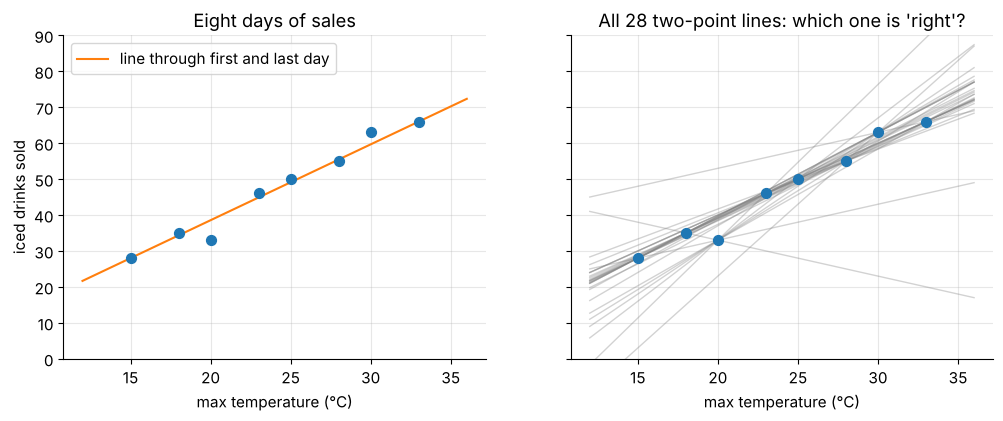

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), sharey=True)
xs_plot = np.linspace(12, 36, 2)
axes[0].scatter(temp, drinks, s=50, zorder=3)
axes[0].plot(xs_plot, w_fl * xs_plot + b_fl, color="C1", label="line through first and last day")
axes[0].set(title="Eight days of sales", xlabel="max temperature (°C)", ylabel="iced drinks sold")
axes[0].legend(loc="upper left")
for w, b in pair_lines:
    axes[1].plot(xs_plot, w * xs_plot + b, color="gray", alpha=0.35, lw=1)
axes[1].scatter(temp, drinks, s=50, zorder=3)
axes[1].set(title="All 28 two-point lines: which one is 'right'?", xlabel="max temperature (°C)",
            ylim=(0, 90))
plt.show()

Twenty-eight lines, twenty-eight different answers, even a line with a *negative* slope. Picking one
"by eye" is not a method. We need an **objective number that scores how badly a line fits the data**,
and then a procedure that finds the line with the best score.

### 1.2 Measuring "how wrong": residuals and loss functions

For data point $i$ (with $i = 1, \dots, m$, and here $m = 8$), the **residual** is the vertical miss

$$
r_i = y_i - \hat y_i = y_i - (w x_i + b).
$$

A positive residual means the point lies above the line. Let's score four candidate lines:

| line | rule | idea |
|---|---|---|
| A | $\hat y = 2x - 2$ | a reasonable guess |
| B | $\hat y = 2.5x - 10$ | steeper |
| C | $\hat y = 1.5x + 12$ | flatter |
| D | $\hat y = 47$ | flat line at the average sales $\bar y = 47$ |

First, line A by hand (every column is simple arithmetic):

In [4]:
candidates = {"A": (2.0, -2.0), "B": (2.5, -10.0), "C": (1.5, 12.0), "D": (0.0, drinks.mean())}

w_A, b_A = candidates["A"]
yhat_A = w_A * temp + b_A
res_A = drinks - yhat_A
display(pd.DataFrame({"x": temp, "y": drinks, "ŷ = 2x − 2": yhat_A, "residual r": res_A,
                      "|r|": np.abs(res_A), "r²": res_A**2}))
print(f"sum of residuals = {res_A.sum():.1f},  mean |r| = {np.abs(res_A).mean():.3f},  "
      f"mean r² = {(res_A**2).mean():.3f}")

,x,y,ŷ = 2x − 2,residual r,|r|,r²
0,15.0,28.0,28.0,0.0,0.0,0.0
1,18.0,35.0,34.0,1.0,1.0,1.0
2,20.0,33.0,38.0,-5.0,5.0,25.0
3,23.0,46.0,44.0,2.0,2.0,4.0
4,25.0,50.0,48.0,2.0,2.0,4.0
5,28.0,55.0,54.0,1.0,1.0,1.0
6,30.0,63.0,58.0,5.0,5.0,25.0
7,33.0,66.0,64.0,2.0,2.0,4.0


sum of residuals = 8.0,  mean |r| = 2.250,  mean r² = 8.000


Three natural ways to turn the column of residuals into a single score:

- **Sum of residuals** $\sum_i r_i$: tempting, but positive and negative misses cancel.
- **Mean absolute error** $\text{MAE} = \frac1m \sum_i |r_i|$.
- **Mean squared error** $\text{MSE} = \frac1m \sum_i r_i^2$ (and its square root, RMSE, which has the units of $y$).

In [5]:
def scores(w, b, x=temp, y=drinks):
    """Return (sum of residuals, MAE, MSE) of the line y = w x + b on data (x, y)."""
    r = y - (w * x + b)
    return r.sum(), np.abs(r).mean(), (r**2).mean()


table = pd.DataFrame([(name, w, b, *scores(w, b)) for name, (w, b) in candidates.items()],
                     columns=["line", "w", "b", "sum of residuals", "MAE", "MSE"]).set_index("line")
display(table)

,w,b,sum of residuals,MAE,MSE
line,,,,,
A,2.0,-2.0,8.0,2.250,8.000
B,2.5,-10.0,-24.0,3.125,16.125
C,1.5,12.0,-8.0,4.000,24.625
D,0.0,47.0,0.0,11.500,174.000


Look at line D, the flat line at the mean: its **sum of residuals is exactly 0**, the "perfect" score,
even though it ignores temperature completely and has by far the worst MAE and MSE. The plain sum is
useless because errors cancel. Both MAE and MSE rank the lines sensibly: A < B < C < D.

> **Key idea.** A **loss function** turns "how wrong is this model on the data?" into one number.
> For the line $\hat y = wx + b$ the mean squared error is a function of the parameters:
> $$
> J(w, b) = \frac{1}{m}\sum_{i=1}^{m}\big(w x_i + b - y_i\big)^2 .
> $$
> "Fitting the model" now has a precise meaning: find $(w^*, b^*) = \arg\min_{w,b} J(w,b)$, an
> **optimization problem**.

**Why squared error is the default.**
1. Every miss counts as a positive amount, so nothing cancels.
2. Big misses are punished much more than small ones: one miss of 10 costs 100, two misses of 5 cost only 50.
3. It is **smooth**: it has a derivative everywhere, so the calculus in this notebook applies directly.
   MAE has a sharp corner where a residual is 0 (Section 8 shows why that matters).
4. For a linear model it produces a single bowl-shaped valley (a *convex* function, Section 4.3) with a
   closed-form bottom (Section 9.6).

MAE has its own virtue: it is less sensitive to outliers, because an outlier's penalty grows linearly
rather than quadratically.

> **Going deeper.** If you assume each $y_i$ equals a true line plus Gaussian (normal) noise, then
> minimizing the MSE is exactly the same as choosing the most likely line (*maximum likelihood*).
> Under Laplace-distributed noise the same argument gives the MAE. A later notebook makes this precise.

### 1.3 The loss as a landscape

Because $J$ depends on two numbers, you can picture it as a landscape over the $(w, b)$ plane: every
candidate line is a location, and $J$ is the altitude there. Below, the left panel slices the landscape
along $w$ (with $b$ held at its best value), the right panel shows the contour map (curves of equal
loss, like the height lines of a hiking map) with candidates A–C, and line D, at $w = 0$, lies off the map.
The best line itself, $(w^*, b^*)$, is computed here with `np.polyfit` as a black box, and by Section 9
you will derive it yourself.

best line (least squares): w* = 2.2463, b* = -6.9104, MSE = 4.9683


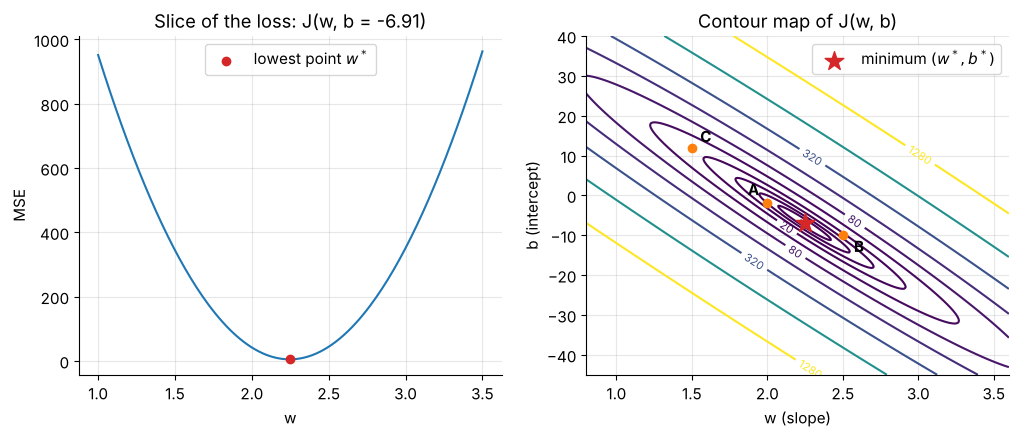

In [6]:
w_star, b_star = np.polyfit(temp, drinks, deg=1)
print(f"best line (least squares): w* = {w_star:.4f}, b* = {b_star:.4f}, MSE = {scores(w_star, b_star)[2]:.4f}")

W, B = np.meshgrid(np.linspace(0.8, 3.6, 300), np.linspace(-45, 40, 300))
J_grid = ((W[..., None] * temp + B[..., None] - drinks) ** 2).mean(axis=-1)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.4))
w_line = np.linspace(1.0, 3.5, 200)
axes[0].plot(w_line, [scores(w, b_star)[2] for w in w_line])
axes[0].scatter([w_star], [scores(w_star, b_star)[2]], color="C3", zorder=3, label="lowest point $w^*$")
axes[0].set(title=f"Slice of the loss: J(w, b = {b_star:.2f})", xlabel="w", ylabel="MSE")
axes[0].legend()
levels = [5, 6, 8, 12, 20, 40, 80, 160, 320, 640, 1280]
cs = axes[1].contour(W, B, J_grid, levels=levels, cmap="viridis")
axes[1].clabel(cs, levels=[20, 80, 320, 1280], fontsize=8, fmt="%g")
for (name, (w, b)), offset in zip(list(candidates.items())[:3], [(-14, 6), (8, -12), (6, 4)]):
    axes[1].scatter(w, b, color="C1", zorder=3)
    axes[1].annotate(name, (w, b), textcoords="offset points", xytext=offset, fontweight="bold")
axes[1].scatter([w_star], [b_star], marker="*", s=200, color="C3", zorder=3, label="minimum $(w^*, b^*)$")
axes[1].set(title="Contour map of J(w, b)", xlabel="w (slope)", ylabel="b (intercept)")
axes[1].legend(loc="upper right")
plt.show()

Three things to notice, and they set the agenda for the rest of the notebook:

1. The landscape has **one valley floor**. Fitting the line = walking to the bottom of the valley.
2. To walk downhill you need to know, at your current location, **which way is down and how steep it is**.
   That is exactly what a *derivative* (one variable) or a *gradient* (several variables) tells you
   (Sections 2 and 6), and "repeatedly step downhill" is *gradient descent* (Sections 5–6).
3. The valley is **extremely long and narrow**: the temperatures sit around 24 °C, far from 0, so
   increasing $w$ while decreasing $b$ (pivoting the line around the cloud of points) barely changes
   the fit. Such stretched valleys make gradient descent painfully slow (Section 6.6), and **feature
   scaling** cures them (Sections 6.7, 9.7 and 10.5).

**Quick check.** Line D (flat at the mean) has residual sum exactly 0. Is that a coincidence of this
dataset? Is it the *only* line with residual sum 0?

<details>
<summary>Answer</summary>

Not a coincidence: $\sum_i (y_i - \bar y) = \sum_i y_i - m\bar y = 0$ for any data. And it is far from
the only one: for *any* slope $w$, the line through the centroid $(\bar x, \bar y)$, i.e.
$b = \bar y - w\bar x$, has $\sum_i \big(y_i - \bar y - w(x_i - \bar x)\big) = 0 - w\cdot 0 = 0$.
Infinitely many lines tie for the "best" score, which is another reason the plain sum cannot be a loss.
</details>

## 2. Derivatives: the mathematics of slope

### 2.1 Average rate of change and the secant line

A cup of coffee is poured at 90 °C into a 20 °C room. A good model of its temperature after $t$ minutes is

$$
T(t) = 20 + 70\,e^{-0.1 t} \quad (^\circ\mathrm{C}).
$$

How fast is it cooling? Over a time interval from $t_1$ to $t_2$ the **average rate of change** is

$$
\frac{\Delta T}{\Delta t} = \frac{T(t_2) - T(t_1)}{t_2 - t_1} \qquad \text{(units: } ^\circ\mathrm{C} \text{ per minute)}.
$$

Over the first ten minutes: $\big(T(10) - T(0)\big)/10 \approx (45.75 - 90)/10 = -4.42$ °C/min. The
minus sign says the temperature *drops*. Geometrically, this number is the slope of the **secant line**,
the straight line through the two points $(t_1, T(t_1))$ and $(t_2, T(t_2))$ on the graph. Rates of change
are everywhere: speed (km per hour), the growth of a bacterial population (cells per hour), the extra
revenue from one more unit sold (dollars per unit), and, for us, **how fast the loss changes when a
parameter changes** (loss units per parameter unit).

But an average over ten minutes hides what happens at any particular moment. A speedometer shows your
speed *right now*, not the trip average. What is the cooling rate at exactly $t = 5$?

### 2.2 From secant to tangent: the limit

Keep one point fixed at $a = 5$ and slide the second point $a + h$ towards it. Each $h$ gives a secant
with slope

$$
\frac{T(a+h) - T(a)}{h}.
$$

Watch what happens to these slopes as $h$ shrinks:

In [7]:
def T_coffee(t):
    """Coffee temperature (°C) after t minutes."""
    return 20 + 70 * np.exp(-0.1 * t)


a = 5.0
dT_exact = -7 * np.exp(-0.1 * a)          # the exact answer, derived in Section 2.6
print(f"T(0) = {T_coffee(0):.2f}, T(10) = {T_coffee(10):.2f}, "
      f"average rate on [0, 10] = {(T_coffee(10) - T_coffee(0)) / 10:.4f} °C/min")
rows = []
for h in [8, 4, 2, 1, 0.5, 0.1, 0.01, 0.001]:
    slope = (T_coffee(a + h) - T_coffee(a)) / h
    rows.append((h, slope, slope - dT_exact))
display(pd.DataFrame(rows, columns=["h", "secant slope", "slope − limit"]).set_index("h"))
print(f"The slopes approach {dT_exact:.4f} °C/min (the instantaneous cooling rate at t = 5).")

T(0) = 90.00, T(10) = 45.75, average rate on [0, 10] = -4.4248 °C/min


,secant slope,slope − limit
h,,
8.000,-2.9225,1.3232
4.000,-3.4993,0.7464
2.000,-3.8481,0.3976
1.000,-4.0403,0.2054
0.500,-4.1413,0.1044
0.100,-4.2246,0.0212
0.010,-4.2436,0.0021
0.001,-4.2455,0.0002


The slopes approach -4.2457 °C/min (the instantaneous cooling rate at t = 5).


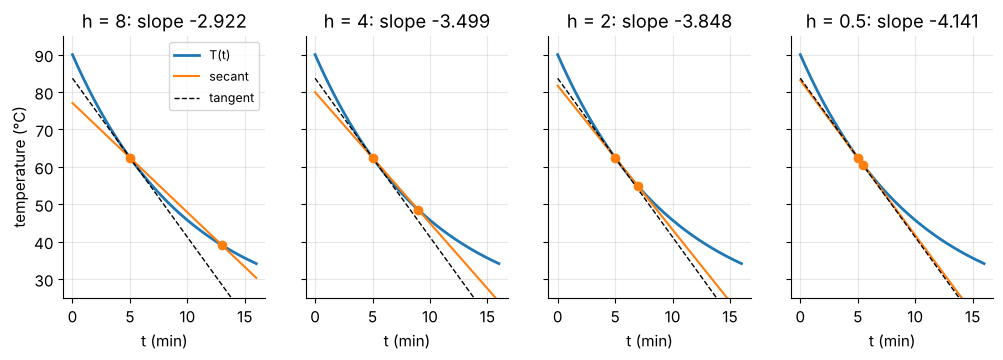

In [8]:
fig, axes = plt.subplots(1, 4, figsize=(12, 3.4), sharey=True)
t_plot = np.linspace(0, 16, 200)
tangent = T_coffee(a) + dT_exact * (t_plot - a)
for ax, h in zip(axes, [8, 4, 2, 0.5]):
    slope = (T_coffee(a + h) - T_coffee(a)) / h
    ax.plot(t_plot, T_coffee(t_plot), lw=2, label="T(t)")
    ax.plot(t_plot, T_coffee(a) + slope * (t_plot - a), color="C1", label="secant")
    ax.plot(t_plot, tangent, "k--", lw=1, label="tangent")
    ax.scatter([a, a + h], [T_coffee(a), T_coffee(a + h)], color="C1", zorder=3)
    ax.set(title=f"h = {h}: slope {slope:.3f}", xlabel="t (min)", ylim=(25, 95))
axes[0].set_ylabel("temperature (°C)")
axes[0].legend(loc="upper right", fontsize=9)
plt.show()

As $h$ shrinks, the secant **rotates into the tangent line** (the line that just touches the curve at
$t = 5$), and the slopes settle on one number, $-4.2457$ °C/min. Notice also that the error column
roughly halves when $h$ halves, and we will explain that pattern in Section 3.

> **Key idea (definition of the derivative).** The derivative of $f$ at $a$ is the limit of secant slopes
> $$
> f'(a) = \lim_{h \to 0} \frac{f(a+h) - f(a)}{h},
> $$
> provided this limit exists as a finite number (the same value whether $h$ approaches 0 from the
> positive or the negative side). It is the **slope of the tangent line** at $a$, i.e. the
> **instantaneous rate of change** of $f$ at $a$.

Notation: $f'(a)$, $\frac{df}{dx}\big|_{x=a}$ or $\frac{dy}{dx}$ (Leibniz's notation, which reminds you
that it is a limit of $\Delta y / \Delta x$). The function $x \mapsto f'(x)$ is called the **derivative
function**, and computing it is called **differentiation**.

The tangent line at $a$ is $y = f(a) + f'(a)(x - a)$. Its real power is as an approximation:

$$
f(a + h) \approx f(a) + f'(a)\,h \qquad \text{for small } h.
$$

This **linear approximation** says: *if you zoom in far enough, a smooth curve looks like a straight
line*. Let's zoom in on the coffee curve and see it happen.

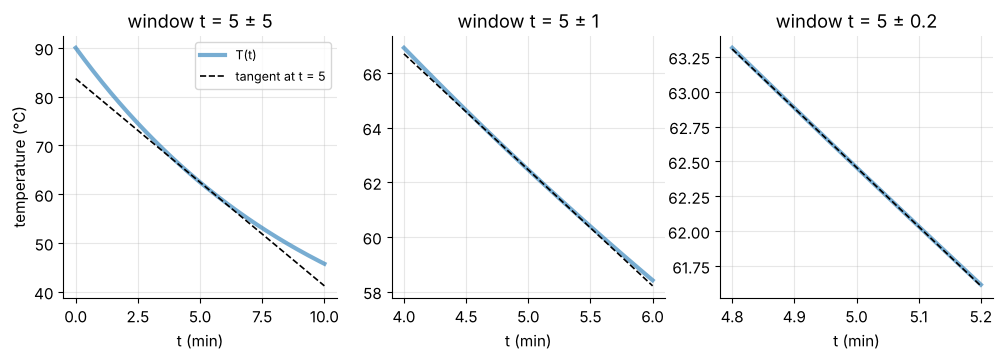

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.4))
for ax, half_width in zip(axes, [5, 1, 0.2]):
    tt = np.linspace(a - half_width, a + half_width, 200)
    ax.plot(tt, T_coffee(tt), lw=3, alpha=0.6, label="T(t)")
    ax.plot(tt, T_coffee(a) + dT_exact * (tt - a), "k--", lw=1.2, label="tangent at t = 5")
    ax.set(title=f"window t = 5 ± {half_width}", xlabel="t (min)")
axes[0].set_ylabel("temperature (°C)")
axes[0].legend(fontsize=9)
plt.show()

In the widest window the curve visibly bends away from the tangent, while in the narrowest one they are
indistinguishable. This "local linearity" is the single most important idea behind gradient descent:
**near the point where you stand, the function behaves like its tangent line, so the tangent tells you
which way is downhill.**

### 2.3 Derivatives from the definition

Let's compute some derivatives directly from the limit. The trick each time is the same: simplify the
difference quotient algebraically until $h$ can be set to 0 without dividing by zero.

**(a) Constant and linear functions.** For $f(x) = c$: $\frac{c - c}{h} = 0$, so $f'(x) = 0$ (a flat
line has slope 0). For $f(x) = mx + q$: $\frac{m(x+h) + q - mx - q}{h} = m$, so $f'(x) = m$ (a line has
the same slope everywhere).

**(b) $f(x) = x^2$.**

$$
\frac{(x+h)^2 - x^2}{h} = \frac{x^2 + 2xh + h^2 - x^2}{h} = \frac{2xh + h^2}{h} = 2x + h \;\xrightarrow{h \to 0}\; 2x .
$$

At $x = 3$ the difference quotient is *exactly* $6 + h$: for $h = 0.1$ it is $6.1$, for $h = 0.01$ it is
$6.01$, for $h = -0.01$ it is $5.99$. The limit is $f'(3) = 6$.

**(c) $f(x) = x^3$.** Using $(x+h)^3 = x^3 + 3x^2h + 3xh^2 + h^3$:

$$
\frac{(x+h)^3 - x^3}{h} = 3x^2 + 3xh + h^2 \;\xrightarrow{h \to 0}\; 3x^2 .
$$

**(d) $f(x) = 1/x$** (for $x \neq 0$). Put the two fractions over a common denominator:

$$
\frac{1}{h}\left(\frac{1}{x+h} - \frac{1}{x}\right) = \frac{1}{h}\cdot\frac{x - (x+h)}{x(x+h)}
= \frac{-1}{x(x+h)} \;\xrightarrow{h \to 0}\; -\frac{1}{x^2}.
$$

**(e) $f(x) = \sqrt{x}$** (for $x > 0$). Multiply top and bottom by the "conjugate" $\sqrt{x+h} + \sqrt{x}$:

$$
\frac{\sqrt{x+h} - \sqrt{x}}{h}\cdot\frac{\sqrt{x+h} + \sqrt{x}}{\sqrt{x+h} + \sqrt{x}}
= \frac{(x + h) - x}{h\,(\sqrt{x+h} + \sqrt{x})} = \frac{1}{\sqrt{x+h} + \sqrt{x}} \;\xrightarrow{h \to 0}\; \frac{1}{2\sqrt{x}} .
$$

**(f) $f(x) = e^x$.** Using $e^{x+h} = e^x e^h$:

$$
\frac{e^{x+h} - e^x}{h} = e^x \cdot \frac{e^h - 1}{h} \;\xrightarrow{h \to 0}\; e^x \cdot 1 = e^x ,
$$

because $(e^h - 1)/h \to 1$. In fact, $e \approx 2.71828$ is *defined* as the base for which this
limit equals 1, which is what makes $e^x$ its own derivative. Let's check that limit numerically, and
then check all of our formulas against tiny-$h$ difference quotients.

In [10]:
print("(e^h - 1)/h for shrinking h:")
for h in [1, 0.1, 0.01, 0.001, 1e-4]:
    print(f"  h = {h:<7g} -> {(np.exp(h) - 1) / h:.6f}")

x0, h = 2.0, 1e-6
checks = {
    "x^2  -> 2x":         (lambda x: x**2,       lambda x: 2 * x),
    "x^3  -> 3x^2":       (lambda x: x**3,       lambda x: 3 * x**2),
    "1/x  -> -1/x^2":     (lambda x: 1 / x,      lambda x: -1 / x**2),
    "sqrt(x) -> 1/(2 sqrt x)": (np.sqrt,         lambda x: 1 / (2 * np.sqrt(x))),
    "e^x  -> e^x":        (np.exp,               np.exp),
}
print(f"\nDifference quotient with h = {h:g} at x = {x0} vs the formula:")
for name, (f, fprime) in checks.items():
    quotient = (f(x0 + h) - f(x0)) / h
    print(f"  {name:25s} quotient = {quotient:.6f}   formula = {fprime(x0):.6f}")

(e^h - 1)/h for shrinking h:
  h = 1       -> 1.718282
  h = 0.1     -> 1.051709
  h = 0.01    -> 1.005017
  h = 0.001   -> 1.000500
  h = 0.0001  -> 1.000050

Difference quotient with h = 1e-06 at x = 2.0 vs the formula:
  x^2  -> 2x                quotient = 4.000001   formula = 4.000000
  x^3  -> 3x^2              quotient = 12.000006   formula = 12.000000
  1/x  -> -1/x^2            quotient = -0.250000   formula = -0.250000
  sqrt(x) -> 1/(2 sqrt x)   quotient = 0.353553   formula = 0.353553
  e^x  -> e^x               quotient = 7.389060   formula = 7.389056


### 2.4 What the sign (and size) of the derivative tells you

Take $f(x) = \frac{x^3}{3} - x^2 - 3x + 2$. With the rules of the next subsection (or the results above),
$f'(x) = x^2 - 2x - 3 = (x + 1)(x - 3)$.

- Where $f'(x) > 0$ the graph goes **uphill** as you move right: $f$ is *increasing* (here for $x < -1$ and $x > 3$).
- Where $f'(x) < 0$ it goes **downhill**: $f$ is *decreasing* (here for $-1 < x < 3$).
- Where $f'(x) = 0$ the tangent is **horizontal** (here at $x = -1$ and $x = 3$): candidates for peaks and valleys.
- The **size** $|f'(x)|$ says how steep: at $x = -2$ the slope is $5$, at $x = 1$ it is $-4$, at $x = 2.9$ only $-0.39$.

| $x$ | $f'(x)$ | meaning |
|---|---|---|
| $-2$ | $5$ | uphill, steep |
| $0$ | $-3$ | downhill |
| $1$ | $-4$ | downhill, steepest descent of this stretch |
| $3$ | $0$ | flat: bottom of a valley |
| $4$ | $5$ | uphill again |

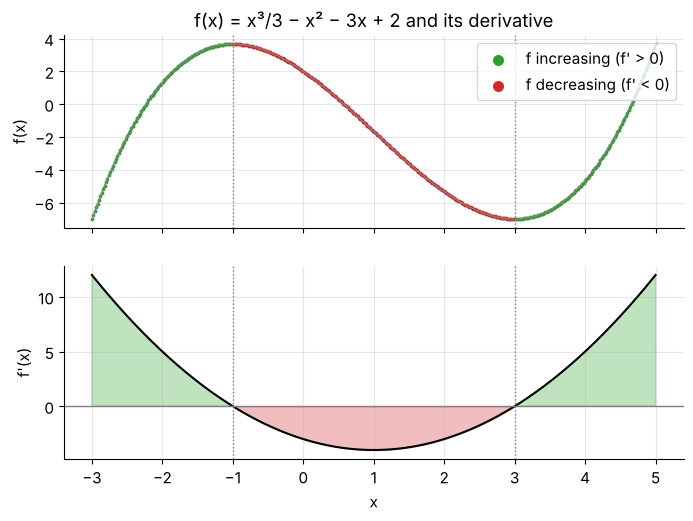

In [11]:
def f_cubic(x):
    return x**3 / 3 - x**2 - 3 * x + 2


def df_cubic(x):
    return x**2 - 2 * x - 3


xx = np.linspace(-3, 5, 400)
fig, axes = plt.subplots(2, 1, figsize=(8, 5.5), sharex=True)
inc = df_cubic(xx) > 0
axes[0].plot(xx, f_cubic(xx), color="gray", lw=1)
axes[0].scatter(xx[inc], f_cubic(xx[inc]), s=3, color="C2", label="f increasing (f' > 0)")
axes[0].scatter(xx[~inc], f_cubic(xx[~inc]), s=3, color="C3", label="f decreasing (f' < 0)")
axes[0].set(title="f(x) = x³/3 − x² − 3x + 2 and its derivative", ylabel="f(x)")
axes[0].legend(markerscale=4)
axes[1].plot(xx, df_cubic(xx), color="k")
axes[1].axhline(0, color="gray", lw=1)
axes[1].fill_between(xx, df_cubic(xx), 0, where=inc, color="C2", alpha=0.3)
axes[1].fill_between(xx, df_cubic(xx), 0, where=~inc, color="C3", alpha=0.3)
axes[1].set(xlabel="x", ylabel="f'(x)")
for ax in axes:
    for c in (-1, 3):
        ax.axvline(c, color="gray", ls=":", lw=1)
plt.show()

Read the two panels together: green regions of $f'$ (above zero) line up with the rising parts of $f$,
red regions with the falling parts, and the zeros of $f'$ sit exactly under the peak and the valley.

> **Key idea.** To make $f$ smaller, move $x$ **against the sign of the derivative**: if $f'(x) > 0$,
> decrease $x$, and if $f'(x) < 0$, increase $x$. This one sentence is gradient descent (Section 5).

The derivative of the derivative is the **second derivative** $f''(x)$. It measures how the slope itself
changes: $f'' > 0$ means the slope increases and the graph bends upward like a cup, and $f'' < 0$ means it
bends downward like a cap. Here $f''(x) = 2x - 2$: the curve is a cap left of $x = 1$ and a cup right
of it, which is why the steepest descent happens at $x = 1$.

### 2.5 Differentiation rules (with reasons)

Computing every derivative from the limit would be slow. A handful of rules, each a consequence of the
definition, handles almost everything. Below, $f$ and $g$ are differentiable functions and $c$ is a constant.

| rule | formula | example |
|---|---|---|
| constant multiple & sum | $(c f + g)' = c f' + g'$ | $(5x^2 + x^3)' = 10x + 3x^2$ |
| power | $(x^n)' = n x^{n-1}$ | $(x^7)' = 7x^6$, $(x^{-1})' = -x^{-2}$ |
| product | $(fg)' = f'g + fg'$ | $(x^2 \sin x)' = 2x\sin x + x^2\cos x$ |
| quotient | $\left(\frac{f}{g}\right)' = \frac{f'g - fg'}{g^2}$ | $\left(\frac{x+1}{x^2+1}\right)' = \frac{(x^2+1) - (x+1)\,2x}{(x^2+1)^2}$ |
| chain | $\big(g(f(x))\big)' = g'(f(x))\,f'(x)$ | $\big((3x+1)^5\big)' = 5(3x+1)^4\cdot 3$ |

**Why they are true (short versions).**

- **Sum and constant multiple:** the difference quotient of $cf + g$ is $c$ times the quotient of $f$ plus
  the quotient of $g$, and limits respect sums and constant factors.
- **Power rule:** for a positive integer $n$, the binomial theorem gives
  $(x+h)^n = x^n + n x^{n-1} h + (\text{terms containing } h^2)$, so the quotient is
  $n x^{n-1} + (\text{terms containing } h) \to n x^{n-1}$. The rule holds for every real exponent
  (for $x > 0$), and you already verified $n = -1$ ($1/x$) and $n = \tfrac12$ ($\sqrt x$) in Section 2.3.
- **Product rule:** think of $f(x)\,g(x)$ as the area of a rectangle with sides $f$ and $g$. Nudging $x$
  grows the sides by $\Delta f$ and $\Delta g$:

```
                f                Δf
       +--------------------+---------+
  Δg   |      f · Δg        | Δf · Δg |   <- tiny corner: second order, vanishes
       +--------------------+---------+
       |                    |         |
   g   |      f · g         | g · Δf  |
       |   (old area)       |         |
       +--------------------+---------+
```

  The new area minus the old one is $f\,\Delta g + g\,\Delta f + \Delta f\,\Delta g$. Divide by $\Delta x$
  and let $\Delta x \to 0$: the first two terms give $f g' + g f'$, while the corner
  $\Delta f\,\Delta g / \Delta x = (\Delta f/\Delta x)\,\Delta g \to f' \cdot 0 = 0$.
- **Chain rule:** if $u = f(x)$ and $y = g(u)$, then a small change $\Delta x$ causes
  $\Delta u \approx f'(x)\,\Delta x$, which in turn causes $\Delta y \approx g'(u)\,\Delta u \approx g'(u) f'(x)\,\Delta x$.
  **Rates of change multiply**, like gears: if gear B turns 3 times as fast as gear A, and gear C turns
  2 times as fast as gear B, then C turns $2 \times 3 = 6$ times as fast as A. In Leibniz notation
  $\frac{dy}{dx} = \frac{dy}{du}\cdot\frac{du}{dx}$. (Section 7 is devoted to this rule, because
  backpropagation is nothing but the chain rule applied systematically.)
- **Quotient rule:** write $f/g = f \cdot g^{-1}$. By the chain rule $(g^{-1})' = -g^{-2} g'$, and the
  product rule gives $f' g^{-1} - f g^{-2} g' = \frac{f'g - fg'}{g^2}$.

A computer algebra system such as **SymPy** applies these rules mechanically. Let's use it to confirm
the hand-computed examples in the table.

In [12]:
xs = sp.symbols("x")
examples = {
    "power:    x**7":              (xs**7, 7 * xs**6),
    "product:  x**2*sin(x)":       (xs**2 * sp.sin(xs), 2 * xs * sp.sin(xs) + xs**2 * sp.cos(xs)),
    "quotient: (x+1)/(x**2+1)":    ((xs + 1) / (xs**2 + 1), ((xs**2 + 1) - (xs + 1) * 2 * xs) / (xs**2 + 1) ** 2),
    "chain:    (3*x+1)**5":        ((3 * xs + 1) ** 5, 5 * (3 * xs + 1) ** 4 * 3),
    "chain:    exp(-x**2)":        (sp.exp(-xs**2), -2 * xs * sp.exp(-xs**2)),
}
for name, (expr, by_hand) in examples.items():
    auto = sp.diff(expr, xs)
    agrees = sp.simplify(auto - by_hand) == 0
    print(f"{name:28s} sympy says: {str(auto):38s} matches hand result: {agrees}")

power:    x**7               sympy says: 7*x**6                                 matches hand result: True
product:  x**2*sin(x)        sympy says: x**2*cos(x) + 2*x*sin(x)               matches hand result: True


quotient: (x+1)/(x**2+1)     sympy says: -2*x*(x + 1)/(x**2 + 1)**2 + 1/(x**2 + 1) matches hand result: True
chain:    (3*x+1)**5         sympy says: 15*(3*x + 1)**4                        matches hand result: True
chain:    exp(-x**2)         sympy says: -2*x*exp(-x**2)                        matches hand result: True


### 2.6 A table of derivatives you will use constantly

| $f(x)$ | $f'(x)$ | where it shows up in ML |
|---|---|---|
| $c$ (constant) | $0$ | |
| $x^n$ | $n x^{n-1}$ | polynomial features, squared errors |
| $e^x$ | $e^x$ | softmax, exponential growth/decay |
| $a^x$ | $a^x \ln a$ | (since $a^x = e^{x \ln a}$) |
| $\ln x$ | $1/x$ | log-likelihoods, cross-entropy |
| $\log_a x$ | $\frac{1}{x \ln a}$ | |
| $\sin x$, $\cos x$ | $\cos x$, $-\sin x$ | positional encodings |
| $\sigma(z) = \frac{1}{1 + e^{-z}}$ | $\sigma(z)\,\big(1 - \sigma(z)\big)$ | logistic regression, neural nets |
| $\tanh z$ | $1 - \tanh^2 z$ | neural nets |
| $\lvert x \rvert$ | $\operatorname{sign}(x)$ for $x \ne 0$ | MAE loss |
| $\mathrm{ReLU}(x) = \max(0, x)$ | $1$ for $x > 0$, $0$ for $x < 0$ | neural nets |

Two derivations worth seeing once:

- **Logarithm.** If $y = \ln x$ then $x = e^{y}$. Differentiate both sides with respect to $x$ using the
  chain rule: $1 = e^{y}\,\frac{dy}{dx}$, so $\frac{dy}{dx} = \frac{1}{e^{y}} = \frac1x$.
- **Sigmoid (a preview of logistic regression).** Write $\sigma(z) = (1 + e^{-z})^{-1}$. Chain rule:

$$
\sigma'(z) = -\big(1 + e^{-z}\big)^{-2}\cdot\big(-e^{-z}\big) = \frac{e^{-z}}{(1 + e^{-z})^2}
= \underbrace{\frac{1}{1 + e^{-z}}}_{\sigma(z)}\cdot\underbrace{\frac{e^{-z}}{1 + e^{-z}}}_{1 - \sigma(z)} .
$$

So the sigmoid's derivative can be computed from the sigmoid's own value, a fact that makes
backpropagation through sigmoids cheap. The coffee derivative from Section 2.2 also follows from the
table: $T'(t) = 70\,e^{-0.1t}\cdot(-0.1) = -7e^{-0.1t}$ (chain rule with inner function $-0.1t$).

Rather than trusting the table, let's test every row numerically at a few points.

Checked 11 rows at x = [0.3 1.  2.5]; largest |numerical − formula| = 9.2e-09


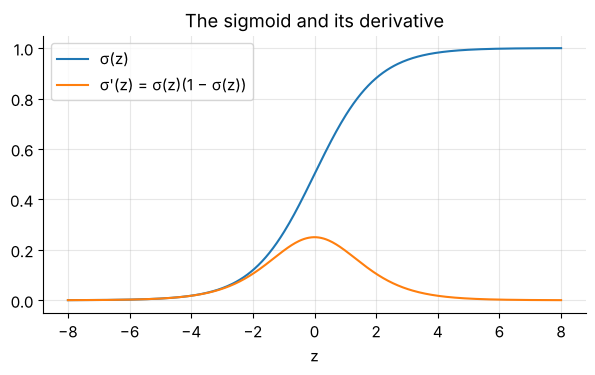

In [13]:
def sigmoid(z):
    return 1.0 / (1.0 + np.exp(-z))


table_rows = {
    "x^4":      (lambda x: x**4,                 lambda x: 4 * x**3),
    "e^x":      (np.exp,                         np.exp),
    "2^x":      (lambda x: 2.0**x,               lambda x: 2.0**x * np.log(2)),
    "ln x":     (np.log,                         lambda x: 1 / x),
    "log10 x":  (np.log10,                       lambda x: 1 / (x * np.log(10))),
    "sin x":    (np.sin,                         np.cos),
    "cos x":    (np.cos,                         lambda x: -np.sin(x)),
    "sigmoid":  (sigmoid,                        lambda x: sigmoid(x) * (1 - sigmoid(x))),
    "tanh":     (np.tanh,                        lambda x: 1 - np.tanh(x) ** 2),
    "|x|":      (np.abs,                         np.sign),
    "ReLU":     (lambda x: np.maximum(0, x),     lambda x: (x > 0).astype(float)),
}
pts = np.array([0.3, 1.0, 2.5])     # positive points, so ln and log10 are defined
h = 1e-6
worst = max(np.max(np.abs((f(pts + h) - f(pts - h)) / (2 * h) - fp(pts))) for f, fp in table_rows.values())
print(f"Checked {len(table_rows)} rows at x = {pts}, largest |numerical − formula| = {worst:.1e}")

zz = np.linspace(-8, 8, 400)
fig, ax = plt.subplots(figsize=(7, 3.6))
ax.plot(zz, sigmoid(zz), label="σ(z)")
ax.plot(zz, sigmoid(zz) * (1 - sigmoid(zz)), label="σ'(z) = σ(z)(1 − σ(z))")
ax.set(title="The sigmoid and its derivative", xlabel="z")
ax.legend()
plt.show()

The sigmoid's slope is at most $0.25$ (at $z = 0$) and almost $0$ for $|z| > 5$: when a sigmoid is
"saturated", tiny derivatives flow back through it. This is the root of the *vanishing-gradient*
problem you will meet with deep networks.

### 2.7 Differentiability: when does the derivative exist?

The limit in the definition does not always exist. A function is **differentiable at $a$** when the
difference quotient has the **same finite limit** whether $h \to 0^+$ (from the right) or
$h \to 0^-$ (from the left). There are three classic ways to fail:

1. **A corner (kink)**, $f(x) = |x|$ at $0$: the quotient is $|h|/h = +1$ for $h > 0$ and $-1$ for $h < 0$.
   Two different one-sided limits, so no derivative.
2. **A vertical tangent**, $f(x) = \sqrt[3]{x}$ at $0$: the quotient is $h^{1/3}/h = h^{-2/3} \to +\infty$
   from both sides. The tangent line exists but is vertical, and "infinite slope" is not a number.
   (The power rule agrees: $f'(x) = \frac13 x^{-2/3} = \frac{1}{3\sqrt[3]{x^2}}$, which blows up as $x \to 0$.)
   Everywhere else ($x \ne 0$) the cube root is perfectly differentiable.
3. **A jump**, the step function $H(x) = 1$ for $x \ge 0$, $H(x) = 0$ for $x < 0$, at $0$: from the right
   the quotient is $(1 - 1)/h = 0$, from the left it is $(0 - 1)/h = 1/|h| \to \infty$.

|x|             cube root              step H(x)           
           from right from left  from right   from left from right  from left
h                                                                            
1.0000e-01        1.0      -1.0      4.6416      4.6416        0.0       10.0
1.0000e-03        1.0      -1.0    100.0000    100.0000        0.0     1000.0
1.0000e-06        1.0      -1.0  10000.0000  10000.0000        0.0  1000000.0

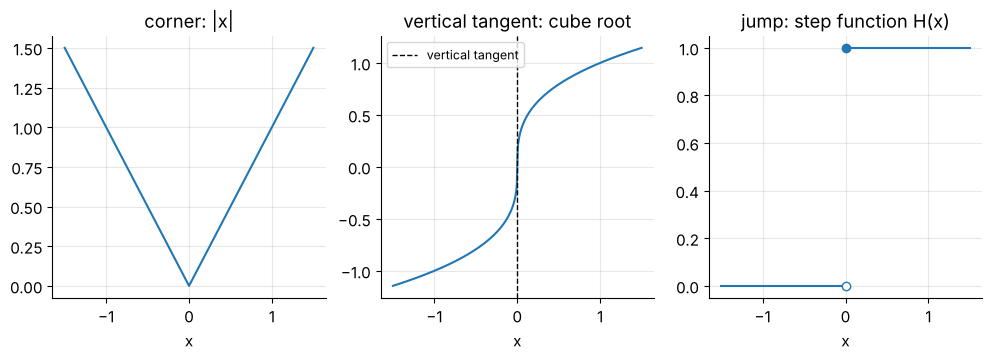

In [14]:
step = lambda x: np.where(x >= 0, 1.0, 0.0)
rows = []
for h in [0.1, 0.001, 1e-6]:
    rows.append((h,
                 (np.abs(h) - 0) / h, (np.abs(-h) - 0) / (-h),
                 np.cbrt(h) / h, np.cbrt(-h) / (-h),
                 (step(h) - step(0.0)) / h, (step(-h) - step(0.0)) / (-h)))
cols = pd.MultiIndex.from_product([["|x|", "cube root", "step H(x)"], ["from right", "from left"]])
display(pd.DataFrame([r[1:] for r in rows], index=pd.Index([r[0] for r in rows], name="h"), columns=cols))

fig, axes = plt.subplots(1, 3, figsize=(12, 3.4))
xx = np.linspace(-1.5, 1.5, 601)
axes[0].plot(xx, np.abs(xx)); axes[0].set_title("corner: |x|")
axes[1].plot(xx, np.cbrt(xx)); axes[1].axvline(0, color="k", ls="--", lw=1, label="vertical tangent")
axes[1].set_title("vertical tangent: cube root"); axes[1].legend(fontsize=9, loc="upper left")
axes[2].plot(xx[xx < 0], step(xx[xx < 0]), color="C0"); axes[2].plot(xx[xx >= 0], step(xx[xx >= 0]), color="C0")
axes[2].scatter([0], [1], color="C0", zorder=3); axes[2].scatter([0], [0], facecolors="white", edgecolors="C0", zorder=3)
axes[2].set_title("jump: step function H(x)")
for ax in axes:
    ax.set_xlabel("x")
plt.show()

Two facts tie differentiability to continuity (a function is *continuous* at $a$ if $f(x) \to f(a)$ as
$x \to a$, i.e. its graph has no break there):

- **Differentiable ⇒ continuous.** Write $f(a+h) - f(a) = \frac{f(a+h) - f(a)}{h}\cdot h$. If $f'(a)$
  exists, the right side tends to $f'(a)\cdot 0 = 0$, so $f(a + h) \to f(a)$. Equivalently: a function
  with a jump (like $H$) can never be differentiable there.
- **Continuous does not imply differentiable.** $|x|$ and $\sqrt[3]{x}$ are continuous at 0 but not
  differentiable there.

What this means for machine learning: the loss you minimize must be differentiable (at least almost
everywhere) for derivative-based methods to make sense. Isolated kinks such as those of $|x|$ or ReLU
are harmless in practice: software simply picks a sensible slope at the kink (Section 8.1). Jumps
and flat steps are a real problem (Section 8.3).

> **Going deeper.** A popular shortcut checks whether $f'(x)$ approaches the same value from both
> sides of $a$. If $f$ is continuous at $a$ and $\lim_{x\to a} f'(x) = L$ exists, then indeed
> $f'(a) = L$ (a consequence of the Mean Value Theorem). But the definition is the limit of the
> *difference quotient*: $f(x) = x^2\sin(1/x)$ (with $f(0) = 0$) is differentiable at 0 with $f'(0) = 0$,
> yet $f'(x)$ oscillates wildly near 0 and has no limit there.

### ✏️ Exercise 1: derivative rules in action

Implement the derivatives of the four functions below **by hand** (product, quotient and chain rules), and
do not use numerical differences. Each function must work element-wise on NumPy arrays.

| function | rules you need |
|---|---|
| $f_1(x) = x^3 e^{-x}$ | product + chain |
| $f_2(x) = \ln(1 + x^2)$ | chain |
| $f_3(x) = \dfrac{x}{1 + x^2}$ | quotient |
| $f_4(x) = \sigma(2x - 1)$ | chain + the sigmoid derivative |

In [15]:
# ✏️ Exercise 1: derivative rules in action
def d_f1(x):
    """Derivative of x**3 * exp(-x)."""
    # YOUR CODE HERE
    raise NotImplementedError


def d_f2(x):
    """Derivative of log(1 + x**2)."""
    # YOUR CODE HERE
    raise NotImplementedError


def d_f3(x):
    """Derivative of x / (1 + x**2)."""
    # YOUR CODE HERE
    raise NotImplementedError


def d_f4(x):
    """Derivative of sigmoid(2x - 1)."""
    # YOUR CODE HERE
    raise NotImplementedError


def _test():
    funcs = [(lambda x: x**3 * np.exp(-x), d_f1), (lambda x: np.log(1 + x**2), d_f2),
             (lambda x: x / (1 + x**2), d_f3), (lambda x: sigmoid(2 * x - 1), d_f4)]
    x = np.linspace(-3, 3, 13)
    for k, (f, df) in enumerate(funcs, start=1):
        numeric = (f(x + 1e-5) - f(x - 1e-5)) / 2e-5
        got = np.asarray(df(x), dtype=float)
        assert got.shape == x.shape, f"d_f{k} must return one value per input (shape {x.shape})"
        assert np.allclose(got, numeric, atol=1e-6, rtol=1e-6), \
            f"d_f{k} disagrees with a numerical derivative, e.g. at x = {x[np.argmax(np.abs(got - numeric))]}"

run_check("Exercise 1", _test)

⏳ Exercise 1: not implemented yet; fill in the function and re-run this cell.


<details>
<summary><b>Solution</b> (try first!)</summary>

```python
def d_f1(x):   # product rule: (x^3)' e^{-x} + x^3 (e^{-x})' = 3x^2 e^{-x} - x^3 e^{-x}
    return (3 * x**2 - x**3) * np.exp(-x)

def d_f2(x):   # chain rule: (1/(1+x^2)) * 2x
    return 2 * x / (1 + x**2)

def d_f3(x):   # quotient rule: (1*(1+x^2) - x*2x) / (1+x^2)^2
    return (1 - x**2) / (1 + x**2) ** 2

def d_f4(x):   # chain rule: sigma'(u) * u' with u = 2x - 1 and sigma' = sigma (1 - sigma)
    s = sigmoid(2 * x - 1)
    return 2 * s * (1 - s)
```
Each line is one rule from Section 2.5, and the factor 2 in `d_f4` is the derivative of the inner function $2x - 1$.
</details>

## 3. Numerical differentiation

Sometimes you cannot (or do not want to) derive a formula: the function may be a black-box simulation,
or you may want to *check* a formula you derived, which is exactly how people debug hand-written
gradient code. The definition suggests the obvious approach: pick a small $h$ and compute a difference
quotient. How small? And which quotient? The answers involve a beautiful tug-of-war between two kinds of error.

### 3.1 Forward, backward and central differences

$$
D_{+}(h) = \frac{f(a+h) - f(a)}{h}, \qquad
D_{-}(h) = \frac{f(a) - f(a-h)}{h}, \qquad
D_{0}(h) = \frac{f(a+h) - f(a-h)}{2h} .
$$

The **forward** difference uses a point to the right, the **backward** difference a point to the left,
and the **central** difference uses one point on each side (it is the average of the other two). The
picture below uses a deliberately large $h$ on $f(x) = e^x$ at $a = 1$.

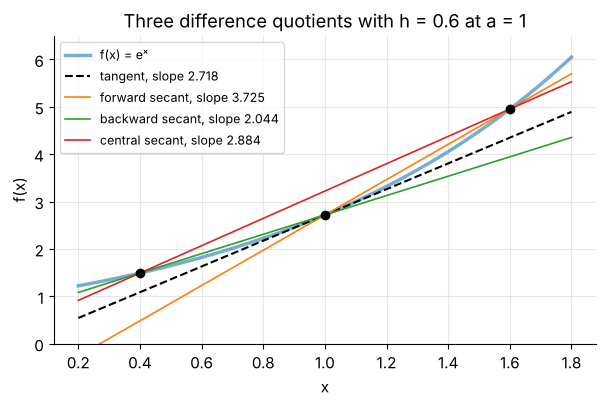

In [16]:
a_nd, h_big = 1.0, 0.6
xx = np.linspace(0.2, 1.8, 200)
slopes_nd = {
    "forward": (np.exp(a_nd + h_big) - np.exp(a_nd)) / h_big,
    "backward": (np.exp(a_nd) - np.exp(a_nd - h_big)) / h_big,
    "central": (np.exp(a_nd + h_big) - np.exp(a_nd - h_big)) / (2 * h_big),
}
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(xx, np.exp(xx), lw=2.5, alpha=0.6, label="f(x) = eˣ")
ax.plot(xx, np.exp(a_nd) + np.e * (xx - a_nd), "k--", lw=1.5, label=f"tangent, slope {np.e:.3f}")
anchors = {"forward": a_nd, "backward": a_nd, "central": a_nd - h_big}
for (name, s), c in zip(slopes_nd.items(), ["C1", "C2", "C3"]):
    x_anchor = anchors[name]
    ax.plot(xx, np.exp(x_anchor) + s * (xx - x_anchor), color=c, lw=1.2, label=f"{name} secant, slope {s:.3f}")
ax.scatter([a_nd - h_big, a_nd, a_nd + h_big], np.exp([a_nd - h_big, a_nd, a_nd + h_big]), color="k", zorder=3)
ax.set(title="Three difference quotients with h = 0.6 at a = 1", xlabel="x", ylabel="f(x)", ylim=(0, 6.5))
ax.legend(fontsize=9)
plt.show()

The forward secant is too steep, the backward one too shallow, and the central secant is almost
parallel to the tangent even with this crude $h$: its slope is off by about $0.17$, compared with about
$1.0$ (forward) and $0.67$ (backward).
Bonus fact: for any parabola the central difference is *exact* for every $h$, and for $f(x) = x^2$ at $a = 3$
with $h = 1$: $\frac{16 - 4}{2} = 6 = f'(3)$. The next subsection explains both observations.

### 3.2 Truncation error via Taylor series

**Taylor's theorem** says that near a point $a$, a smooth function is approximated by a polynomial whose
coefficients are its derivatives at $a$:

$$
f(a + h) = f(a) + f'(a)\,h + \frac{f''(a)}{2}\,h^2 + \frac{f'''(a)}{6}\,h^3 + \cdots
$$

The first two terms are the tangent-line approximation from Section 2.2, and each extra term adds a
correction that matters less and less as $h \to 0$ (in general the $k$-th term is $\frac{f^{(k)}(a)}{k!}h^k$).

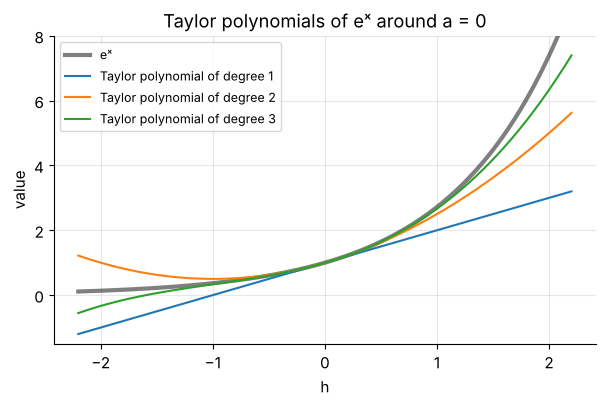

In [17]:
xx = np.linspace(-2.2, 2.2, 200)
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(xx, np.exp(xx), "k", lw=3, alpha=0.5, label="eˣ")
taylor = np.zeros_like(xx)
for k in range(4):
    taylor = taylor + xx**k / math.factorial(k)
    if k >= 1:
        ax.plot(xx, taylor, lw=1.5, label=f"Taylor polynomial of degree {k}")
ax.set(title="Taylor polynomials of eˣ around a = 0", xlabel="h", ylabel="value", ylim=(-1.5, 8))
ax.legend(fontsize=9)
plt.show()

Near $h = 0$ every polynomial hugs the curve, and higher degrees stay close over a wider range. Now plug
Taylor's expansion into the difference quotients.

**Forward difference:**

$$
D_{+}(h) = \frac{f(a+h) - f(a)}{h} = f'(a) + \underbrace{\frac{f''(a)}{2}\,h + \frac{f'''(a)}{6}\,h^2 + \cdots}_{\text{truncation error} \;=\; O(h)} .
$$

**Central difference:** write the expansion for $+h$ and for $-h$ and subtract. The even powers cancel:

$$
f(a+h) - f(a-h) = 2f'(a)\,h + \frac{f'''(a)}{3}\,h^3 + O(h^5)
\;\;\Longrightarrow\;\;
D_{0}(h) = f'(a) + \underbrace{\frac{f'''(a)}{6}\,h^2 + O(h^4)}_{\text{truncation error} \;=\; O(h^2)} .
$$

The notation $O(h^p)$ ("big-O") means "at most a constant times $h^p$ for small $h$". So the forward
difference is a **first-order** method: halving $h$ halves the error (exactly the pattern you saw in the
coffee table), and the central difference is **second-order**: halving $h$ divides the error by 4.
For a parabola $f''' = 0$ and every higher derivative is 0, so the central difference has no error at all.
Let's confirm the orders on $f(x) = e^x$ at $a = 1$, where $f'(1) = e$.

In [18]:
rows = []
prev = None
for h in [0.1, 0.05, 0.025, 0.0125]:
    err_f = (np.exp(1 + h) - np.exp(1)) / h - np.e
    err_c = (np.exp(1 + h) - np.exp(1 - h)) / (2 * h) - np.e
    ratio_f = prev[0] / err_f if prev else np.nan
    ratio_c = prev[1] / err_c if prev else np.nan
    rows.append((h, err_f, ratio_f, err_c, ratio_c))
    prev = (err_f, err_c)
# "shrink factor" = previous error / current error, i.e. how much the error fell when h was halved
display(pd.DataFrame(rows, columns=["h", "fwd error", "fwd shrink", "central error",
                                    "central shrink"]).set_index("h"))

,fwd error,fwd shrink,central error,central shrink
h,,,,
0.1000,0.1406,NaN,4.5327e-03,NaN
0.0500,0.0691,2.0340,1.1328e-03,4.0015
0.0250,0.0343,2.0168,2.8316e-04,4.0004
0.0125,0.0171,2.0084,7.0789e-05,4.0001


The forward-difference error shrinks by a factor of about 2 per halving, the central-difference error by
about 4, first order versus second order, exactly as derived. Also compare the leading terms with the
formulas: at $h = 0.1$ the forward error $\approx \frac{e}{2}(0.1) \approx 0.136$ and the central error
$\approx \frac{e}{6}(0.01) \approx 0.0045$.

### 3.3 Round-off error and the U-shaped curve

So should we just take $h = 10^{-15}$? No, because computers store numbers with finitely many digits.
A standard `float64` keeps about 16 significant decimal digits, and the gap between 1 and the next
representable number is the **machine epsilon** $\varepsilon \approx 2.2 \times 10^{-16}$.
Subtracting two nearly equal numbers wipes out most of the trustworthy digits
(**catastrophic cancellation**):

In [19]:
eps = np.finfo(float).eps
print(f"machine epsilon for float64: {eps:.3e}")
print(f"(1 + 1e-15) - 1 = {(1 + 1e-15) - 1:.6e}   (exact answer 1e-15: an {abs((1 + 1e-15) - 1 - 1e-15) / 1e-15:.0%} error)")
print(f"(1 + 1e-16) - 1 = {(1 + 1e-16) - 1}              (the computer cannot even see the change)")

machine epsilon for float64: 2.220e-16
(1 + 1e-15) - 1 = 1.110223e-15   (exact answer 1e-15: an 11% error)
(1 + 1e-16) - 1 = 0.0              (the computer cannot even see the change)


In a difference quotient, $f(a+h)$ and $f(a)$ each carry a rounding error of roughly $\varepsilon\,|f(a)|$.
Their difference keeps that absolute error, and dividing by a tiny $h$ *magnifies* it. A simple error
model adds the two effects:

$$
E_{+}(h) \approx \underbrace{\frac{|f''(a)|}{2}\,h}_{\text{truncation}} + \underbrace{\frac{\varepsilon\,|f(a)|}{h}}_{\text{round-off}},
\qquad
E_{0}(h) \approx \frac{|f'''(a)|}{6}\,h^2 + \frac{\varepsilon\,|f(a)|}{h}.
$$

Truncation error wants $h$ small, round-off wants $h$ large. Setting the derivative of $E(h)$ with respect
to $h$ to zero gives the best compromise:

$$
h^*_{+} = \sqrt{\frac{2\,\varepsilon\,|f(a)|}{|f''(a)|}} \approx 2 \times 10^{-8},
\qquad
h^*_{0} = \left(\frac{3\,\varepsilon\,|f(a)|}{|f'''(a)|}\right)^{1/3} \approx 9 \times 10^{-6}
\qquad \text{(for } f = e^x\text{, where } f = f'' = f'''\text{)}.
$$

On a log–log plot both effects are straight lines (slopes $-1$ for round-off, $+1$ or $+2$ for
truncation), so the total error traces a **U** (more precisely a **V**).

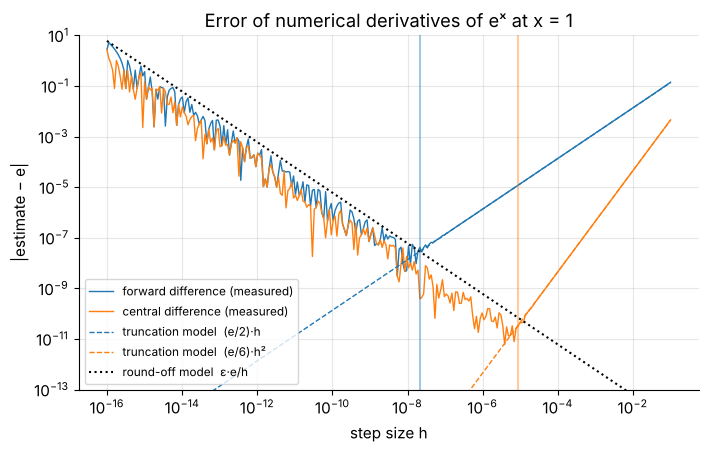

theory: best forward h ≈ 2.1e-08, best central h ≈ 8.7e-06
measured on this grid: forward error is smallest near h = 5.3e-09 (3.1e-09); central near h = 3.8e-06 (6.0e-12)


In [20]:
hs = np.logspace(-16, -1, 300)
err_fwd = np.abs((np.exp(1 + hs) - np.exp(1)) / hs - np.e)
err_cen = np.abs((np.exp(1 + hs) - np.exp(1 - hs)) / (2 * hs) - np.e)
h_star_f = np.sqrt(2 * eps)
h_star_c = (3 * eps) ** (1 / 3)

fig, ax = plt.subplots(figsize=(8, 4.6))
ax.loglog(hs, np.maximum(err_fwd, 1e-17), color="C0", lw=1, label="forward difference (measured)")
ax.loglog(hs, np.maximum(err_cen, 1e-17), color="C1", lw=1, label="central difference (measured)")
ax.loglog(hs, np.e / 2 * hs, "C0--", lw=1, label="truncation model  (e/2)·h")
ax.loglog(hs, np.e / 6 * hs**2, "C1--", lw=1, label="truncation model  (e/6)·h²")
ax.loglog(hs, eps * np.e / hs, "k:", lw=1.5, label="round-off model  ε·e/h")
ax.axvline(h_star_f, color="C0", alpha=0.4)
ax.axvline(h_star_c, color="C1", alpha=0.4)
ax.set(title="Error of numerical derivatives of eˣ at x = 1", xlabel="step size h",
       ylabel="|estimate − e|", ylim=(1e-13, 10))
ax.legend(fontsize=8.5, loc="lower left")
plt.show()

print(f"theory: best forward h ≈ {h_star_f:.1e}, best central h ≈ {h_star_c:.1e}")
print(f"measured on this grid: forward error is smallest near h = {hs[np.argmin(err_fwd)]:.1e} "
      f"({err_fwd.min():.1e}), central near h = {hs[np.argmin(err_cen)]:.1e} ({err_cen.min():.1e})")

Reading the plot from right to left: as $h$ shrinks the error first falls along the truncation lines
(slope $+1$ for forward, $+2$ for central), bottoms out near the predicted $h^*$, and then *rises* again
along the round-off line, becoming jagged because rounding errors are erratic. At the far left
($h \lesssim 10^{-16}$) the computer cannot distinguish $1 + h$ from $1$, the estimate is 0, and the error
equals $e$ itself. The measured minima lie *below* the dashed lines because the model assumes
worst-case rounding, and they sit within a factor of about 2 to 4 of the predicted $h^*$, exactly the
kind of accuracy you want from a back-of-the-envelope model: it tells you the right *order of magnitude*.

### 3.4 Choosing $h$, and gradient checking

Practical rules of thumb (in `float64`, for inputs of size about 1, and scale $h$ with $|a|$ otherwise):

| method | error order | good $h$ | best achievable relative error |
|---|---|---|---|
| forward | $O(h)$ | $\approx \sqrt{\varepsilon} \approx 10^{-8}$ | $\approx 10^{-8}$ |
| central | $O(h^2)$ | $\approx \varepsilon^{1/3} \approx 10^{-5}$ to $10^{-6}$ | $\approx 10^{-10}$ to $10^{-11}$ |

In `float32` (PyTorch's default type) $\varepsilon \approx 1.2\times 10^{-7}$, about 500 million times
larger than in `float64`, so the round-off floor rises dramatically:

In [21]:
for h in [1e-1, 1e-2, 1e-3, 1e-4, 1e-5]:
    a32, h32 = np.float32(1.0), np.float32(h)
    est32 = (np.exp(a32 + h32) - np.exp(a32 - h32)) / (np.float32(2) * h32)
    print(f"float32 central difference, h = {h:.0e}: error = {abs(float(est32) - np.e):.1e}")

float32 central difference, h = 1e-01: error = 4.5e-03
float32 central difference, h = 1e-02: error = 3.6e-05
float32 central difference, h = 1e-03: error = 7.2e-05
float32 central difference, h = 1e-04: error = 8.8e-04
float32 central difference, h = 1e-05: error = 1.2e-02


The best single-precision result (around $h = 10^{-2}$, matching $\varepsilon_{32}^{1/3} \approx 5\times10^{-3}$)
is only good to about five significant digits, and with $h = 10^{-5}$ (a fine choice in `float64`) the
error is about $0.01$, leaving only two or three correct digits. That is why numerical gradient checks
are always done in double precision.

**Gradient checking.** Most loss functions in ML depend on many inputs at once. The same idea works one
input at a time: nudge input $k$ by $\pm h$ while keeping all others fixed (this "derivative with respect to
one input" is called a *partial derivative*, and Section 6 develops it properly). Collecting these numbers
gives a numerical **gradient**. Comparing it with the gradient your code computes analytically (using a
*relative* error so the result does not depend on the scale of the numbers) is the standard way to
catch bugs in hand-written derivative code:

$$
\text{relative error} = \frac{\lVert \mathbf{g}_{\text{analytic}} - \mathbf{g}_{\text{numeric}} \rVert}{\lVert \mathbf{g}_{\text{analytic}} \rVert + \lVert \mathbf{g}_{\text{numeric}} \rVert}
\qquad \text{(below } 10^{-7}\text{: almost certainly correct; above } 10^{-3}\text{: almost certainly a bug).}
$$

In [22]:
def numerical_gradient(f, x, h=1e-6):
    """Central-difference estimate of the gradient of a scalar function f at the point x (a 1-D array)."""
    x = np.asarray(x, dtype=float)
    grad = np.zeros_like(x)
    for k in range(x.size):
        step = np.zeros_like(x)
        step[k] = h
        grad[k] = (f(x + step) - f(x - step)) / (2 * h)
    return grad


def relative_error(g1, g2):
    """Scale-free distance between two gradient vectors."""
    g1, g2 = np.asarray(g1, float), np.asarray(g2, float)
    return np.linalg.norm(g1 - g2) / max(np.linalg.norm(g1) + np.linalg.norm(g2), 1e-12)


def f_demo(v):
    return v[0] ** 2 * v[1] + np.sin(v[2]) + np.exp(v[0] * v[2])


def grad_demo(v):           # derived by hand: differentiate with respect to one input at a time
    return np.array([2 * v[0] * v[1] + v[2] * np.exp(v[0] * v[2]),
                     v[0] ** 2,
                     np.cos(v[2]) + v[0] * np.exp(v[0] * v[2])])


def grad_demo_buggy(v):     # a typical bug: forgot the chain-rule factor v[2] in the first entry
    g = grad_demo(v)
    g[0] = 2 * v[0] * v[1] + np.exp(v[0] * v[2])
    return g


v0 = np.array([0.5, -1.2, 0.8])
g_num = numerical_gradient(f_demo, v0)
print("numerical gradient:", g_num.round(6))
print(f"relative error, correct formula: {relative_error(grad_demo(v0), g_num):.1e}")
print(f"relative error, buggy formula:   {relative_error(grad_demo_buggy(v0), g_num):.1e}")

numerical gradient: [-0.00654   0.25      1.442619]
relative error, correct formula: 3.5e-11
relative error, buggy formula:   1.0e-01


> **Common pitfall.** Do not use numerical gradients to *train* models: they need two function
> evaluations per parameter, so a model with a million parameters would need two million loss
> evaluations per step. Use them to *test* analytic gradients on a few small cases.

> **Going deeper.** The *complex-step* method, $f'(a) \approx \operatorname{Im} f(a + ih)/h$, involves no
> subtraction at all and therefore no cancellation, so $h = 10^{-20}$ works and the result is accurate to
> machine precision (for functions that accept complex inputs).

**Quick check.** You halve $h$ and the error of your derivative estimate drops from $8\times10^{-4}$ to
$2\times10^{-4}$. Which kind of difference quotient are you probably using? What happens if you keep
halving $h$ forever?

<details>
<summary>Answer</summary>

The error dropped by a factor of 4, the signature of a second-order method: the central difference.
If you keep halving, the error keeps falling by about 4 per step only until round-off takes over (around
$h \approx 10^{-5}$ for inputs of size 1 in double precision), and after that it *grows* roughly like $1/h$.
</details>

### ✏️ Exercise 2: Richardson extrapolation, a fourth-order derivative from two central differences

Because the central difference satisfies $D_0(h) = f'(a) + c\,h^2 + O(h^4)$ with an unknown constant $c$,
you can **cancel** the $h^2$ term by combining two step sizes:

$$
R(h) = \frac{4\,D_0(h/2) - D_0(h)}{3} = f'(a) + O(h^4).
$$

(Check: $4\big(f' + c\,h^2/4\big) - \big(f' + c\,h^2\big) = 3f'$.) Implement `richardson_derivative(f, a, h)`.
The checker verifies the accuracy and that the error falls by about $2^4 = 16$ when $h$ is halved.

In [23]:
# ✏️ Exercise 2: Richardson extrapolation
def richardson_derivative(f, a, h):
    """Return (4*D0(h/2) - D0(h)) / 3, where D0 is the central difference of f at a."""
    # YOUR CODE HERE
    raise NotImplementedError


def _test():
    est = richardson_derivative(np.exp, 1.0, 0.1)
    assert abs(est - np.e) < 1e-6, f"estimate {est} is too far from e = {np.e}"
    e1 = abs(richardson_derivative(np.sin, 0.7, 0.1) - np.cos(0.7))
    e2 = abs(richardson_derivative(np.sin, 0.7, 0.05) - np.cos(0.7))
    assert 10 < e1 / e2 < 22, f"halving h should cut the error by about 16, got a factor {e1 / e2:.2f}"
    assert abs(richardson_derivative(lambda x: x**3, 2.0, 0.5) - 12.0) < 1e-12, "cubics should be exact"

run_check("Exercise 2", _test)

⏳ Exercise 2: not implemented yet; fill in the function and re-run this cell.


<details>
<summary><b>Solution</b> (try first!)</summary>

```python
def richardson_derivative(f, a, h):
    def D0(step):
        return (f(a + step) - f(a - step)) / (2 * step)
    return (4 * D0(h / 2) - D0(h)) / 3
```
The same "combine two step sizes to cancel the leading error term" trick, applied repeatedly, is called
*Richardson extrapolation*, and it also underlies Romberg integration. For a cubic, $f^{(5)} = 0$, so the
remaining error term vanishes and the result is exact up to rounding.
</details>

## 4. Optimization basics in one variable

Before building an algorithm that *walks* to a minimum, let's be precise about what a minimum is and what
derivatives can tell us about it.

### 4.1 Critical points and the derivative tests

- $x^*$ is a **global minimum** of $f$ if $f(x^*) \le f(x)$ for *every* $x$ in the domain.
- $x^*$ is a **local minimum** if $f(x^*) \le f(x)$ for every $x$ *in some small interval around* $x^*$
  ("the bottom of a dip, but maybe not the deepest dip"). Maxima are defined the same way with $\ge$.

**Fermat's theorem.** If $f$ has a local minimum or maximum at an interior point $a$ and is differentiable
there, then $f'(a) = 0$.
*Why:* at a local minimum, $f(a + h) - f(a) \ge 0$ for all small $h$. For $h > 0$ the difference quotient
is therefore $\ge 0$, so its limit is $\ge 0$, while for $h < 0$ the quotient is $\le 0$, so the limit is $\le 0$.
The only number that is both is 0.

Points where $f'(a) = 0$ or where $f'(a)$ does not exist are called **critical points**. Every interior local
extremum is a critical point, but the converse fails: $f(x) = x^3$ has $f'(0) = 0$ yet keeps increasing
through 0. Two tests sort critical points out:

- **First-derivative test.** If $f'$ changes sign from $-$ to $+$ at $a$ (downhill, then uphill), $a$ is a
  local minimum, from $+$ to $-$, a local maximum, and with no sign change, neither.
- **Second-derivative test.** If $f'(a) = 0$ and $f''(a) > 0$, $a$ is a local minimum (the graph is a cup),
  if $f''(a) < 0$, a local maximum (a cap), and if $f''(a) = 0$, the test is **inconclusive**.
  *Why:* by Taylor's theorem $f(a + h) \approx f(a) + 0\cdot h + \tfrac12 f''(a)\,h^2$, so near $a$ the
  sign of $f''(a)$ decides whether $f$ rises or falls in both directions.

Back to the cubic $f(x) = \frac{x^3}{3} - x^2 - 3x + 2$ from Section 2.4, with $f'(x) = (x+1)(x-3)$ and
$f''(x) = 2x - 2$:

In [24]:
crit = np.sort(np.roots([1, -2, -3]).real)          # roots of f'(x) = x^2 - 2x - 3
for c in crit:
    second = 2 * c - 2
    kind = "local minimum" if second > 0 else "local maximum" if second < 0 else "inconclusive"
    print(f"x = {c:5.2f}:  f(x) = {f_cubic(c):7.4f},  f''(x) = {second:5.2f}  ->  {kind}")
print(f"f(-10) = {f_cubic(-10):.1f}, f(10) = {f_cubic(10):.1f}: the cubic is unbounded in both directions,")
print("so these are only LOCAL extrema - there is no global minimum or maximum on the whole real line.")

x = -1.00:  f(x) =  3.6667,  f''(x) = -4.00  ->  local maximum
x =  3.00:  f(x) = -7.0000,  f''(x) =  4.00  ->  local minimum
f(-10) = -401.3, f(10) = 205.3: the cubic is unbounded in both directions,
so these are only LOCAL extrema - there is no global minimum or maximum on the whole real line.


When $f''(a) = 0$ anything can happen. The three functions below all have $f'(0) = 0$ and $f''(0) = 0$,
yet 0 is a minimum, a maximum and neither, respectively, so for those, go back to the first-derivative test.

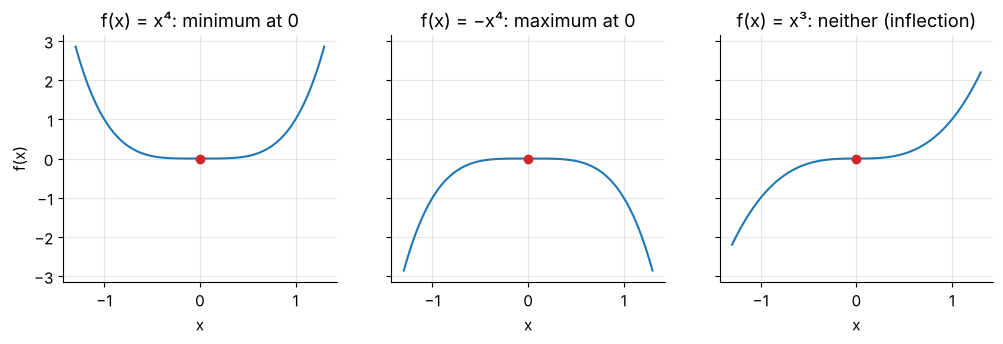

In [25]:
xx = np.linspace(-1.3, 1.3, 200)
fig, axes = plt.subplots(1, 3, figsize=(12, 3.2), sharey=True)
for ax, (expr, func, verdict) in zip(axes, [("x⁴", xx**4, "minimum at 0"), ("−x⁴", -xx**4, "maximum at 0"),
                                            ("x³", xx**3, "neither (inflection)")]):
    ax.plot(xx, func)
    ax.scatter([0], [0], color="C3", zorder=3)
    ax.set(title=f"f(x) = {expr}: {verdict}", xlabel="x")
axes[0].set_ylabel("f(x)")
plt.show()

### 4.2 Local versus global minima

Consider $f(x) = x^4 - 4x^2 + x$. Its derivative $f'(x) = 4x^3 - 8x + 1$ has three real roots, and
$f''(x) = 12x^2 - 8$ classifies them:

,critical point x,f(x),f''(x),type
0,-1.473,-5.4442,18.0367,local min (global)
1,0.126,0.0627,-7.8095,local max
2,1.347,-2.6186,13.7728,local min (not global)


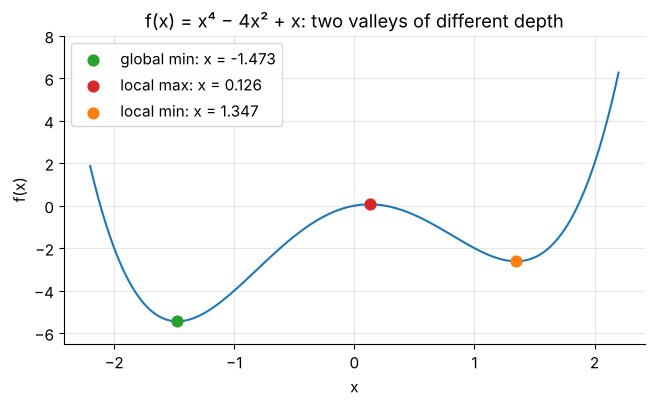

In [26]:
def f_w(x):
    return x**4 - 4 * x**2 + x


def df_w(x):
    return 4 * x**3 - 8 * x + 1


crit_w = np.sort(np.roots([4, 0, -8, 1]).real)
display(pd.DataFrame({"critical point x": crit_w, "f(x)": f_w(crit_w), "f''(x)": 12 * crit_w**2 - 8,
                      "type": ["local min (global)", "local max", "local min (not global)"]}))

xx = np.linspace(-2.2, 2.2, 400)
fig, ax = plt.subplots(figsize=(7.5, 4))
ax.plot(xx, f_w(xx))
for c, label, col in zip(crit_w, ["global min", "local max", "local min"], ["C2", "C3", "C1"]):
    ax.scatter([c], [f_w(c)], color=col, s=60, zorder=3, label=f"{label}: x = {c:.3f}")
ax.set(title="f(x) = x⁴ − 4x² + x: two valleys of different depth", xlabel="x", ylabel="f(x)", ylim=(-6.5, 8))
ax.legend()
plt.show()

Both valleys satisfy $f' = 0$ and $f'' > 0$, so *local* information cannot tell you which one is deeper.
You have to compare the values: $f(-1.473) \approx -5.444$ beats $f(1.347) \approx -2.619$. Because
$f(x) \to +\infty$ as $|x| \to \infty$, a global minimum exists, and it must be the lower of the two.

> **Key idea.** Derivatives are *local* information: they describe the function near the point where you
> evaluate them. An algorithm that only looks at slopes, like gradient descent, finds *a* local minimum,
> and which one depends on where it starts (Section 8.4). For one variable you can find the global minimum
> by listing all critical points (plus interval endpoints, if the domain has any) and comparing values, and
> in high dimensions that is hopeless, which is why the next idea is so valuable.

### 4.3 Convex functions: where local means global

A function is **convex** if the straight segment (chord) between any two points of its graph never goes
below the graph:

$$
f\big(\lambda u + (1 - \lambda) v\big) \;\le\; \lambda f(u) + (1 - \lambda) f(v)
\qquad \text{for all } u, v \text{ and all } \lambda \in [0, 1].
$$

The left side is the function at a point between $u$ and $v$, and the right side is the chord at the same
point. Two equivalent tests are easier to use:

- **Tangent-line test** (for differentiable $f$): the graph lies above every tangent line,
  $f(v) \ge f(u) + f'(u)(v - u)$ for all $u, v$.
- **Second-derivative test** (for twice-differentiable $f$): $f''(x) \ge 0$ everywhere, so the graph is a
  cup everywhere.

Convex: $x^2$, $x^4$, $e^x$, $|x|$, $\max(0, x)$, $-\ln x$ (for $x > 0$), every straight line $ax + b$.
Not convex: $x^3$, $\sin x$, $x^4 - 4x^2 + x$. Convexity survives three useful operations: **sums** (and
positive multiples) of convex functions, **composition with a linear/affine map** ($x \mapsto f(ax + b)$),
and **pointwise maxima**. That is enough to see that a sum of squared residuals
$\sum_i (w x_i + b - y_i)^2$ is convex in $(w, b)$, and Section 9.5 makes this precise.

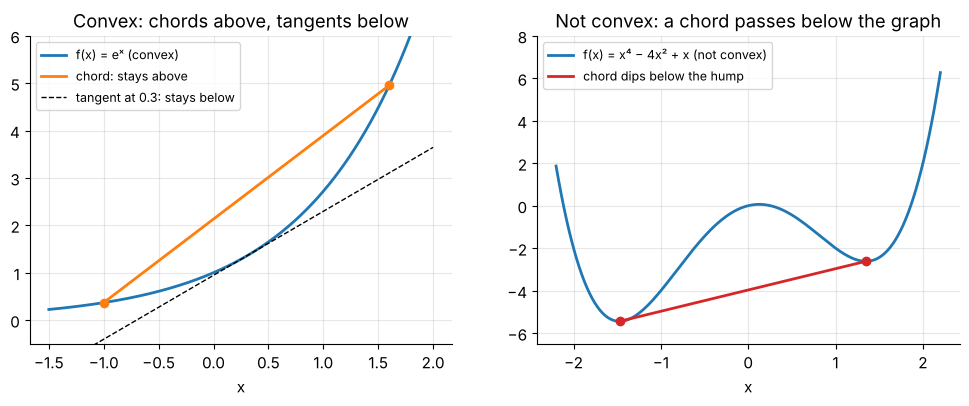

In [27]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
xx = np.linspace(-1.5, 2.0, 300)
u, v = -1.0, 1.6
lam = np.linspace(0, 1, 50)
axes[0].plot(xx, np.exp(xx), lw=2, label="f(x) = eˣ (convex)")
axes[0].plot(lam * u + (1 - lam) * v, lam * np.exp(u) + (1 - lam) * np.exp(v), "C1", lw=2, label="chord: stays above")
axes[0].plot(xx, np.exp(0.3) + np.exp(0.3) * (xx - 0.3), "k--", lw=1, label="tangent at 0.3: stays below")
axes[0].scatter([u, v], np.exp([u, v]), color="C1", zorder=3)
axes[0].set(title="Convex: chords above, tangents below", xlabel="x", ylim=(-0.5, 6))
axes[0].legend(fontsize=9)

xx = np.linspace(-2.2, 2.2, 300)
u, v = -1.473, 1.347
axes[1].plot(xx, f_w(xx), lw=2, label="f(x) = x⁴ − 4x² + x (not convex)")
axes[1].plot(lam * u + (1 - lam) * v, lam * f_w(u) + (1 - lam) * f_w(v), "C3", lw=2,
             label="chord dips below the hump")
axes[1].scatter([u, v], f_w(np.array([u, v])), color="C3", zorder=3)
axes[1].set(title="Not convex: a chord passes below the graph", xlabel="x", ylim=(-6.5, 8))
axes[1].legend(fontsize=9)
plt.show()

**The payoff theorem.** If $f$ is convex and differentiable and $f'(x^*) = 0$, then $x^*$ is a **global**
minimum. *Proof:* by the tangent-line test at $u = x^*$, $f(v) \ge f(x^*) + 0\cdot(v - x^*) = f(x^*)$ for
every $v$. If $f$ is *strictly* convex (the chord inequality is strict for $u \ne v$, e.g. $f'' > 0$
everywhere), the minimizer is also **unique**. So for convex losses there are no "bad valleys":
gradient descent cannot get trapped in a local minimum that isn't global.

Checking the chord inequality on many random triples $(u, v, \lambda)$ is a quick numerical sanity test
(it can *disprove* convexity on the tested range, never prove it):

In [28]:
def chord_violation_rate(f, lo, hi, n=20000, seed=SEED):
    """Fraction of random (u, v, lam) in [lo, hi]^2 x [0, 1] that violate the chord inequality."""
    r = np.random.default_rng(seed)
    u, v, lam = r.uniform(lo, hi, n), r.uniform(lo, hi, n), r.uniform(0, 1, n)
    lhs = f(lam * u + (1 - lam) * v)
    rhs = lam * f(u) + (1 - lam) * f(v)
    return np.mean(lhs > rhs + 1e-12)


for name, f in [("x^2", np.square), ("|x|", np.abs), ("e^x", np.exp), ("x^3", lambda x: x**3),
                ("sin x", np.sin), ("x^4 - 4x^2 + x", f_w)]:
    print(f"{name:15s} violations on [-2, 2]: {chord_violation_rate(f, -2, 2):6.2%}")

x^2             violations on [-2, 2]:  0.00%
|x|             violations on [-2, 2]:  0.00%
e^x             violations on [-2, 2]:  0.00%
x^3             violations on [-2, 2]: 49.43%
sin x           violations on [-2, 2]: 50.62%
x^4 - 4x^2 + x  violations on [-2, 2]: 56.70%


Saddle points (the third kind of critical point, which only exists with two or more variables) wait for
us in Section 6.4, after we have partial derivatives.

**Quick check.** (1) Is $g(c) = \frac1m\sum_{i=1}^{m} |y_i - c|$ (the MAE of predicting the constant $c$)
convex in $c$? (2) A differentiable convex function has $f'(2) = 0$. What can you say about $f(5)$ versus $f(2)$?

<details>
<summary>Answer</summary>

(1) Yes. Each term $|y_i - c|$ is the convex function $|\cdot|$ composed with the affine map $c \mapsto y_i - c$,
and a positive multiple of a sum of convex functions is convex. (2) $x = 2$ is a global minimum, so
$f(5) \ge f(2)$ (with equality possible, e.g. for a function that is flat on $[2, 5]$).
</details>

## 5. Gradient descent in one dimension

### 5.1 The idea: walk against the slope

Imagine standing on a hillside in thick fog. You cannot see the valley, but you can feel the slope under
your feet. A sensible strategy: take a step downhill, feel the slope again, take another step, and repeat.
Where the ground is steep, take bigger steps, and where it is nearly flat, you are probably close to the bottom,
so take small ones. That is **gradient descent (GD)**:

$$
x_{t+1} = x_t - \eta\, f'(x_t), \qquad t = 0, 1, 2, \dots
$$

- $x_0$ is the **starting point** (initialization), $x_t$ the position after $t$ steps.
- $\eta > 0$ (Greek "eta") is the **learning rate** or step size.
- The **minus sign** implements "move against the sign of the derivative" (Section 2.4): if $f'(x_t) > 0$
  the step goes left, if $f'(x_t) < 0$ it goes right.
- The step is **proportional to the slope**, so steps automatically shrink as the ground flattens.
- If $f'(x_t) = 0$ the update does nothing: the points where GD can stop are exactly the critical points.

**Why do we need $\eta$ at all?** Why not step by $-f'(x_t)$ itself? Try it on $f(x) = (x - 3)^2$, whose
derivative is $f'(x) = 2(x - 3)$, starting from $x_0 = 7$:

In [29]:
x = 7.0
print("eta = 1 (raw derivative steps) on f(x) = (x - 3)^2:")
for t in range(5):
    g = 2 * (x - 3)
    print(f"  t = {t}: x = {x:5.1f}, f'(x) = {g:5.1f}  ->  next x = {x - g:5.1f}")
    x = x - g

eta = 1 (raw derivative steps) on f(x) = (x - 3)^2:
  t = 0: x =   7.0, f'(x) =   8.0  ->  next x =  -1.0
  t = 1: x =  -1.0, f'(x) =  -8.0  ->  next x =   7.0
  t = 2: x =   7.0, f'(x) =   8.0  ->  next x =  -1.0
  t = 3: x =  -1.0, f'(x) =  -8.0  ->  next x =   7.0
  t = 4: x =   7.0, f'(x) =   8.0  ->  next x =  -1.0


The iterate jumps from 7 to $-1$ and back to 7 forever, always 4 away from the minimum at 3. The derivative
has units of "change in $f$ per unit of $x$", so it is not automatically a sensible *distance* to move, and
the learning rate converts slope into step length. With $\eta = 0.25$ instead:

| $t$ | $x_t$ | $f'(x_t) = 2(x_t - 3)$ | step $-\eta f'(x_t)$ | $x_{t+1}$ | $f(x_t)$ |
|---|---|---|---|---|---|
| 0 | 7 | 8 | $-2$ | 5 | 16 |
| 1 | 5 | 4 | $-1$ | 4 | 4 |
| 2 | 4 | 2 | $-0.5$ | 3.5 | 1 |
| 3 | 3.5 | 1 | $-0.25$ | 3.25 | 0.25 |
| 4 | 3.25 | 0.5 | $-0.125$ | 3.125 | 0.0625 |

Each step halves the distance to 3 and divides the loss by 4. Section 5.4 explains exactly why.

### 5.2 Why it works: the first-order Taylor expansion

The linear approximation from Section 2.2 says that for a small step $\Delta$,

$$
f(x + \Delta) \approx f(x) + f'(x)\,\Delta .
$$

To make $f$ smaller, choose $\Delta$ with the opposite sign of $f'(x)$. The choice $\Delta = -\eta f'(x)$ gives

$$
f\big(x - \eta f'(x)\big) \approx f(x) - \eta\,f'(x)^2 \;<\; f(x) \quad \text{whenever } f'(x) \ne 0,
$$

a guaranteed decrease, *as long as $\eta$ is small enough for the linear approximation to be trusted*.
How small? Include the second-order term. Taylor's theorem with remainder says
$f(x + \Delta) = f(x) + f'(x)\Delta + \frac12 f''(\xi)\Delta^2$ for some $\xi$ between $x$ and $x + \Delta$.
If the curvature is bounded, $f''(\xi) \le L$ for all $\xi$, then with $\Delta = -\eta f'(x)$:

$$
f(x_{\text{new}}) \;\le\; f(x) - \eta f'(x)^2 + \frac{L}{2}\eta^2 f'(x)^2 \;=\; f(x) - \eta\Big(1 - \frac{L\eta}{2}\Big) f'(x)^2 .
$$

> **Key idea (the descent lemma).** If $f'' \le L$ everywhere, every gradient-descent step with
> $0 < \eta < 2/L$ strictly decreases $f$ (unless $f'(x) = 0$). The choice $\eta = 1/L$ guarantees a decrease
> of at least $f'(x)^2 / (2L)$. **The more sharply the function can bend, the smaller the steps must be.**

### 5.3 Worked example: computing $\ln 2$ with gradient descent

Quadratics are almost too easy, so take $f(x) = e^x - 2x$. Its derivative $f'(x) = e^x - 2$ vanishes at
$x^* = \ln 2 \approx 0.6931$, and $f''(x) = e^x > 0$, so $f$ is convex with its unique minimum there
($f(x^*) = 2 - 2\ln 2 \approx 0.6137$). Start at $x_0 = 2$ with $\eta = 0.2$:

$$
x_1 = 2 - 0.2\,(e^2 - 2) = 2 - 0.2 \times 5.3891 = 0.9222, \qquad
x_2 = 0.9222 - 0.2\,(e^{0.9222} - 2) = 0.9222 - 0.2 \times 0.5148 = 0.8192, \;\dots
$$

In [30]:
def f_exp(x):
    return np.exp(x) - 2 * x


def df_exp(x):
    return np.exp(x) - 2


x, eta, rows = 2.0, 0.2, []
for t in range(10):
    g = df_exp(x)
    rows.append((t, x, g, -eta * g, f_exp(x), x - np.log(2)))
    x = x - eta * g
display(pd.DataFrame(rows, columns=["t", "x_t", "f'(x_t)", "step", "f(x_t)", "x_t − ln 2"]).set_index("t"))
errs = [r[-1] for r in rows]
print(f"error ratios in the last steps: {errs[-1] / errs[-2]:.3f}, {errs[-2] / errs[-3]:.3f}")

,x_t,f'(x_t),step,f(x_t),x_t − ln 2
t,,,,,
0,2.0000,5.3891,-1.0778,3.3891,1.3069
1,0.9222,0.5148,-0.1030,0.6704,0.2290
2,0.8192,0.2688,-0.0538,0.6303,0.1261
3,0.7655,0.1500,-0.0300,0.6191,0.0723
4,0.7355,0.0865,-0.0173,0.6155,0.0423
5,0.7182,0.0507,-0.0101,0.6143,0.0250
6,0.7080,0.0300,-0.0060,0.6139,0.0149
7,0.7020,0.0179,-0.0036,0.6138,0.0089
8,0.6985,0.0107,-0.0021,0.6137,0.0053


error ratios in the last steps: 0.599, 0.598


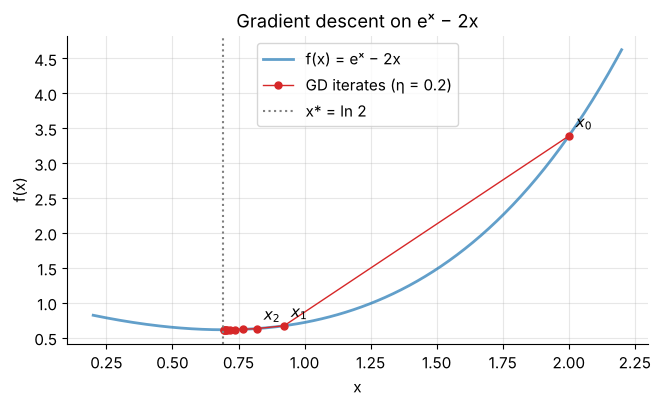

In [31]:
path = [2.0]
for _ in range(10):
    path.append(path[-1] - 0.2 * df_exp(path[-1]))
path = np.array(path)
xx = np.linspace(0.2, 2.2, 200)
fig, ax = plt.subplots(figsize=(7.5, 4))
ax.plot(xx, f_exp(xx), lw=2, alpha=0.7, label="f(x) = eˣ − 2x")
ax.plot(path, f_exp(path), "o-", color="C3", ms=5, lw=1, label="GD iterates (η = 0.2)")
for t in range(3):
    ax.annotate(f"$x_{t}$", (path[t], f_exp(path[t])), textcoords="offset points", xytext=(5, 6))
ax.axvline(np.log(2), color="gray", ls=":", label="x* = ln 2")
ax.set(title="Gradient descent on eˣ − 2x", xlabel="x", ylabel="f(x)")
ax.legend()
plt.show()

The first step is huge (the slope at $x = 2$ is $5.39$), and afterwards the steps shrink as the curve
flattens. Near the minimum the error shrinks by a factor of about $0.6$ per step, and the next subsection
predicts exactly that number. We just computed $\ln 2$ using nothing but exponentials and subtraction.

### 5.4 Exact analysis on a quadratic: the whole learning-rate story

Take $f(x) = a(x - c)^2$ with $a > 0$: a parabola with its minimum at $c$ and curvature $f''(x) = 2a$.
Since $f'(x) = 2a(x - c)$, the update is $x_{t+1} = x_t - 2a\eta\,(x_t - c)$. Subtract $c$ from both sides
and write $e_t = x_t - c$ for the **error** (signed distance to the minimum):

$$
e_{t+1} = (1 - 2a\eta)\,e_t \quad\Longrightarrow\quad e_t = \rho^{\,t}\,e_0, \qquad \rho = 1 - 2a\eta .
$$

The error is a geometric sequence with ratio $\rho$, and everything follows from the value of $\rho$:

| learning rate | ratio $\rho = 1 - 2a\eta$ | behavior |
|---|---|---|
| $0 < \eta < \frac{1}{2a}$ | $0 < \rho < 1$ | **monotone** convergence (never crosses $c$), slow if $\eta$ is tiny |
| $\eta = \frac{1}{2a}$ | $\rho = 0$ | lands exactly on $c$ in **one step** |
| $\frac{1}{2a} < \eta < \frac{1}{a}$ | $-1 < \rho < 0$ | **oscillating** convergence: overshoots, shrinking each time |
| $\eta = \frac{1}{a}$ | $\rho = -1$ | **bounces** between $c \pm e_0$ forever |
| $\eta > \frac{1}{a}$ | $\rho < -1$ | **diverges**, oscillating with growing amplitude |

> **Key idea.** On $f(x) = a(x - c)^2$, gradient descent converges if and only if $0 < \eta < \dfrac{1}{a}$
> $\big(= \dfrac{2}{f''}\big)$, and it needs $t \ge \dfrac{\ln(\text{tol}/|e_0|)}{\ln|\rho|}$ steps to get within
> tol of the minimum.

This matches the descent lemma with $L = f'' = 2a$, and it explains Section 5.1: for $(x - 3)^2$ we have
$a = 1$, so $\eta = 1$ sits exactly on the boundary ($\rho = -1$, bouncing), and $\eta = 0.25$ gives
$\rho = 0.5$ (halving). It even explains the $\ln 2$ example: near the minimum, $e^x - 2x$ looks like a parabola
with $f''(\ln 2) = 2$, i.e. $a = 1$, so $\eta = 0.2$ gives $\rho = 1 - 0.4 = 0.6$, the ratio we measured.

Let's verify the predicted step counts by simulation ($a = 1$, $c = 3$, $x_0 = 7$, tolerance $10^{-6}$):

In [32]:
def regime(a, eta):
    rho = 1 - 2 * a * eta
    if rho == 0:
        return "one step"
    if 0 < rho < 1:
        return "monotone"
    if -1 < rho < 0:
        return "oscillating"
    return "bouncing" if rho == -1 else "diverging"


a_q, c_q, x0_q, tol = 1.0, 3.0, 7.0, 1e-6
rows = []
for eta in [0.05, 0.25, 0.45, 0.5, 0.8, 0.95, 1.0, 1.05]:
    rho = 1 - 2 * a_q * eta
    if rho == 0:
        predicted = 1
    elif abs(rho) < 1:
        predicted = math.ceil(math.log(tol / abs(x0_q - c_q)) / math.log(abs(rho)))
    else:
        predicted = "never"
    x, simulated = x0_q, "never"
    for t in range(1, 1001):
        x = x - eta * 2 * a_q * (x - c_q)
        if abs(x - c_q) <= tol:
            simulated = t
            break
    rows.append((eta, rho, regime(a_q, eta), predicted, simulated))
display(pd.DataFrame(rows, columns=["eta", "rho", "regime", "predicted steps", "simulated steps"])
        .set_index("eta"))

,rho,regime,predicted steps,simulated steps
eta,,,,
0.05,0.9,monotone,145,145
0.25,0.5,monotone,22,22
0.45,0.1,monotone,7,7
0.50,0.0,one step,1,1
0.80,-0.6,oscillating,30,30
0.95,-0.9,oscillating,145,145
1.00,-1.0,bouncing,never,never
1.05,-1.1,diverging,never,never


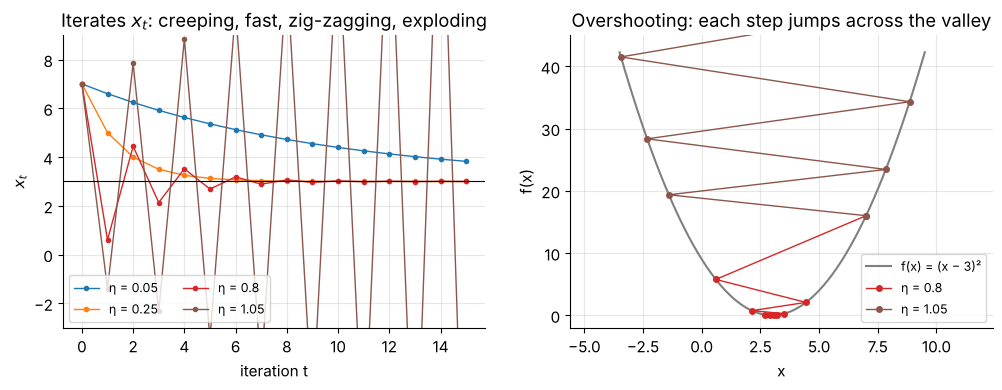

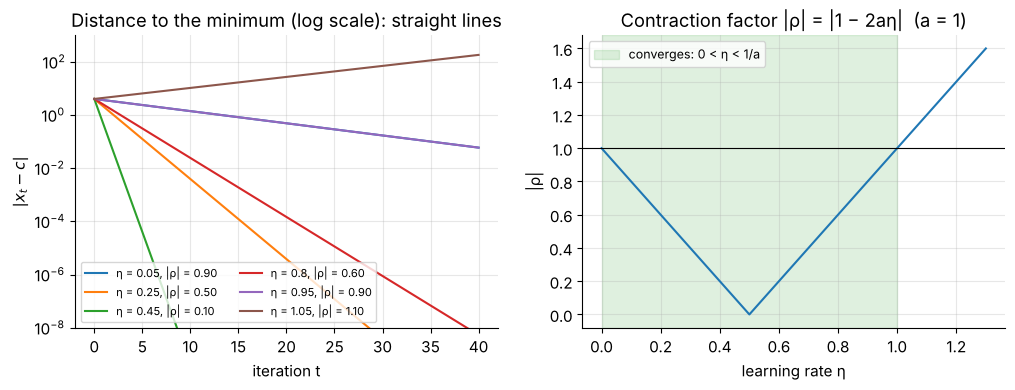

In [33]:
def gd_path_1d(fprime, x0, eta, n_steps):
    """Plain gradient descent in 1-D, and returns the array [x_0, x_1, ..., x_n]."""
    xs = [x0]
    for _ in range(n_steps):
        xs.append(xs[-1] - eta * fprime(xs[-1]))
    return np.array(xs)


dq = lambda x: 2 * a_q * (x - c_q)
colors = {0.05: "C0", 0.25: "C1", 0.45: "C2", 0.8: "C3", 0.95: "C4", 1.05: "C5"}
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
for eta in [0.05, 0.25, 0.8, 1.05]:
    axes[0].plot(gd_path_1d(dq, x0_q, eta, 15), "o-", ms=3, lw=1, color=colors[eta], label=f"η = {eta}")
axes[0].axhline(c_q, color="k", lw=0.8)
axes[0].set(title="Iterates $x_t$: creeping, fast, zig-zagging, exploding", xlabel="iteration t",
            ylabel="$x_t$", ylim=(-3, 9))
axes[0].legend(fontsize=9, ncol=2, loc="lower left")

xx = np.linspace(-3.5, 9.5, 200)
axes[1].plot(xx, (xx - c_q) ** 2, color="gray", label="f(x) = (x − 3)²")
for eta, n in [(0.8, 8), (1.05, 8)]:
    p = gd_path_1d(dq, x0_q, eta, n)
    axes[1].plot(p, (p - c_q) ** 2, "o-", color=colors[eta], ms=4, lw=1, label=f"η = {eta}")
axes[1].set(title="Overshooting: each step jumps across the valley", xlabel="x", ylabel="f(x)", ylim=(-2, 45))
axes[1].legend(fontsize=9)
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
for eta in [0.05, 0.25, 0.45, 0.8, 0.95, 1.05]:
    errors = np.abs(gd_path_1d(dq, x0_q, eta, 40) - c_q)
    axes[0].semilogy(errors, color=colors[eta], lw=1.5, label=f"η = {eta}, |ρ| = {abs(1 - 2 * a_q * eta):.2f}")
axes[0].set(title="Distance to the minimum (log scale): straight lines", xlabel="iteration t",
            ylabel="$|x_t - c|$", ylim=(1e-8, 1e3))
axes[0].legend(fontsize=8, ncol=2)

etas = np.linspace(0, 1.3, 300)
axes[1].plot(etas, np.abs(1 - 2 * a_q * etas))
axes[1].axhline(1, color="k", lw=0.8)
axes[1].axvspan(0, 1 / a_q, color="C2", alpha=0.15, label="converges: 0 < η < 1/a")
axes[1].set(title="Contraction factor |ρ| = |1 − 2aη|  (a = 1)", xlabel="learning rate η", ylabel="|ρ|")
axes[1].legend(fontsize=9)
plt.show()

The predictions match the simulation step for step. Notice the symmetry in the table: $\eta = 0.05$ and
$\eta = 0.95$ both need 145 steps, because $|\rho| = 0.9$ in both cases: one creeps, the other zig-zags
(in the log-scale panel their lines lie exactly on top of each other). On a log scale every geometric
sequence is a straight line with slope $\log_{10}|\rho|$ per step: $\eta = 0.45$ ($|\rho| = 0.1$) gains one
full decimal digit of accuracy per step, while $\eta = 1.05$ ($|\rho| = 1.1$) climbs instead of falling.
The fastest choice is $\eta = 1/(2a)$, where $|\rho| = 0$.

> **Going deeper.** Any smooth function looks like a parabola near a minimum $x^*$:
> $f(x) \approx f(x^*) + \tfrac12 f''(x^*)(x - x^*)^2$. So *locally* the same analysis applies with
> $a = f''(x^*)/2$: GD converges near $x^*$ when $0 < \eta < 2/f''(x^*)$ and is fastest near
> $\eta = 1/f''(x^*)$. **Newton's method** takes $\eta = 1/f''(x_t)$ at every step, i.e.
> $x_{t+1} = x_t - f'(x_t)/f''(x_t)$, and converges extremely fast near a minimum, at the price of
> computing second derivatives, which is expensive with millions of parameters.

> **Olympiad tip.** Many contest questions about gradient descent on quadratics reduce to the geometric
> sequence $e_{t+1} = (1 - 2a\eta)\,e_t$. Write it down first, and the answer usually falls out.

### 5.5 Stopping criteria and a reusable implementation

In practice you never know the minimum in advance, so you need a rule for when to stop:

1. **Iteration budget**: stop after `max_iter` steps. Always include this safety net.
2. **Small gradient**: stop when $|f'(x_t)| < \text{tol}$, since at a minimum the slope is zero.
3. **Small step**: stop when $|x_{t+1} - x_t| < \text{tol}$. Careful: the step equals $\eta\,|f'(x_t)|$, so
   with a tiny learning rate this triggers while you are still far from the minimum.
4. **Small improvement**: stop when $f$ barely changes, $|f(x_{t+1}) - f(x_t)| \le \text{tol}\cdot|f(x_t)|$.
5. **Divergence guard**: stop (and report failure) if values become `inf`/`nan` or explode.

> **Common pitfall.** A small gradient does not prove you are at a minimum: flat plateaus and saddle points
> (Section 6.4) also have small gradients. And a slowly decreasing loss may just mean the learning rate is
> too small. Always look at the loss curve.

Here is the implementation we will reuse for the rest of the notebook. It works for a single number or a
NumPy vector of parameters (Section 6), so it measures the gradient's size with the Euclidean norm.

In [34]:
def gradient_descent(grad, x0, lr, max_iter=1000, tol=1e-8, blowup=1e12):
    """Minimize a function with plain gradient descent.

    grad: function returning the gradient (a number or 1-D array) at a point
    x0:   starting point (number or 1-D array),  lr: learning rate
    Stops when the gradient norm drops below tol, when max_iter steps are done, or when the iterate blows up.
    Returns (path, status): path has shape (n_steps + 1, d), and status is 'converged', 'max_iter' or 'diverged'.
    """
    x = np.atleast_1d(np.asarray(x0, dtype=float)).copy()
    path = [x.copy()]
    for _ in range(max_iter):
        g = np.atleast_1d(grad(x))
        if np.linalg.norm(g) < tol:
            return np.array(path), "converged"
        x = x - lr * g
        path.append(x.copy())
        if not np.all(np.isfinite(x)) or np.linalg.norm(x) > blowup:
            return np.array(path), "diverged"
    return np.array(path), "max_iter"


for lr in [0.05, 0.2, 0.5, 0.9, 1.2]:
    path, status = gradient_descent(df_exp, 2.0, lr, max_iter=500)
    print(f"lr = {lr:4}: {status:9s} after {len(path) - 1:3d} steps, final x = {path[-1, 0]: .6f}")
print(f"ln 2 = {np.log(2):.6f}")
print("lr = 1.2, last four iterates:", np.round(path[-4:, 0], 4))   # path of the last run (lr = 1.2)

lr = 0.05: converged after 178 steps, final x =  0.693147
lr =  0.2: converged after  36 steps, final x =  0.693147
lr =  0.5: converged after   6 steps, final x =  0.693147
lr =  0.9: converged after  82 steps, final x =  0.693147
lr =  1.2: max_iter  after 500 steps, final x =  1.199103
ln 2 = 0.693147
lr = 1.2, last four iterates: [-0.3815  1.1991 -0.3815  1.1991]


Reading the output: $\eta = 0.5 = 1/f''(x^*)$ is the fastest (Newton-like near the minimum),
$\eta = 0.05$ is slow, and $\eta = 0.9$ is still below the local limit $2/f''(x^*) = 1$, so it converges, but
by zig-zagging. $\eta = 1.2$ exceeds the limit and **never converges**, but it does not explode either.
After a few wild first steps it is trapped in a **2-cycle**, jumping forever between $x \approx -0.381$
and $x \approx 1.199$: the slopes there are $\mp 1.317$, so a step of $1.2 \times 1.317 \approx 1.58$ from
either point lands exactly on the other. Failure to converge does not always look like an explosion, and it
can look like endless bouncing, which is why you should watch the loss curve rather than only check for `nan`.

**Quick check.** For $f(x) = 5(x+1)^2$, what is the largest learning rate for which GD converges, and which
learning rate reaches the minimum in one step?

<details>
<summary>Answer</summary>

Here $a = 5$: GD converges iff $0 < \eta < 1/a = 0.2$, and $\eta = 1/(2a) = 0.1$ lands on $x = -1$ in one step.
(Check: $\rho = 1 - 10\eta$, which is $0$ at $\eta = 0.1$ and $-1$ at $\eta = 0.2$.)
</details>

### ✏️ Exercise 3: a learning-rate calculator for quadratics

For $f(x) = a(x - c)^2$ with $a > 0$ and a learning rate $\eta > 0$:

1. `lr_regime(a, eta)` returns one of `"monotone"`, `"one-step"`, `"oscillating"`, `"bouncing"`, `"diverging"`.
2. `steps_needed(a, eta, e0, tol)` returns the smallest integer $t$ with $|\rho|^t\,|e_0| \le \text{tol}$,
   where $\rho = 1 - 2a\eta$. You may assume GD converges and $|e_0| > \text{tol}$, and return 1 in the one-step regime.

The checker compares your answers with brute-force simulations.

In [35]:
# ✏️ Exercise 3: a learning-rate calculator
def lr_regime(a, eta):
    """Classify gradient descent on a*(x - c)**2 with learning rate eta."""
    # YOUR CODE HERE
    raise NotImplementedError


def steps_needed(a, eta, e0, tol):
    """Smallest t with |1 - 2*a*eta|**t * |e0| <= tol."""
    # YOUR CODE HERE
    raise NotImplementedError


def _test():
    cases = {(1, 0.1): "monotone", (1, 0.5): "one-step", (1, 0.7): "oscillating", (1, 1.0): "bouncing",
             (1, 1.2): "diverging", (4, 0.1): "monotone", (4, 0.2): "oscillating", (4, 0.25): "bouncing",
             (0.5, 3.0): "diverging", (2.5, 0.2): "one-step"}
    for (a, eta), want in cases.items():
        got = lr_regime(a, eta)
        assert got == want, f"lr_regime({a}, {eta}) should be '{want}', got '{got}'"
    for a, eta, e0, tol in [(1, 0.05, 4, 1e-6), (2, 0.3, 10, 1e-8), (3, 0.3, -2, 1e-5), (0.1, 1, 7, 1e-3),
                            (2.5, 0.2, 5, 1e-9)]:
        e, t = float(e0), 0
        while abs(e) > tol:
            e *= 1 - 2 * a * eta
            t += 1
        got = steps_needed(a, eta, e0, tol)
        assert got == t, f"steps_needed({a}, {eta}, {e0}, {tol}) should be {t}, got {got}"

run_check("Exercise 3", _test)

⏳ Exercise 3: not implemented yet; fill in the function and re-run this cell.


<details>
<summary><b>Solution</b> (try first!)</summary>

```python
def lr_regime(a, eta):
    rho = 1 - 2 * a * eta
    if rho == 0:
        return "one-step"
    if 0 < rho < 1:
        return "monotone"
    if -1 < rho < 0:
        return "oscillating"
    return "bouncing" if rho == -1 else "diverging"

def steps_needed(a, eta, e0, tol):
    rho = abs(1 - 2 * a * eta)
    if rho == 0:
        return 1
    t = max(math.ceil(math.log(tol / abs(e0)) / math.log(rho)) - 1, 0)
    while rho**t * abs(e0) > tol:      # guard against floating-point rounding in the logarithms
        t += 1
    return t
```
The logarithm formula gives the answer directly, and the small loop protects against cases where rounding puts
the ratio of logarithms a hair above an integer.
</details>

### ✏️ Exercise 4: let the algorithm choose its step, backtracking line search

Choosing $\eta$ by hand is annoying. **Backtracking line search** chooses it at every step: start from a
generous $\eta = \eta_0$ and keep multiplying it by $\beta \in (0, 1)$ until the step achieves a decrease at
least a small fraction $c$ of what the linear approximation promises (the **Armijo condition**):

$$
f(x - \eta\,g) \;\le\; f(x) - c\,\eta\,\lVert g \rVert^2, \qquad g = \nabla f(x) \;(= f'(x) \text{ in 1-D}).
$$

Implement one such step. `x` may be a number or a NumPy array (use `np.dot(g, g)` or `np.sum(g * g)` for
$\lVert g\rVert^2$) and must not be modified in place. Return the new point and the $\eta$ that was accepted.

In [36]:
# ✏️ Exercise 4: backtracking line search
def backtracking_step(f, grad, x, eta0=1.0, beta=0.5, c=1e-4):
    """One gradient step whose learning rate is found by backtracking. Returns (x_new, eta)."""
    # YOUR CODE HERE
    raise NotImplementedError


def _test():
    x_new, eta = backtracking_step(lambda x: (x - 3) ** 2, lambda x: 2 * (x - 3), 7.0)
    assert abs(eta - 0.5) < 1e-12 and abs(x_new - 3.0) < 1e-12, \
        f"on (x-3)^2 from 7, eta=1 overshoots and eta=0.5 lands on 3, got x={x_new}, eta={eta}"
    f2 = lambda v: v[0] ** 2 + 25 * v[1] ** 2
    g2 = lambda v: np.array([2 * v[0], 50 * v[1]])
    x = np.array([-4.0, 1.2])
    x_copy = x.copy()
    x_new, eta = backtracking_step(f2, g2, x)
    assert np.array_equal(x, x_copy), "do not modify x in place"
    g = g2(x)
    assert f2(x_new) <= f2(x) - 1e-4 * eta * g @ g, "the returned step must satisfy the Armijo condition"
    assert f2(x - (eta / 0.5) * g) > f2(x) - 1e-4 * (eta / 0.5) * g @ g, "eta should be the FIRST accepted value"
    for _ in range(300):
        x, _ = backtracking_step(f2, g2, x)
    assert np.linalg.norm(x) < 1e-6, f"300 backtracking steps should reach the minimum (0, 0), got {x}"

run_check("Exercise 4", _test)

⏳ Exercise 4: not implemented yet; fill in the function and re-run this cell.


<details>
<summary><b>Solution</b> (try first!)</summary>

```python
def backtracking_step(f, grad, x, eta0=1.0, beta=0.5, c=1e-4):
    g = grad(x)
    fx, gg = f(x), np.sum(np.asarray(g) * np.asarray(g))
    eta = eta0
    while f(x - eta * g) > fx - c * eta * gg:
        eta *= beta
    return x - eta * g, eta
```
The loop always ends for a differentiable $f$: by the first-order Taylor expansion (Section 5.2), a small enough
$\eta$ decreases $f$ by about $\eta\lVert g\rVert^2$, which beats the required $c\,\eta\lVert g\rVert^2$ because $c < 1$
(and if $g = 0$, the very first $\eta$ is accepted at once). The
method adapts automatically: big steps where the function is gentle, small ones where it bends sharply.
</details>

## 6. Many variables: partial derivatives, gradients and gradient descent in 2D

A line has two parameters $(w, b)$, a linear regression with $d$ features has $d + 1$, and a neural network
can have billions. The loss is a function of *all* of them at once, so we need slopes of functions of
several variables. Good news: almost everything from the one-variable story carries over, once we learn
to ask "how steep is it *in this direction*?".

### 6.1 Partial derivatives

Picture a hiking map: the altitude $f(x, y)$ depends on how far east ($x$) and how far north ($y$) you are.
Standing at a point, you can walk **due east** ($x$ changes, $y$ stays fixed) and measure the slope you
feel. That slope is the **partial derivative with respect to $x$**:

$$
\frac{\partial f}{\partial x}(x, y) = \lim_{h \to 0} \frac{f(x + h, y) - f(x, y)}{h},
\qquad
\frac{\partial f}{\partial y}(x, y) = \lim_{h \to 0} \frac{f(x, y + h) - f(x, y)}{h}.
$$

The curly $\partial$ ("partial") reminds you that the other variables are frozen. In practice:
**differentiate with respect to one variable while treating all the others as constants**, using the
ordinary rules of Section 2.

Our running example for this section is the tilted bowl

$$
q(x, y) = x^2 + xy + 2y^2 .
$$

Treating $y$ as a constant, $\frac{\partial q}{\partial x} = 2x + y$ (the term $xy$ is "a constant times $x$",
and $2y^2$ is a constant). Treating $x$ as a constant, $\frac{\partial q}{\partial y} = x + 4y$.
At the point $P = (2, 1)$: $q(P) = 4 + 2 + 2 = 8$, $\frac{\partial q}{\partial x}(P) = 5$ and
$\frac{\partial q}{\partial y}(P) = 6$.

Geometrically, freezing $y = 1$ slices the surface along a curve $x \mapsto q(x, 1) = x^2 + x + 2$, and
$\partial q/\partial x$ is the ordinary slope of that slice:

q(P) = 8.0,  partial derivatives at P = [5. 6.]
numerical check (central differences, Section 3): [5. 6.]


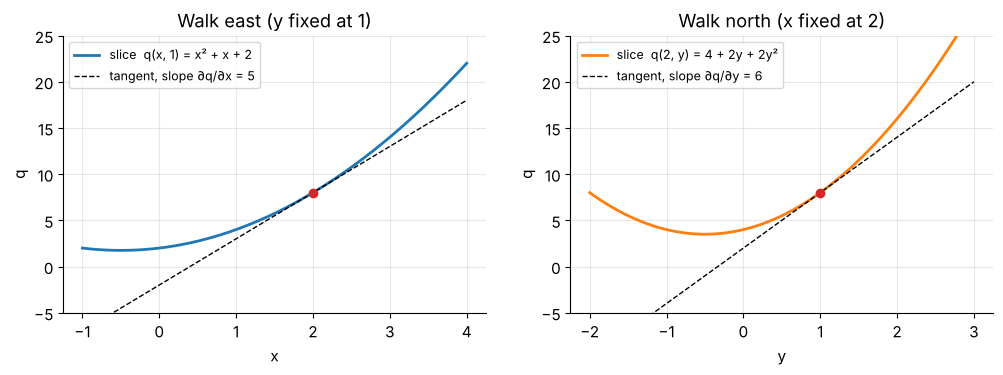

In [37]:
def q(x, y):
    """The tilted bowl q(x, y) = x^2 + x*y + 2*y^2 (works element-wise on arrays)."""
    return x**2 + x * y + 2 * y**2


def grad_q(x, y):
    """Gradient of q: the vector of its two partial derivatives."""
    return np.array([2 * x + y, x + 4 * y])


P = np.array([2.0, 1.0])
print(f"q(P) = {q(*P)},  partial derivatives at P = {grad_q(*P)}")
print(f"numerical check (central differences, Section 3): {numerical_gradient(lambda v: q(v[0], v[1]), P).round(6)}")

fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
s = np.linspace(-1, 4, 200)
axes[0].plot(s, q(s, 1.0), lw=2, label="slice  q(x, 1) = x² + x + 2")
axes[0].plot(s, q(2, 1) + 5 * (s - 2), "k--", lw=1, label="tangent, slope ∂q/∂x = 5")
axes[0].scatter([2], [q(2, 1)], color="C3", zorder=3)
axes[0].set(title="Walk east (y fixed at 1)", xlabel="x", ylabel="q", ylim=(-5, 25))
axes[0].legend(fontsize=9)
s = np.linspace(-2, 3, 200)
axes[1].plot(s, q(2.0, s), lw=2, color="C1", label="slice  q(2, y) = 4 + 2y + 2y²")
axes[1].plot(s, q(2, 1) + 6 * (s - 1), "k--", lw=1, label="tangent, slope ∂q/∂y = 6")
axes[1].scatter([1], [q(2, 1)], color="C3", zorder=3)
axes[1].set(title="Walk north (x fixed at 2)", xlabel="y", ylabel="q", ylim=(-5, 25))
axes[1].legend(fontsize=9)
plt.show()

### 6.2 The gradient vector and contour maps

Collect the partial derivatives into one vector, the **gradient**:

$$
\nabla f(x, y) = \begin{pmatrix} \partial f / \partial x \\ \partial f / \partial y \end{pmatrix},
\qquad\text{e.g.}\qquad \nabla q(2, 1) = \begin{pmatrix} 5 \\ 6 \end{pmatrix}.
$$

($\nabla$ is read "nabla" or "del".) In general, for a function of a parameter vector
$\boldsymbol\theta \in \mathbb{R}^d$, the gradient $\nabla f(\boldsymbol\theta) \in \mathbb{R}^d$ has one entry per
parameter: **the gradient always has the same shape as the parameters**, a handy sanity check in code.
Note that the gradient lives in the flat input plane (the map), not on the curved surface.

A **contour line** (level curve) is a set of points where $f$ has the same value, exactly the height
lines of a hiking map. The picture below shows the surface of $q$ and its contour map with the gradient
drawn as an arrow at a grid of points.

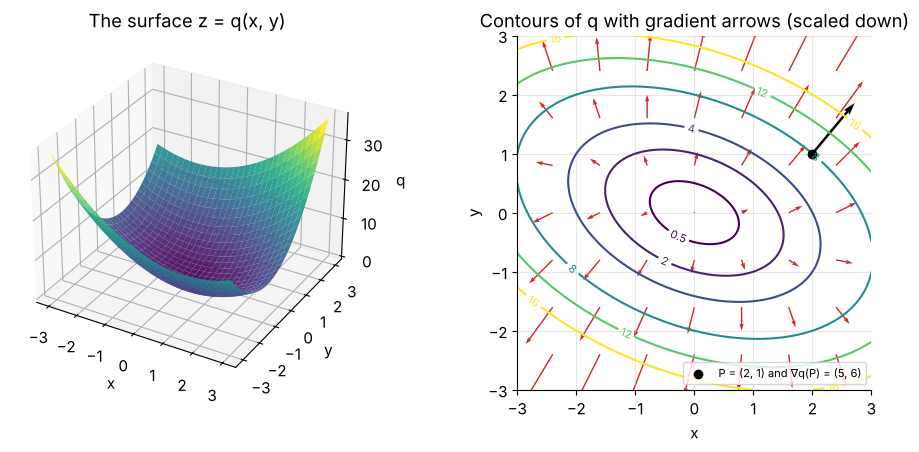

In [38]:
X2, Y2 = np.meshgrid(np.linspace(-3, 3, 121), np.linspace(-3, 3, 121))
Q2 = q(X2, Y2)
fig = plt.figure(figsize=(12, 4.6))
ax3d = fig.add_subplot(1, 2, 1, projection="3d")
ax3d.plot_surface(X2, Y2, Q2, cmap="viridis", alpha=0.9, linewidth=0, rcount=40, ccount=40)
ax3d.set(title="The surface z = q(x, y)", xlabel="x", ylabel="y", zlabel="q")
ax3d.view_init(elev=30, azim=-60)

ax = fig.add_subplot(1, 2, 2)
cs = ax.contour(X2, Y2, Q2, levels=[0.5, 2, 4, 8, 12, 16], cmap="viridis")
ax.clabel(cs, fontsize=8, fmt="%g")
gx, gy = np.meshgrid(np.linspace(-2.4, 2.4, 7), np.linspace(-2.4, 2.4, 7))
G = grad_q(gx, gy)
ax.quiver(gx, gy, G[0], G[1], color="C3", angles="xy", scale_units="xy", scale=14, width=0.004)
ax.quiver(*P, *grad_q(*P), color="k", angles="xy", scale_units="xy", scale=7, width=0.007)
ax.scatter(*P, color="k", zorder=3, label="P = (2, 1) and ∇q(P) = (5, 6)")
ax.set(title="Contours of q with gradient arrows (scaled down)", xlabel="x", ylabel="y",
       xlim=(-3, 3), ylim=(-3, 3))
ax.legend(fontsize=8, loc="lower right")
ax.set_aspect("equal")
plt.show()

Three facts jump out of the right panel, and the next subsection proves all of them:

1. Every arrow points **uphill**, towards higher contours.
2. Every arrow is **perpendicular to the contour line** through its base point.
3. Arrows are **long where contours are crowded** (steep ground) and short near the bottom of the bowl, and
   at the minimum $(0, 0)$ the gradient is the zero vector.

### 6.3 Directional derivatives and the direction of steepest descent

Partial derivatives measure the slope due east and due north. What about walking north-east, or in any
direction given by a **unit vector** $\mathbf{u}$ (length $\lVert \mathbf u \rVert = 1$)? That slope is the
**directional derivative**

$$
D_{\mathbf u} f(\boldsymbol\theta) = \lim_{h \to 0} \frac{f(\boldsymbol\theta + h\mathbf u) - f(\boldsymbol\theta)}{h} .
$$

To compute it we need the multivariable version of the tangent-line approximation. For a smooth $f$ and a
small step $\mathbf d = (d_x, d_y)$, move in two legs (first along $x$, then along $y$) and use the
one-variable approximation on each leg:

$$
f(x + d_x, y + d_y) - f(x, y) \approx \underbrace{\frac{\partial f}{\partial x}\,d_x}_{\text{east leg}} + \underbrace{\frac{\partial f}{\partial y}\,d_y}_{\text{north leg}}
\quad\Longrightarrow\quad
f(\boldsymbol\theta + \mathbf d) \approx f(\boldsymbol\theta) + \nabla f(\boldsymbol\theta)\cdot\mathbf d .
$$

(The second leg starts at $(x + d_x, y)$ instead of $(x, y)$, but for smooth $f$ that changes
$\partial f / \partial y$ only by an amount proportional to $d_x$, which makes a negligible second-order
contribution.) The same holds in any dimension: **near a point, $f$ behaves like the linear function
$\mathbf d \mapsto \nabla f \cdot \mathbf d$**. Putting $\mathbf d = h\mathbf u$:

$$
D_{\mathbf u} f(\boldsymbol\theta) = \nabla f(\boldsymbol\theta) \cdot \mathbf u .
$$

Now the key question for optimization: **which direction $\mathbf u$ decreases $f$ fastest?** The
**Cauchy–Schwarz inequality** says that for any vectors $\mathbf a, \mathbf b \in \mathbb R^d$,

$$
|\mathbf a \cdot \mathbf b| \le \lVert \mathbf a\rVert\,\lVert\mathbf b\rVert, \quad\text{with equality exactly when one vector is a multiple of the other.}
$$

*Why it holds (a classic olympiad argument):* if $\mathbf b = \mathbf 0$ there is nothing to prove.
Otherwise, for every real $t$, $0 \le \lVert \mathbf a - t\mathbf b\rVert^2 = \lVert\mathbf a\rVert^2 - 2t\,(\mathbf a\cdot\mathbf b) + t^2\lVert \mathbf b\rVert^2$.
A quadratic in $t$ that is never negative has at most one real root, so its discriminant is $\le 0$:
$4(\mathbf a\cdot\mathbf b)^2 - 4\lVert\mathbf a\rVert^2\lVert\mathbf b\rVert^2 \le 0$, which is the inequality.
Equality means the quadratic touches zero, i.e. $\mathbf a = t\mathbf b$ for some $t$.

Apply it with $\mathbf a = \nabla f$ and $\mathbf b = \mathbf u$ (so $\lVert \mathbf b\rVert = 1$):

$$
-\lVert \nabla f \rVert \;\le\; D_{\mathbf u} f = \nabla f \cdot \mathbf u \;\le\; \lVert \nabla f\rVert .
$$

> **Key idea (steepest descent).** The directional derivative is largest, equal to $\lVert\nabla f\rVert$,
> for $\mathbf u = \nabla f / \lVert \nabla f\rVert$: **the gradient points in the direction of steepest
> ascent, and its length is that steepest slope.** It is smallest, $-\lVert\nabla f\rVert$, for
> $\mathbf u = -\nabla f/\lVert\nabla f\rVert$: **the negative gradient is the direction of steepest descent.**
> Directions perpendicular to $\nabla f$ have slope 0: they run *along* the contour line, which is why
> the gradient is perpendicular to contours.

Let's measure the slope of $q$ at $P$ in every compass direction $\mathbf u = (\cos\varphi, \sin\varphi)$:

,∇q·u,difference quotient
direction φ (degrees),,
0.00,5.0000e+00,5.0000e+00
90.00,6.0000e+00,6.0000e+00
50.19,7.8102e+00,7.8103e+00
140.19,-1.5543e-15,9.1660e-07
230.19,-7.8102e+00,-7.8102e+00


|∇q(P)| = 7.8102; steepest ascent at φ = 50.19°, steepest descent at φ = 230.19°


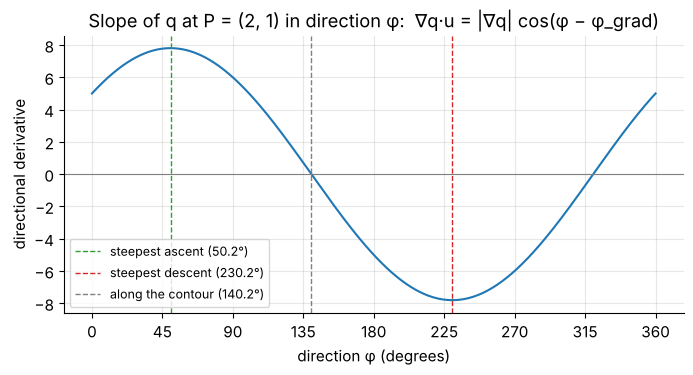

In [39]:
phis = np.linspace(0, 360, 721)
U = np.stack([np.cos(np.radians(phis)), np.sin(np.radians(phis))])     # unit vectors, shape (2, 721)
g_P = grad_q(*P)
slopes_dir = g_P @ U                                                    # D_u q = grad . u for every u
phi_up = np.degrees(np.arctan2(g_P[1], g_P[0]))

rows = []
for phi in [0, 90, phi_up, phi_up + 90, phi_up + 180]:
    u = np.array([np.cos(np.radians(phi)), np.sin(np.radians(phi))])
    hh = 1e-6
    numeric = (q(*(P + hh * u)) - q(*P)) / hh
    rows.append((round(phi, 2), g_P @ u, numeric))
display(pd.DataFrame(rows, columns=["direction φ (degrees)", "∇q·u", "difference quotient"])
        .set_index("direction φ (degrees)"))
print(f"|∇q(P)| = {np.linalg.norm(g_P):.4f}, steepest ascent at φ = {phi_up:.2f}°, steepest descent at "
      f"φ = {phi_up + 180:.2f}°")

fig, ax = plt.subplots(figsize=(8, 3.6))
ax.plot(phis, slopes_dir)
ax.axhline(0, color="gray", lw=0.8)
for val, lab, col in [(phi_up, "steepest ascent", "C2"), (phi_up + 180, "steepest descent", "C3"),
                      (phi_up + 90, "along the contour", "gray")]:
    ax.axvline(val, color=col, ls="--", lw=1, label=f"{lab} ({val:.1f}°)")
ax.set(title="Slope of q at P = (2, 1) in direction φ:  ∇q·u = |∇q| cos(φ − φ_grad)",
       xlabel="direction φ (degrees)", ylabel="directional derivative", xticks=range(0, 361, 45))
ax.legend(fontsize=9, loc="lower left")
plt.show()

The slope traces a cosine wave with amplitude $\lVert \nabla q(P)\rVert = \sqrt{5^2 + 6^2} = \sqrt{61} \approx 7.81$:
no direction is steeper than the gradient's own.

> **Common pitfall.** "Steepest descent" is a *local* statement. The negative gradient points straight
> down the slope where you stand, **not** at the minimum. At $P$ the direction to the minimum $(0, 0)$ is
> $(-2, -1)$, about $24°$ away from $-\nabla q(P) = (-5, -6)$. On round bowls the two coincide, while on stretched
> ones they can be almost perpendicular, and that is the root of the zig-zagging in Section 6.6.

### 6.4 Critical points in two variables: minima, maxima and saddles

At an interior minimum or maximum of a differentiable $f$, every directional derivative must be 0
(otherwise some direction would go downhill or uphill), so $\nabla f = \mathbf 0$: such points are again
called **critical points**. To classify them we need the second derivatives, collected in the
**Hessian matrix**

$$
\mathbf H = \nabla^2 f = \begin{pmatrix} \dfrac{\partial^2 f}{\partial x^2} & \dfrac{\partial^2 f}{\partial x\,\partial y} \\[2mm] \dfrac{\partial^2 f}{\partial y\,\partial x} & \dfrac{\partial^2 f}{\partial y^2} \end{pmatrix}
\qquad\text{e.g.}\qquad \nabla^2 q = \begin{pmatrix} 2 & 1 \\ 1 & 4 \end{pmatrix}.
$$

(For smooth functions the mixed partials are equal, so $\mathbf H$ is symmetric.) The second-order Taylor
expansion around a point $\boldsymbol\theta$ is

$$
f(\boldsymbol\theta + \mathbf d) \approx f(\boldsymbol\theta) + \nabla f(\boldsymbol\theta)\cdot\mathbf d + \tfrac12\,\mathbf d^\top \mathbf H\,\mathbf d .
$$

At a critical point the middle term vanishes, so the **quadratic form** $\mathbf d^\top\mathbf H\mathbf d$ decides
what happens nearby. Writing $\mathbf d$ in the basis of eigenvectors of $\mathbf H$ (which exist and are
perpendicular because $\mathbf H$ is symmetric) turns it into $\sum_i \lambda_i c_i^2$, where $\lambda_i$
are the eigenvalues of $\mathbf H$ and $c_i$ the coordinates of $\mathbf d$:

| eigenvalues of $\mathbf H$ | $\mathbf d^\top\mathbf H\mathbf d$ | the critical point is a |
|---|---|---|
| all $> 0$ | $> 0$ for every $\mathbf d \neq \mathbf 0$ | **local minimum** (a bowl) |
| all $< 0$ | $< 0$ for every $\mathbf d \neq \mathbf 0$ | **local maximum** (a dome) |
| some $> 0$, some $< 0$ | either sign, depending on $\mathbf d$ | **saddle point** |
| some $= 0$, the rest of one sign | $= 0$ along some direction | inconclusive (look closer) |

For $2\times2$ matrices there is a shortcut: $\det\mathbf H = \lambda_1\lambda_2$ and the trace is
$\lambda_1 + \lambda_2$, so $\det \mathbf H < 0$ means a saddle, and $\det\mathbf H > 0$ means a minimum if
$\partial^2 f/\partial x^2 > 0$ and a maximum if it is $< 0$. For $q$: $\det = 2\cdot4 - 1\cdot1 = 7 > 0$
and $2 > 0$, so $(0, 0)$ is a minimum.

A **saddle point** is the genuinely new phenomenon. Think of a mountain pass or a horse saddle: along the
ridge you are at a *minimum*, across it at a *maximum*. The classic example is $x^2 - y^2$ at the origin.

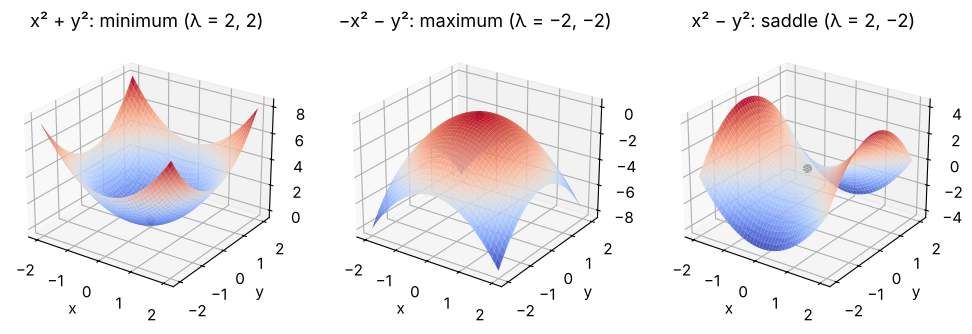

In [40]:
fig = plt.figure(figsize=(12, 3.8))
Xs, Ys = np.meshgrid(np.linspace(-2, 2, 41), np.linspace(-2, 2, 41))
for k, (Z, title) in enumerate([(Xs**2 + Ys**2, "x² + y²: minimum (λ = 2, 2)"),
                                (-Xs**2 - Ys**2, "−x² − y²: maximum (λ = −2, −2)"),
                                (Xs**2 - Ys**2, "x² − y²: saddle (λ = 2, −2)")], start=1):
    ax3d = fig.add_subplot(1, 3, k, projection="3d")
    ax3d.plot_surface(Xs, Ys, Z, cmap="coolwarm", linewidth=0, alpha=0.9)
    ax3d.scatter([0], [0], [0], color="k", s=30)
    ax3d.set(title=title, xlabel="x", ylabel="y")
    ax3d.view_init(elev=25, azim=-55)
plt.show()

**Why saddle points matter for gradient descent.** At a saddle the gradient is zero, so GD *can* stop
there, and near a saddle the gradient is small, so GD *slows down* there. Consider

$$
g(x, y) = x^2 + \tfrac14 y^4 - \tfrac12 y^2, \qquad \nabla g = \begin{pmatrix} 2x \\ y^3 - y \end{pmatrix}.
$$

Its critical points are $(0, 0)$ and $(0, \pm 1)$. The Hessian is $\begin{pmatrix} 2 & 0 \\ 0 & 3y^2 - 1\end{pmatrix}$:
at the origin the eigenvalues are $2$ and $-1$ (a **saddle**, $g = 0$), at $(0, \pm 1)$ they are $2$ and $2$
(two **minima**, $g = -\tfrac14$). Let's run GD with $\eta = 0.1$ from $(2, y_0)$ for three tiny values of $y_0$.

y0 = 0      : end point (0.000, 0.000), g =  0.0000, first iteration with g < -0.24: never
y0 = 0.0001 : end point (0.000, 1.000), g = -0.2500, first iteration with g < -0.24: 103
y0 = 0.01   : end point (0.000, 1.000), g = -0.2500, first iteration with g < -0.24: 55


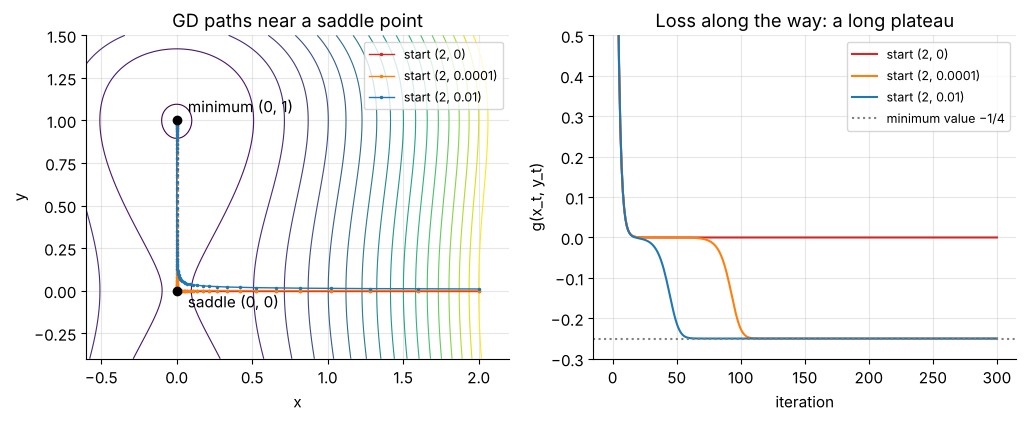

In [41]:
def g_saddle(x, y):
    return x**2 + y**4 / 4 - y**2 / 2


def grad_saddle(theta):
    x, y = theta
    return np.array([2 * x, y**3 - y])


fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
Xg, Yg = np.meshgrid(np.linspace(-0.6, 2.2, 200), np.linspace(-0.4, 1.5, 200))
axes[0].contour(Xg, Yg, g_saddle(Xg, Yg), levels=np.linspace(-0.24, 4, 18), cmap="viridis", linewidths=0.8)
for y0, col in [(0.0, "C3"), (1e-4, "C1"), (1e-2, "C0")]:
    path, _ = gradient_descent(grad_saddle, [2.0, y0], lr=0.1, max_iter=300, tol=0)
    vals = g_saddle(path[:, 0], path[:, 1])
    axes[0].plot(path[:, 0], path[:, 1], ".-", color=col, ms=3, lw=1, label=f"start (2, {y0:g})")
    axes[1].plot(vals, color=col, label=f"start (2, {y0:g})")
    below = np.flatnonzero(vals < -0.24)
    print(f"y0 = {y0:<7g}: end point ({path[-1, 0]:.3f}, {path[-1, 1]:.3f}), g = {vals[-1]: .4f}, "
          f"first iteration with g < -0.24: {below[0] if below.size else 'never'}")
axes[0].scatter([0, 0], [0, 1], color="k", zorder=3)
axes[0].annotate("saddle (0, 0)", (0, 0), textcoords="offset points", xytext=(8, -12))
axes[0].annotate("minimum (0, 1)", (0, 1), textcoords="offset points", xytext=(8, 6))
axes[0].set(title="GD paths near a saddle point", xlabel="x", ylabel="y")
axes[0].legend(fontsize=9, loc="upper right")
axes[1].axhline(-0.25, color="gray", ls=":", label="minimum value −1/4")
axes[1].set(title="Loss along the way: a long plateau", xlabel="iteration", ylabel="g(x_t, y_t)", ylim=(-0.3, 0.5))
axes[1].legend(fontsize=9)
plt.show()

- Starting **exactly** on the line $y = 0$, the $y$-component of the gradient is $0^3 - 0 = 0$ forever: GD
  slides straight into the saddle and stops there, believing it has converged (the gradient is zero!).
- Starting a hair off the line ($y_0 = 10^{-4}$), the $x$-coordinate converges quickly, but near $y = 0$ the
  update is $y_{t+1} = y_t - \eta(y_t^3 - y_t) \approx (1 + \eta)\,y_t$: $y$ grows by only 10% per step. It
  needs about $\ln(10^4)/\ln(1.1) \approx 97$ steps to grow from $10^{-4}$ to order 1, and during all that
  time the loss sits on a **plateau** at the saddle value 0, and it looks as if training has stalled. Then it
  suddenly drops to the minimum.
- From $y_0 = 10^{-2}$ the escape is about twice as fast, since only $\ln(10^2)/\ln(1.1) \approx 48$ steps
  of growth are needed.

> **Going deeper.** In high dimensions, saddle points vastly outnumber local minima: a critical point is a
> minimum only if *all* $d$ Hessian eigenvalues are positive, while a saddle just needs mixed signs. The
> plateaus they cause are a real feature of neural-network training. The tiny random perturbations of
> *stochastic* gradient descent (Section 10.8) help to escape them, much like $y_0 = 10^{-4}$ escaped above.

### ✏️ Exercise 5: classify a critical point from its Hessian

Write `classify_critical_point(H)` that returns `"minimum"`, `"maximum"`, `"saddle"` or `"inconclusive"`
for a symmetric Hessian matrix `H` of any size, following the eigenvalue table above. Treat eigenvalues
with $|\lambda| \le$ `tol` as zero. (Hint: `np.linalg.eigvalsh` computes the eigenvalues of a symmetric matrix.)

In [42]:
# ✏️ Exercise 5: classify a critical point from its Hessian
def classify_critical_point(H, tol=1e-12):
    """Return 'minimum', 'maximum', 'saddle' or 'inconclusive' for the symmetric Hessian H."""
    # YOUR CODE HERE
    raise NotImplementedError


def _test():
    cases = [
        (np.array([[2.0, 0.0], [0.0, 2.0]]), "minimum"),
        (np.array([[2.0, 1.0], [1.0, 4.0]]), "minimum"),          # the Hessian of q
        (np.array([[-1.0, 0.5], [0.5, -3.0]]), "maximum"),
        (np.array([[2.0, 0.0], [0.0, -1.0]]), "saddle"),          # g at the origin
        (np.array([[1.0, 3.0], [3.0, 1.0]]), "saddle"),           # positive diagonal, yet a saddle
        (np.array([[1.0, 1.0], [1.0, 1.0]]), "inconclusive"),     # eigenvalues 0 and 2
        (np.diag([3.0, 1.0, 2.0]), "minimum"),
        (np.diag([3.0, -1.0, 0.0]), "saddle"),                    # mixed signs win even with a zero
    ]
    for H, want in cases:
        got = classify_critical_point(H)
        assert got == want, f"for H = {H.tolist()} expected '{want}', got '{got}'"

run_check("Exercise 5", _test)

⏳ Exercise 5: not implemented yet; fill in the function and re-run this cell.


<details>
<summary><b>Solution</b> (try first!)</summary>

```python
def classify_critical_point(H, tol=1e-12):
    lam = np.linalg.eigvalsh(H)
    if np.any(lam > tol) and np.any(lam < -tol):
        return "saddle"
    if np.all(lam > tol):
        return "minimum"
    if np.all(lam < -tol):
        return "maximum"
    return "inconclusive"
```
The order of the tests matters: one positive and one negative eigenvalue already prove a saddle, whatever
the other eigenvalues are. The matrix $\begin{pmatrix}1&3\\3&1\end{pmatrix}$ is a good reminder that positive
diagonal entries are *not* enough for a minimum: along $\mathbf d = (1, -1)$ the form is $1 - 6 + 1 = -4 < 0$.
</details>

### 6.5 Gradient descent in several variables

The algorithm is the 1-D rule with the derivative replaced by the gradient:

$$
\boldsymbol\theta_{t+1} = \boldsymbol\theta_t - \eta\,\nabla f(\boldsymbol\theta_t),
\qquad\text{i.e.}\qquad
x_{t+1} = x_t - \eta\,\frac{\partial f}{\partial x}(x_t, y_t), \quad
y_{t+1} = y_t - \eta\,\frac{\partial f}{\partial y}(x_t, y_t).
$$

By Section 6.3 each step goes in the locally steepest downhill direction, and the first-order Taylor
expansion gives $f(\boldsymbol\theta_{t+1}) \approx f(\boldsymbol\theta_t) - \eta\lVert\nabla f(\boldsymbol\theta_t)\rVert^2$,
a decrease for small enough $\eta$, exactly as in 1-D.

> **Common pitfall.** Update all coordinates **simultaneously**, from the gradient at the *old* point. Updating
> $x$ first and then computing $\partial f/\partial y$ at the new $x$ is a different algorithm (coordinate
> descent). In code: compute the whole gradient vector first, then take the step.

**Worked example.** $f(x, y) = (x - 1)^2 + (y + 2)^2$, a round bowl with its minimum at $(1, -2)$ and gradient
$\nabla f = \big(2(x - 1),\, 2(y + 2)\big)$. Start at $(-3, 4)$ with $\eta = 0.25$:

| $t$ | $(x_t, y_t)$ | $\nabla f(x_t, y_t)$ | step $-\eta\nabla f$ | $f(x_t, y_t)$ |
|---|---|---|---|---|
| 0 | $(-3, 4)$ | $(-8, 12)$ | $(2, -3)$ | 52 |
| 1 | $(-1, 1)$ | $(-4, 6)$ | $(1, -1.5)$ | 13 |
| 2 | $(0, -0.5)$ | $(-2, 3)$ | $(0.5, -0.75)$ | 3.25 |
| 3 | $(0.5, -1.25)$ | $(-1, 1.5)$ | $(0.25, -0.375)$ | 0.8125 |

Each step halves the distance to $(1, -2)$ and divides $f$ by 4. In vector form,
$\boldsymbol\theta_{t+1} - \boldsymbol\theta^* = (1 - 2\eta)(\boldsymbol\theta_t - \boldsymbol\theta^*)$: on a round
bowl every coordinate shrinks by the same factor, so the path is a **straight line** to the minimum.

In [43]:
grad_round = lambda th: 2 * (th - np.array([1.0, -2.0]))
path_round, status = gradient_descent(grad_round, [-3.0, 4.0], lr=0.25, max_iter=100, tol=1e-6)
print("first iterates:\n", path_round[:5])
print(f"{status} after {len(path_round) - 1} steps at {path_round[-1].round(6)}")

first iterates:
 [[-3.     4.   ]
 [-1.     1.   ]
 [ 0.    -0.5  ]
 [ 0.5   -1.25 ]
 [ 0.75  -1.625]]
converged after 24 steps at [ 1. -2.]


### 6.6 Ill-conditioned bowls: zig-zags and the condition number

Now stretch the bowl: $f(x, y) = x^2 + 25y^2$, whose contours are ellipses 5 times longer in $x$ than in $y$.
The gradient is $(2x,\ 50y)$, so the GD update **decouples** into two independent 1-D problems:

$$
x_{t+1} = (1 - 2\eta)\,x_t, \qquad y_{t+1} = (1 - 50\eta)\,y_t .
$$

Each coordinate is the quadratic of Section 5.4, with curvatures $2$ and $50$ (the eigenvalues of the
Hessian $\mathrm{diag}(2, 50)$). Both must contract:

- The **steep** direction sets the speed limit: $|1 - 50\eta| < 1 \iff \eta < 2/50 = 0.04$.
- The **flat** direction then crawls: even at $\eta = 0.04$, $x$ shrinks only by the factor $1 - 0.08 = 0.92$ per step.

The best compromise makes the two factors equal in size: $1 - 2\eta = -(1 - 50\eta)$ gives $\eta = 2/52 = 1/26$,
and both factors become $\pm 24/26 \approx 0.923$. Let's look at three learning rates.

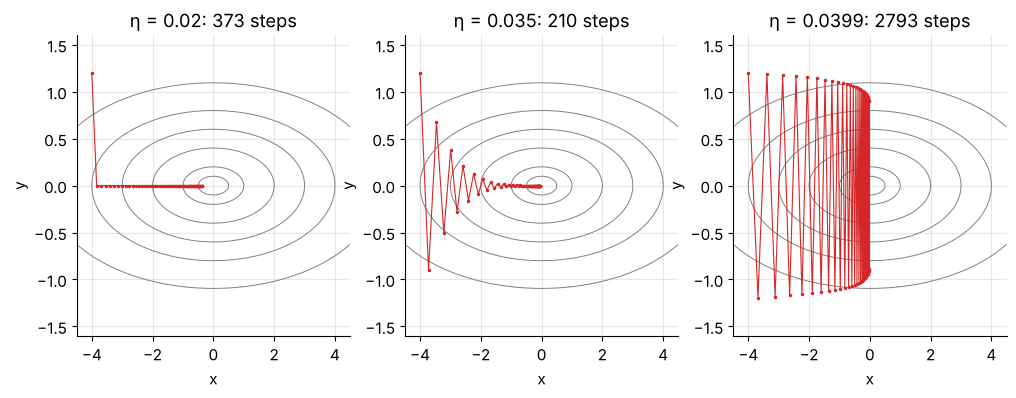

,x factor 1−2η,y factor 1−50η,steps to reach 1e-6,outcome
eta,,,,
0.0050,0.9900,0.7500,1513,converges
0.0100,0.9800,0.5000,753,converges
0.0200,0.9600,0.0000,373,converges
0.0300,0.9400,-0.5000,246,converges
0.0350,0.9300,-0.7500,210,converges
0.0385,0.9231,-0.9231,191,converges
0.0390,0.9220,-0.9500,273,converges
0.0399,0.9202,-0.9950,2793,converges
0.0410,0.9180,-1.0500,never,diverged


In [44]:
f_ill = lambda P: P[..., 0] ** 2 + 25 * P[..., 1] ** 2
grad_ill = lambda th: np.array([2 * th[0], 50 * th[1]])
start_ill = [-4.0, 1.2]


def steps_to_reach(path, target, tol=1e-6):
    """First iteration t at which path[t] is within distance tol of target ('never' if it does not happen)."""
    hits = np.flatnonzero(np.linalg.norm(path - np.asarray(target), axis=1) < tol)
    return int(hits[0]) if hits.size else "never"


Xi, Yi = np.meshgrid(np.linspace(-4.5, 4.5, 300), np.linspace(-1.6, 1.6, 200))
fig, axes = plt.subplots(1, 3, figsize=(12, 3.9))
for ax, eta in zip(axes, [0.02, 0.035, 0.0399]):
    path, _ = gradient_descent(grad_ill, start_ill, lr=eta, max_iter=5000, tol=0)
    ax.contour(Xi, Yi, f_ill(np.stack([Xi, Yi], axis=-1)), levels=[0.25, 1, 4, 9, 16, 30], colors="gray",
               linewidths=0.7)
    ax.plot(path[:60, 0], path[:60, 1], ".-", color="C3", ms=3, lw=0.8)
    ax.set(title=f"η = {eta}: {steps_to_reach(path, [0, 0])} steps", xlabel="x", ylabel="y")
plt.show()

rows = []
for eta in [0.005, 0.01, 0.02, 0.03, 0.035, 1 / 26, 0.039, 0.0399, 0.041]:
    path, status = gradient_descent(grad_ill, start_ill, lr=eta, max_iter=5000, tol=0)
    rows.append((round(eta, 5), 1 - 2 * eta, 1 - 50 * eta, steps_to_reach(path, [0, 0]),
                 "diverged" if status == "diverged" else "converges"))
display(pd.DataFrame(rows, columns=["eta", "x factor 1−2η", "y factor 1−50η", "steps to reach 1e-6",
                                    "outcome"]).set_index("eta"))

(The plots show the first 60 steps, and "steps" counts iterations until the distance to the minimum drops
below $10^{-6}$.)

- $\eta = 0.02$ kills the $y$-error in one step ($1 - 50\eta = 0$) and then creeps along the valley floor with
  factor $0.96$: 373 steps.
- $\eta = 0.035$ zig-zags across the narrow valley (factor $-0.75$ in $y$) while making better progress in $x$: 210 steps.
- $\eta = 0.0399$ sits right under the speed limit: the $y$-factor is $-0.995$, so the zig-zag barely decays and it
  takes 2793 steps. At $\eta = 0.041$ the zig-zag grows and GD diverges.
- The best fixed learning rate, $\eta = 1/26$, needs 191 steps. Compare a **round** bowl $x^2 + y^2$, where
  $\eta = 0.5$ reaches the minimum in **one** step.

**The general picture.** For any quadratic bowl $f(\boldsymbol\theta) = \tfrac12\boldsymbol\theta^\top\mathbf H\boldsymbol\theta$
with a symmetric positive-definite Hessian $\mathbf H$ (eigenvalues $0 < \lambda_{\min} \le \dots \le \lambda_{\max}$),
GD is $\boldsymbol\theta_{t+1} = (\mathbf I - \eta\mathbf H)\,\boldsymbol\theta_t$, and in the eigenvector basis each component is
multiplied by $1 - \eta\lambda_i$ per step. Therefore:

$$
\text{GD converges} \iff 0 < \eta < \frac{2}{\lambda_{\max}}, \qquad
\eta_{\text{best}} = \frac{2}{\lambda_{\min} + \lambda_{\max}}, \qquad
\text{rate}_{\text{best}} = \frac{\kappa - 1}{\kappa + 1}, \qquad \kappa = \frac{\lambda_{\max}}{\lambda_{\min}} .
$$

The ratio $\kappa$ is the **condition number** of the bowl: how much more sharply it curves in its steepest
direction than in its flattest. For $x^2 + 25y^2$, $\kappa = 50/2 = 25$ and the best rate is $24/26$. Since
$\ln\frac{\kappa - 1}{\kappa + 1} \approx -\frac{2}{\kappa}$ for large $\kappa$, **the number of iterations grows
roughly in proportion to $\kappa$**: a bowl with $\kappa = 10^4$ needs thousands of times more steps than a round one.

> **Key idea.** Gradient descent is fast on round bowls and slow on stretched ones. The learning rate is capped
> by the *sharpest* curvature, but progress is limited by the *flattest*.

### ✏️ Exercise 6: a speedometer for quadratic bowls

Implement `gd_speed(H)` for a symmetric positive-definite Hessian `H`. It returns a dictionary with
`"lr_max"` $= 2/\lambda_{\max}$, `"lr_best"` $= 2/(\lambda_{\min} + \lambda_{\max})$, `"kappa"` $= \lambda_{\max}/\lambda_{\min}$
and `"rate"` $= (\kappa - 1)/(\kappa + 1)$. The checker also runs GD with your `lr_best` on a rotated bowl and
confirms that the error shrinks at your predicted `rate`.

In [45]:
# ✏️ Exercise 6: a speedometer for quadratic bowls
def gd_speed(H):
    """Speed limit, best learning rate, condition number and best rate of GD on 0.5 * theta^T H theta."""
    # YOUR CODE HERE
    raise NotImplementedError


def _test():
    out = gd_speed(np.diag([2.0, 50.0]))
    assert set(out) >= {"lr_max", "lr_best", "kappa", "rate"}, "return a dict with the four keys"
    assert np.isclose(out["lr_max"], 0.04) and np.isclose(out["lr_best"], 1 / 26), f"got {out}"
    assert np.isclose(out["kappa"], 25) and np.isclose(out["rate"], 24 / 26), f"got {out}"
    R = np.array([[np.cos(0.6), -np.sin(0.6)], [np.sin(0.6), np.cos(0.6)]])
    H = R @ np.diag([1.0, 9.0]) @ R.T                     # a tilted bowl with eigenvalues 1 and 9
    out = gd_speed(H)
    assert np.isclose(out["kappa"], 9) and np.isclose(out["rate"], 0.8), f"tilted bowl: got {out}"
    theta = np.array([3.0, -2.0])
    for _ in range(30):
        theta = theta - out["lr_best"] * (H @ theta)
    assert np.linalg.norm(theta) <= 1.0001 * 0.8**30 * np.linalg.norm([3.0, -2.0]), \
        "with lr_best the error should shrink at least as fast as rate**t"

run_check("Exercise 6", _test)

⏳ Exercise 6: not implemented yet; fill in the function and re-run this cell.


<details>
<summary><b>Solution</b> (try first!)</summary>

```python
def gd_speed(H):
    lam = np.linalg.eigvalsh(H)          # sorted ascending
    lo, hi = lam[0], lam[-1]
    kappa = hi / lo
    return {"lr_max": 2 / hi, "lr_best": 2 / (lo + hi), "kappa": kappa, "rate": (kappa - 1) / (kappa + 1)}
```
With $\eta = 2/(\lambda_{\min} + \lambda_{\max})$ the factors $1 - \eta\lambda_{\min}$ and $1 - \eta\lambda_{\max}$ are
$\pm\frac{\lambda_{\max} - \lambda_{\min}}{\lambda_{\max} + \lambda_{\min}} = \pm\frac{\kappa - 1}{\kappa + 1}$, and every
eigenvalue in between gives a smaller factor, so the whole error vector shrinks at least that fast.
</details>

### 6.7 Feature scaling makes the bowl round

The stretched bowl is only stretched *in the coordinates we chose*. Measure $y$ in different units,
$u = 5y$, and the same function becomes

$$
f = x^2 + 25y^2 = x^2 + u^2 ,
$$

a perfectly round bowl ($\kappa = 1$) on which GD with $\eta = 0.5$ lands on the minimum in a single step.

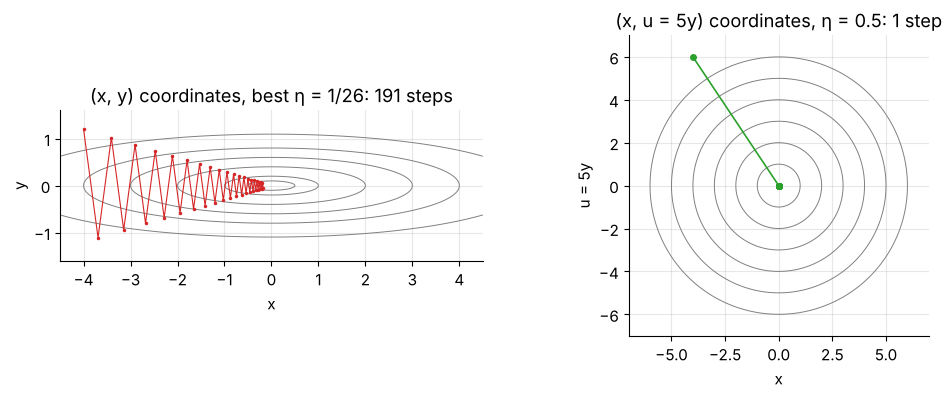

In [46]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.9))
path, _ = gradient_descent(grad_ill, start_ill, lr=1 / 26, max_iter=5000, tol=0)
axes[0].contour(Xi, Yi, f_ill(np.stack([Xi, Yi], axis=-1)), levels=[0.25, 1, 4, 9, 16, 30], colors="gray",
                linewidths=0.7)
axes[0].plot(path[:40, 0], path[:40, 1], ".-", color="C3", ms=3, lw=0.8)
axes[0].set(title=f"(x, y) coordinates, best η = 1/26: {steps_to_reach(path, [0, 0])} steps",
            xlabel="x", ylabel="y")
axes[0].set_aspect("equal")

grad_round0 = lambda th: 2 * th                                  # gradient of x^2 + u^2
path_u, _ = gradient_descent(grad_round0, [start_ill[0], 5 * start_ill[1]], lr=0.5, max_iter=10, tol=0)
Xu, Uu = np.meshgrid(np.linspace(-7, 7, 200), np.linspace(-7, 7, 200))
axes[1].contour(Xu, Uu, Xu**2 + Uu**2, levels=[1, 4, 9, 16, 25, 36], colors="gray", linewidths=0.7)
axes[1].plot(path_u[:, 0], path_u[:, 1], "o-", color="C2", ms=4, lw=1.2)
axes[1].set(title=f"(x, u = 5y) coordinates, η = 0.5: {steps_to_reach(path_u, [0, 0])} step",
            xlabel="x", ylabel="u = 5y")
axes[1].set_aspect("equal")
plt.show()

Nothing about the *problem* changed, only the units, yet the algorithm went from hundreds of steps to one.
Two ways to read this:

1. **Rescaling variables changes the shape of the loss surface** that GD sees. In machine learning the
   "coordinates" are the model's weights, and the curvature in the direction of a weight is governed by the
   scale of the feature it multiplies: a feature measured in large numbers creates a steep direction, a feature
   with small numbers a flat one. Putting all features on a common scale (Sections 9.7 and 10.5) rounds the bowl.
2. GD on $(x, u)$ is the same as GD on $(x, y)$ with a **separate learning rate per coordinate**:
   $u_{t+1} = u_t - 0.5\cdot 2u_t$ translates to $y_{t+1} = y_t - \frac{0.5}{25}\cdot 50\,y_t$, i.e. $\eta_y = 0.02$ while
   $\eta_x = 0.5$. Adaptive optimizers such as AdaGrad, RMSProp and Adam learn such per-parameter step sizes
   automatically (this is called *preconditioning*).

> **Common pitfall.** Scaling cures stretching *along the coordinate axes*. If the valley is tilted (because two
> features are strongly correlated), rescaling each feature separately cannot make it round. Section 11 meets
> exactly this situation.

### 6.8 Momentum: a teaser

Picture a heavy ball rolling down the stretched valley. Along the valley floor the gradient keeps pointing the
same way, so a ball with inertia accumulates speed there, while across the valley the pushes alternate in sign and
partly cancel. The **heavy-ball (momentum)** method keeps a running "velocity" $\mathbf v$:

$$
\mathbf v_{t+1} = \beta\,\mathbf v_t + \nabla f(\boldsymbol\theta_t), \qquad
\boldsymbol\theta_{t+1} = \boldsymbol\theta_t - \eta\,\mathbf v_{t+1}, \qquad \mathbf v_0 = \mathbf 0,
$$

where $\beta \in [0, 1)$ is the momentum coefficient ($\beta = 0$ is plain GD). For quadratic bowls the best
constants are known: $\eta = 4/(\sqrt{\lambda_{\max}} + \sqrt{\lambda_{\min}})^2$ and
$\beta = \big((\sqrt\kappa - 1)/(\sqrt\kappa + 1)\big)^2$, which improves the rate from $\frac{\kappa - 1}{\kappa + 1}$ to
$\frac{\sqrt\kappa - 1}{\sqrt\kappa + 1}$, so the iteration count scales with $\sqrt\kappa$ instead of $\kappa$.
For our bowl ($\lambda = 2, 50$, $\kappa = 25$): $\eta = 4/72 \approx 0.0556$, $\beta = (4/6)^2 \approx 0.444$, and the
rate drops from $0.923$ to $0.667$.

plain GD, η = 1/26: within 1e-6 of the minimum after 191 steps
momentum, η = 0.0556, β = 0.444: within 1e-6 of the minimum after 46 steps


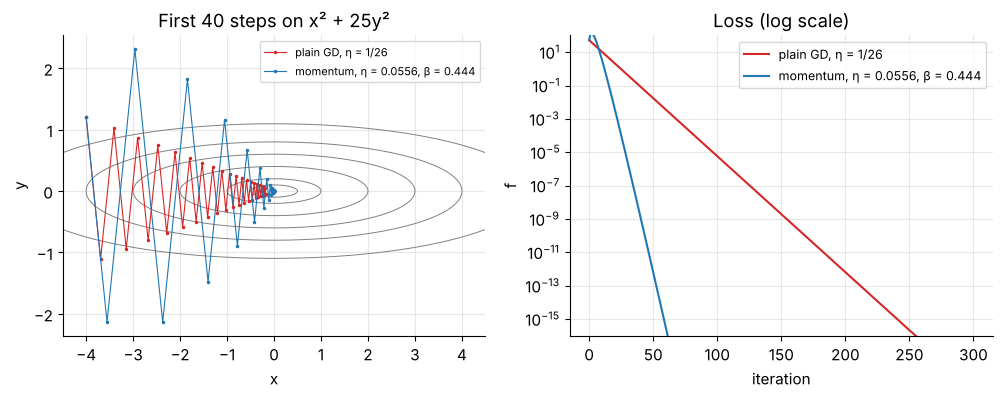

In [47]:
def heavy_ball(grad, theta0, lr, beta, n_steps):
    """Gradient descent with (heavy-ball) momentum, and returns all iterates, shape (n_steps + 1, d)."""
    theta = np.array(theta0, dtype=float)
    v = np.zeros_like(theta)
    path = [theta.copy()]
    for _ in range(n_steps):
        v = beta * v + grad(theta)
        theta = theta - lr * v
        path.append(theta.copy())
    return np.array(path)


lam_lo, lam_hi = 2.0, 50.0
lr_hb = 4 / (np.sqrt(lam_hi) + np.sqrt(lam_lo)) ** 2
beta_hb = ((np.sqrt(lam_hi / lam_lo) - 1) / (np.sqrt(lam_hi / lam_lo) + 1)) ** 2
runs = {"plain GD, η = 1/26": heavy_ball(grad_ill, start_ill, 1 / 26, 0.0, 300),
        f"momentum, η = {lr_hb:.4f}, β = {beta_hb:.3f}": heavy_ball(grad_ill, start_ill, lr_hb, beta_hb, 300)}

fig, axes = plt.subplots(1, 2, figsize=(12, 3.9))
axes[0].contour(Xi, Yi, f_ill(np.stack([Xi, Yi], axis=-1)), levels=[0.25, 1, 4, 9, 16, 30], colors="gray",
                linewidths=0.7)
for (name, path), col in zip(runs.items(), ["C3", "C0"]):
    print(f"{name}: within 1e-6 of the minimum after {steps_to_reach(path, [0, 0])} steps")
    axes[0].plot(path[:40, 0], path[:40, 1], ".-", color=col, ms=3, lw=0.8, label=name)
    axes[1].semilogy(f_ill(path), color=col, label=name)
axes[0].set(title="First 40 steps on x² + 25y²", xlabel="x", ylabel="y")
axes[0].legend(fontsize=8, loc="upper right")
axes[1].set(title="Loss (log scale)", xlabel="iteration", ylabel="f", ylim=(1e-16, 1e2))
axes[1].legend(fontsize=9)
plt.show()

Momentum needs about a quarter of the steps here, and the gap widens as $\kappa$ grows ($\sqrt{10^4} = 100$
versus $10^4$). Notice in the left panel that the ball is not "smoother" at first: with these aggressive
settings it sloshes across the valley even more than plain GD, but it races along the floor, and *every*
component of its error dies out at the faster rate $0.667$. In practice $\beta = 0.9$ is a common default,
and momentum is built into the optimizers you will use in deep learning
(`torch.optim.SGD(..., momentum=0.9)`, and the first-moment average inside Adam).

**Quick check.** For $f(x, y) = 4x^2 + y^2$ (note: the Hessian is $\mathrm{diag}(8, 2)$), what is the largest
learning rate for which plain GD converges, which fixed learning rate is best, and what is the condition number?

<details>
<summary>Answer</summary>

$\lambda_{\max} = 8$, $\lambda_{\min} = 2$: GD converges iff $0 < \eta < 2/8 = 0.25$, and the best rate is achieved at
$\eta = 2/(2 + 8) = 0.2$, where both factors $1 - 0.2\cdot 2 = 0.6$ and $1 - 0.2\cdot 8 = -0.6$ have size
$0.6 = (\kappa - 1)/(\kappa + 1)$ with $\kappa = 4$.
</details>

## 7. The chain rule, computational graphs and backpropagation

Real losses are built by *composing* simple pieces: a linear function of the parameters, fed into a
nonlinearity, fed into a squared error, averaged over the data. The chain rule (Section 2.5) is the tool
that differentiates such compositions, and **backpropagation** is nothing more than the chain rule applied
in a clever order.

### 7.1 Gradient descent on a composite function

Take $h(x) = (x^2 - 2)^2$. It is a composition of an **inner** function $u = x^2 - 2$ and an **outer** function
$h = u^2$. The chain rule multiplies the two rates of change:

$$
\frac{dh}{dx} = \frac{dh}{du}\cdot\frac{du}{dx} = \underbrace{2u}_{\text{outer}}\cdot\underbrace{2x}_{\text{inner}}
= 4x\,(x^2 - 2).
$$

Each factor tells a story. $dh/du = 2u$ says how sensitive the square is to its input, and $du/dx = 2x$ says how
sensitive the inner function is to $x$. **A product is zero when either factor is zero**, so the critical
points of a composition come from two sources:

- $x^2 - 2 = 0$, i.e. $x = \pm\sqrt2$: the *outer* slope vanishes. There $h = 0$, the smallest possible value
  of a square, and these are the two global minima.
- $x = 0$: the *inner* slope vanishes. There $u = -2$ is at its smallest, so $h = 4$ is a local **maximum** of $h$.

The gradient-descent update is $x_{t+1} = x_t - \eta\cdot 4x_t(x_t^2 - 2)$. With $x_0 = 2$ and $\eta = 0.05$, by hand:

$$
x_1 = 2 - 0.05\cdot\underbrace{4\cdot 2\cdot(4 - 2)}_{16} = 1.2, \qquad
x_2 = 1.2 - 0.05\cdot\underbrace{4\cdot1.2\cdot(1.44 - 2)}_{-2.688} = 1.3344, \;\dots
$$

Minimizing $h$ means solving $x^2 = 2$, so GD is about to compute $\sqrt 2 \approx 1.414214$:

In [48]:
def h_comp(x):
    return (x**2 - 2) ** 2


def dh_comp(x):
    u = x**2 - 2                    # inner function value
    return (2 * u) * (2 * x)        # (outer slope dh/du) * (inner slope du/dx)


x, rows = 2.0, []
for t in range(7):
    u = x**2 - 2
    rows.append((t, x, u, 2 * u, 2 * x, dh_comp(x), h_comp(x)))
    x = x - 0.05 * dh_comp(x)
display(pd.DataFrame(rows, columns=["t", "x_t", "u = x²−2", "dh/du = 2u", "du/dx = 2x", "h'(x_t)", "h(x_t)"])
        .set_index("t"))
print(f"sqrt(2) = {math.sqrt(2):.6f},  local contraction factor near the minimum: 1 - eta*h''(sqrt 2) = "
      f"1 - 0.05*16 = {1 - 0.05 * 16:.1f}")

,x_t,u = x²−2,dh/du = 2u,du/dx = 2x,h'(x_t),h(x_t)
t,,,,,,
0,2.0000,2.0000,4.0000,4.0000,16.0000,4.0000e+00
1,1.2000,-0.5600,-1.1200,2.4000,-2.6880,3.1360e-01
2,1.3344,-0.2194,-0.4388,2.6688,-1.1709,4.8126e-02
3,1.3929,-0.0597,-0.1194,2.7859,-0.3326,3.5639e-03
4,1.4096,-0.0131,-0.0262,2.8192,-0.0738,1.7131e-04
5,1.4133,-0.0027,-0.0053,2.8265,-0.0151,7.1429e-06
6,1.4140,-0.0005,-0.0011,2.8280,-0.0030,2.8816e-07


sqrt(2) = 1.414214;  local contraction factor near the minimum: 1 - eta*h''(sqrt 2) = 1 - 0.05*16 = 0.2


Near $\sqrt 2$ the curvature is $h''(\sqrt2) = 12\cdot 2 - 8 = 16$, so by Section 5.4 the error shrinks by
about $|1 - 0.05\cdot 16| = 0.2$ per step, five times smaller each step, as the table shows.

Where GD ends up depends on where it starts:

start  ->  end after 200 steps (eta = 0.05)
  0.3  ->   1.414214
 -0.5  ->  -1.414214
  0.0  ->   0.000000
  3.0  ->  -1.414214


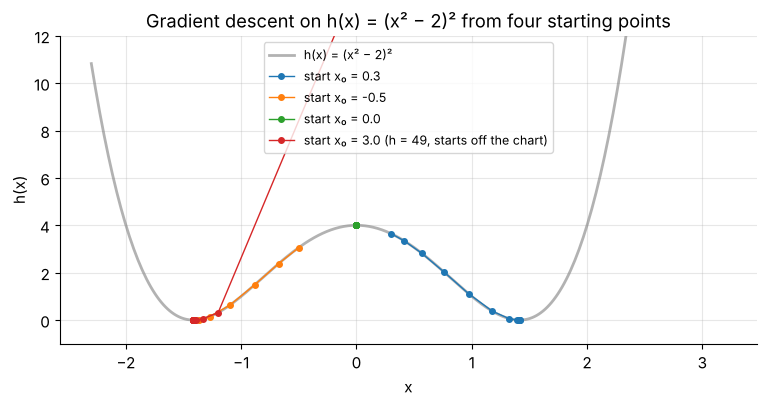

In [49]:
xx = np.linspace(-2.3, 3.2, 300)
fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(xx, h_comp(xx), color="gray", lw=2, alpha=0.6, label="h(x) = (x² − 2)²")
print("start  ->  end after 200 steps (eta = 0.05)")
for x0, col in [(0.3, "C0"), (-0.5, "C1"), (0.0, "C2"), (3.0, "C3")]:
    path = gd_path_1d(dh_comp, x0, 0.05, 200)
    print(f"{x0:5.1f}  ->  {path[-1]: .6f}")
    note = " (h = 49, starts off the chart)" if x0 == 3.0 else ""
    ax.plot(path[:12], h_comp(path[:12]), "o-", color=col, ms=4, lw=1, label=f"start x₀ = {x0}{note}")
ax.set(title="Gradient descent on h(x) = (x² − 2)² from four starting points", xlabel="x", ylabel="h(x)",
       ylim=(-1, 12))
ax.legend(fontsize=9)
plt.show()

- From $x_0 = 0.3$ GD rolls right into $+\sqrt 2$, and from $x_0 = -0.5$ it rolls left into $-\sqrt2$.
- From $x_0 = 0$ it **never moves**: the gradient at the local maximum is exactly 0 (the inner slope $2x$ is 0).
- From $x_0 = 3$ the slope is huge ($h'(3) = 84$), the first step jumps to $3 - 0.05\cdot 84 = -1.2$ (*across* the
  hump), and GD ends in the *other* valley at $-\sqrt2$. With non-convex functions, a big step can change which
  minimum you reach (Section 8.4 returns to this).

### 7.2 The chain rule with several variables

Suppose $z = g(u, v)$ depends on two intermediate quantities, each of which depends on $x$ and $y$. Nudge $x$ by
a small $\Delta x$. Then $u$ changes by about $\frac{\partial u}{\partial x}\Delta x$ and $v$ by about
$\frac{\partial v}{\partial x}\Delta x$, and by the linear approximation of Section 6.3 the total change of $z$ is
$\frac{\partial z}{\partial u}\Delta u + \frac{\partial z}{\partial v}\Delta v$. Dividing by $\Delta x$:

$$
\frac{\partial z}{\partial x} = \frac{\partial z}{\partial u}\,\frac{\partial u}{\partial x} + \frac{\partial z}{\partial v}\,\frac{\partial v}{\partial x},
\qquad
\frac{\partial z}{\partial y} = \frac{\partial z}{\partial u}\,\frac{\partial u}{\partial y} + \frac{\partial z}{\partial v}\,\frac{\partial v}{\partial y}.
$$

> **Key idea (multivariable chain rule).** The derivative of the output with respect to an input is the
> **sum over all paths** from that input to the output of the **product of the local derivatives** along the path.

**Example.** $z = u^2 + uv$ with $u = 2x + y$ and $v = xy$, at the point $(x, y) = (1, 3)$, where $u = 5$, $v = 3$, $z = 40$.

```
    x ─┬──────────┐
       │          ├──► u = 2x + y ──┐
    y ─┼──┬───────┘                 ├──► z = u² + u·v
       │  │                         │
       └──┼───────┐                 │
          │       ├──► v = x · y ───┘
          └───────┘
```

(Where two lines cross at `┼`, they pass over each other without joining.)

| edge | local derivative | value at $(1, 3)$ |
|---|---|---|
| $u \to z$ | $\partial z/\partial u = 2u + v$ | $13$ |
| $v \to z$ | $\partial z/\partial v = u$ | $5$ |
| $x \to u$, $y \to u$ | $\partial u/\partial x = 2$, $\partial u/\partial y = 1$ | $2$, $1$ |
| $x \to v$, $y \to v$ | $\partial v/\partial x = y$, $\partial v/\partial y = x$ | $3$, $1$ |

There are two paths from $x$ to $z$ (through $u$ and through $v$), so
$\frac{\partial z}{\partial x} = 13\cdot 2 + 5\cdot 3 = 41$, and likewise $\frac{\partial z}{\partial y} = 13\cdot1 + 5\cdot 1 = 18$.
Let's confirm by brute force: substitute everything to get $z$ as an explicit function of $x$ and $y$, and
differentiate that with SymPy and numerically.

In [50]:
xs_, ys_ = sp.symbols("x y")
u_expr, v_expr = 2 * xs_ + ys_, xs_ * ys_
z_expr = u_expr**2 + u_expr * v_expr
grad_sym = [sp.diff(z_expr, var).subs({xs_: 1, ys_: 3}) for var in (xs_, ys_)]
print("z(x, y) =", sp.expand(z_expr))
print("SymPy gradient at (1, 3):", grad_sym)


def z_of(v):
    uu, vv = 2 * v[0] + v[1], v[0] * v[1]
    return uu**2 + uu * vv


print("numerical gradient at (1, 3):", numerical_gradient(z_of, [1.0, 3.0]).round(6))

z(x, y) = 2*x**2*y + 4*x**2 + x*y**2 + 4*x*y + y**2
SymPy gradient at (1, 3): [41, 18]
numerical gradient at (1, 3): [41. 18.]


> **Going deeper.** In matrix language, if $\mathbf u = \mathbf g(\mathbf x)$ maps $\mathbb R^n \to \mathbb R^k$ and
> $z = f(\mathbf u)$, then $\nabla_{\mathbf x} z = \mathbf J^\top \nabla_{\mathbf u} z$, where $\mathbf J \in \mathbb R^{k\times n}$
> is the **Jacobian** matrix of $\mathbf g$ (entry $J_{ij} = \partial u_i/\partial x_j$). The "sum over paths" is exactly
> what the matrix–vector product computes.

### 7.3 Computational graphs: a forward pass and a backward pass

A **computational graph** breaks a computation into elementary operations (nodes) connected by arrows that
carry values. Differentiating it takes two sweeps:

1. **Forward pass:** compute every node's value from its inputs, from left to right, and *remember* them
   (the local derivatives need them: $\partial z/\partial u = 2u + v$ needs $u$ and $v$).
2. **Backward pass:** for every node $n$, compute its **adjoint** $\bar n = \partial(\text{output})/\partial n$, from
   right to left. Start with $\bar z = 1$. A node's adjoint is the sum, over the nodes it feeds into, of
   (that node's adjoint) $\times$ (the local derivative along the arrow).

For the example: $\bar z = 1$, $\bar u = \bar z\cdot(2u + v) = 13$, $\bar v = \bar z\cdot u = 5$,
$\bar x = \bar u\cdot 2 + \bar v\cdot y = 41$, and $\bar y = \bar u\cdot 1 + \bar v\cdot x = 18$. Same numbers as the
path sums, but organized so that **each local derivative is used once**, and shared sub-paths (like
$z \to u$) are not recomputed for every input.

Why right-to-left? A loss has **one** output and possibly **millions** of inputs (the parameters). One backward
pass delivers the derivative with respect to *all* of them, at a cost comparable to one forward pass. A numerical
gradient (Section 3.4) needs two forward passes *per parameter*. This asymmetry is why backpropagation
(also called **reverse-mode automatic differentiation**) made training large neural networks possible.

### 7.4 Backpropagation by hand through a single neuron

Here is the smallest "neural network" worth the name: one neuron with a sigmoid, trained with squared error on
a single example $\mathbf x = (x_1, x_2) = (2, -1)$ with target $y = 1$. Parameters: $w_1 = 0.5$, $w_2 = -0.3$, $b = 0.1$.

```
  data x1, x2      parameters w1, w2, b                          target y
       │                     │                                      │
       └──────────┬──────────┘                                      ▼
                  ▼                                          ┌──────────────┐
     ┌───────────────────────┐        ┌────────────┐         │              │
     │ z = w1·x1 + w2·x2 + b │ ─────► │  a = σ(z)  │ ──────► │ L = (a − y)² │ ──► L
     └───────────────────────┘        └────────────┘         └──────────────┘
        node 1: linear                node 2: sigmoid        node 3: squared error
```

**Forward pass** (keep 6 decimals):

| node | computation | value |
|---|---|---|
| 1 | $z = 0.5\cdot 2 + (-0.3)\cdot(-1) + 0.1$ | $1.4$ |
| 2 | $a = \sigma(1.4) = 1/(1 + e^{-1.4})$ | $0.802184$ |
| 3 | $L = (0.802184 - 1)^2$ | $0.039131$ |

**Backward pass**, local derivatives times the adjoint arriving from the right:

| quantity | rule | value |
|---|---|---|
| $\partial L/\partial a$ | $2(a - y)$ | $-0.395632$ |
| $\partial a/\partial z$ | $\sigma(z)(1 - \sigma(z)) = a(1 - a)$ | $0.158685$ |
| $\partial L/\partial z$ | $\frac{\partial L}{\partial a}\cdot\frac{\partial a}{\partial z}$ | $-0.062781$ |
| $\partial L/\partial w_1$ | $\frac{\partial L}{\partial z}\cdot x_1$ | $-0.125562$ |
| $\partial L/\partial w_2$ | $\frac{\partial L}{\partial z}\cdot x_2$ | $0.062781$ |
| $\partial L/\partial b$ | $\frac{\partial L}{\partial z}\cdot 1$ | $-0.062781$ |

Read the signs: $\partial L/\partial w_1 < 0$ means *increasing* $w_1$ lowers the loss, sensible, since the output
$a = 0.80$ is below the target 1 and $x_1 = 2 > 0$, so a larger $w_1$ pushes $z$ (and $a$) up. A gradient step with
$\eta = 1$ gives $w_1 = 0.625562$, $w_2 = -0.362781$, $b = 0.162781$. The code below repeats all of this and checks
the backward pass against central differences.

In [51]:
def neuron_forward_backward(w, b, x, y):
    """Forward and backward pass for L = (sigmoid(w.x + b) - y)^2. Returns (L, dL/dw, dL/db, cache)."""
    z = w @ x + b                       # node 1
    a_out = sigmoid(z)                  # node 2
    L = (a_out - y) ** 2                # node 3
    dL_da = 2 * (a_out - y)             # backward through node 3
    dL_dz = dL_da * a_out * (1 - a_out) # backward through node 2 (sigmoid' = a(1 - a))
    dL_dw = dL_dz * x                   # backward through node 1: dz/dw = x
    dL_db = dL_dz                       #                          dz/db = 1
    return L, dL_dw, dL_db, {"z": z, "a": a_out, "dL_da": dL_da, "dL_dz": dL_dz}


x_n, y_n = np.array([2.0, -1.0]), 1.0
w_n, b_n = np.array([0.5, -0.3]), 0.1
L_n, gw_n, gb_n, cache = neuron_forward_backward(w_n, b_n, x_n, y_n)
print(f"forward : z = {cache['z']:.6f}, a = {cache['a']:.6f}, L = {L_n:.6f}")
print(f"backward: dL/da = {cache['dL_da']:.6f}, dL/dz = {cache['dL_dz']:.6f}, dL/dw = {gw_n.round(6)}, dL/db = {gb_n:.6f}")

params = np.array([0.5, -0.3, 0.1])                                   # (w1, w2, b) packed in one vector
loss_of_params = lambda p: (sigmoid(p[:2] @ x_n + p[2]) - y_n) ** 2
print("numerical gradient       :", numerical_gradient(loss_of_params, params).round(6))

lr_n = 1.0
w_new, b_new = w_n - lr_n * gw_n, b_n - lr_n * gb_n
print(f"after one GD step (eta = {lr_n}): w = {w_new.round(6)}, b = {b_new:.6f}, "
      f"loss {L_n:.6f} -> {neuron_forward_backward(w_new, b_new, x_n, y_n)[0]:.6f}")

forward : z = 1.400000, a = 0.802184, L = 0.039131
backward: dL/da = -0.395632, dL/dz = -0.062781, dL/dw = [-0.125562  0.062781], dL/db = -0.062781
numerical gradient       : [-0.125562  0.062781 -0.062781]
after one GD step (eta = 1.0): w = [ 0.625562 -0.362781], b = 0.162781, loss 0.039131 -> 0.020942


The loss roughly halved after one step. Notice the pattern that makes backprop efficient: the "upstream"
quantity $\partial L/\partial z$ is computed **once** and then reused for all three parameters.

### 7.5 Letting PyTorch do it: automatic differentiation

Deep-learning libraries implement exactly this procedure. PyTorch records every operation on tensors created
with `requires_grad=True` (the forward pass builds the graph), and `loss.backward()` runs the backward pass,
leaving $\partial L/\partial(\text{parameter})$ in each parameter's `.grad` attribute.

In [52]:
w_t = torch.tensor([0.5, -0.3], dtype=torch.float64, requires_grad=True)
b_t = torch.tensor(0.1, dtype=torch.float64, requires_grad=True)
x_t = torch.tensor([2.0, -1.0], dtype=torch.float64)

loss_t = (torch.sigmoid(w_t @ x_t + b_t) - 1.0) ** 2     # forward pass: PyTorch records the graph
loss_t.backward()                                         # backward pass: fills .grad
print(f"PyTorch: L = {loss_t.item():.6f}, dL/dw = {w_t.grad.numpy().round(6)}, dL/db = {b_t.grad.item():.6f}")
print("matches our hand-written backprop:",
      np.allclose(w_t.grad.numpy(), gw_n) and np.isclose(b_t.grad.item(), gb_n))

# The multivariable example from Section 7.2, for good measure
xv = torch.tensor(1.0, dtype=torch.float64, requires_grad=True)
yv = torch.tensor(3.0, dtype=torch.float64, requires_grad=True)
uv, vv = 2 * xv + yv, xv * yv
zv = uv**2 + uv * vv
zv.backward()
print(f"z = {zv.item():.0f}, dz/dx = {xv.grad.item():.0f}, dz/dy = {yv.grad.item():.0f}")

PyTorch: L = 0.039131, dL/dw = [-0.125562  0.062781], dL/db = -0.062781
matches our hand-written backprop: True
z = 40, dz/dx = 41, dz/dy = 18


> **Common pitfall: gradients accumulate.** `backward()` *adds* to `.grad` instead of overwriting it (useful when
> a loss is a sum of pieces processed separately). If you forget to reset the gradients between steps, every step
> uses the sum of all previous gradients:

In [53]:
loss_t = (torch.sigmoid(w_t @ x_t + b_t) - 1.0) ** 2     # same parameters, same loss, computed again
loss_t.backward()
print("after a second backward() without zeroing:", w_t.grad.numpy().round(6), "<- doubled!")

# The correct training-step pattern: zero the gradients, forward, backward, update without tracking.
for step in range(3):
    w_t.grad = None
    b_t.grad = None
    loss_t = (torch.sigmoid(w_t @ x_t + b_t) - 1.0) ** 2
    loss_t.backward()
    with torch.no_grad():                 # the update itself must not become part of the graph
        w_t -= 1.0 * w_t.grad
        b_t -= 1.0 * b_t.grad
    print(f"step {step}: loss before update = {loss_t.item():.6f}, w = {w_t.detach().numpy().round(6)}, "
          f"b = {b_t.item():.6f}")

after a second backward() without zeroing: [-0.251123  0.125562] <- doubled!
step 0: loss before update = 0.039131, w = [ 0.625562 -0.362781], b = 0.162781
step 1: loss before update = 0.020942, w = [ 0.697207 -0.398603], b = 0.198603
step 2: loss before update = 0.014421, w = [ 0.747962 -0.423981], b = 0.223981


Step 0 reproduces our hand-computed update ($w_1 = 0.625562$, $b = 0.162781$), and the loss keeps falling.
In real code an optimizer object (`torch.optim.SGD`) performs the update and `optimizer.zero_grad()` resets the
gradients, but underneath it is exactly this loop.

**Quick check.** In the neuron above, suppose the input were $x_1 = 0$. What would $\partial L/\partial w_1$ be, and why
does that make sense?

<details>
<summary>Answer</summary>

$\partial L/\partial w_1 = \frac{\partial L}{\partial z}\cdot x_1 = 0$. If the input feeding a weight is zero, that weight
has no influence on $z$ for this example, so changing it cannot change the loss. (This is also why inputs that
are always large in magnitude produce large gradients for their weights, one reason feature scaling matters.)
</details>

### ✏️ Exercise 7: backprop through a graph with a fan-out

Consider the graph $q = x\cdot y$, $\;r = q + \sin x$, $\;L = r^2$. The input $x$ is used **twice** (it fans out
into $q$ and into $\sin x$), so its adjoint collects contributions from two paths. Implement
`forward_backward(x, y)` returning `(L, dL_dx, dL_dy)`, computing the derivatives **by backpropagation**
(adjoints from right to left), not numerically. It must work for NumPy arrays of inputs, element-wise.

In [54]:
# ✏️ Exercise 7: backprop through a graph with a fan-out
def forward_backward(x, y):
    """Return (L, dL/dx, dL/dy) for q = x*y, r = q + sin(x), L = r**2."""
    # YOUR CODE HERE
    raise NotImplementedError


def _test():
    xs_t = np.array([1.2, -0.7, 0.0, 2.5, -3.0])
    ys_t = np.array([-0.7, 2.0, 1.5, 0.3, -1.1])
    L, dx, dy = forward_backward(xs_t, ys_t)
    assert np.allclose(L, (xs_t * ys_t + np.sin(xs_t)) ** 2), "the forward value L is wrong"
    hh = 1e-6
    num_dx = ((xs_t + hh) * ys_t + np.sin(xs_t + hh)) ** 2 - ((xs_t - hh) * ys_t + np.sin(xs_t - hh)) ** 2
    num_dy = (xs_t * (ys_t + hh) + np.sin(xs_t)) ** 2 - (xs_t * (ys_t - hh) + np.sin(xs_t)) ** 2
    assert np.allclose(dx, num_dx / (2 * hh), atol=1e-6), "dL/dx is wrong (did you add BOTH paths from x?)"
    assert np.allclose(dy, num_dy / (2 * hh), atol=1e-6), "dL/dy is wrong"

run_check("Exercise 7", _test)

⏳ Exercise 7: not implemented yet; fill in the function and re-run this cell.


<details>
<summary><b>Solution</b> (try first!)</summary>

```python
def forward_backward(x, y):
    q = x * y                       # forward pass, storing intermediate values
    r = q + np.sin(x)
    L = r ** 2
    dL_dr = 2 * r                   # backward pass
    dL_dq = dL_dr * 1.0             # r = q + sin(x)  ->  dr/dq = 1
    dL_dx = dL_dq * y + dL_dr * np.cos(x)   # path through q (dq/dx = y) + path through sin (cos x)
    dL_dy = dL_dq * x
    return L, dL_dx, dL_dy
```
Forgetting one of the two contributions to `dL_dx` is the classic backprop bug, and the numerical check catches it
immediately.
</details>

## 8. When gradient descent struggles: tricky objectives

Gradient descent quietly relies on three assumptions:

1. the derivative **exists** where we evaluate it,
2. it is **informative**: nonzero away from the minimum and shrinking smoothly as we approach it, and
3. the landscape has **one valley** worth finding.

Each subsection below breaks one of them and watches what happens.

### 8.1 Kinks: $|x|$, the MAE and subgradients

The absolute value has a corner at its minimum. Away from 0 its derivative is $\operatorname{sign}(x) = \pm 1$, and
NumPy and PyTorch both use $\operatorname{sign}(0) = 0$ at the corner. Run GD on $f(x) = |x|$ from $x_0 = 2.3$
with $\eta = 0.5$:

$$
2.3 \to 1.8 \to 1.3 \to 0.8 \to 0.3 \to -0.2 \to 0.3 \to -0.2 \to \cdots
$$

It never converges. The reason is instructive: the slope of $|x|$ has size 1 *everywhere*, even right next to the
minimum, so the steps never shrink. On a smooth bowl like $x^2$ the slope is proportional to the distance from the
minimum, which is exactly what made the steps shrink automatically (Section 5.1).

**Subgradients.** At a kink the derivative does not exist, but convex functions still have *supporting lines*:
lines through the point that stay below the graph everywhere. Their slopes are called **subgradients**: $g$ is a
subgradient of a convex $f$ at $a$ if

$$
f(x) \ge f(a) + g\,(x - a) \quad \text{for all } x .
$$

Where $f$ is differentiable, the only subgradient is $f'(a)$, while at the corner of $|x|$, every $g \in [-1, 1]$ works.
The **subgradient method** replaces the gradient by any subgradient. With a constant step it bounces as above,
but with **diminishing steps** such as $\eta_t = \eta_0/\sqrt{t + 1}$ it converges: the steps shrink to zero (so the
bouncing dies out), yet their sum is infinite (so it can still travel any distance it needs to).

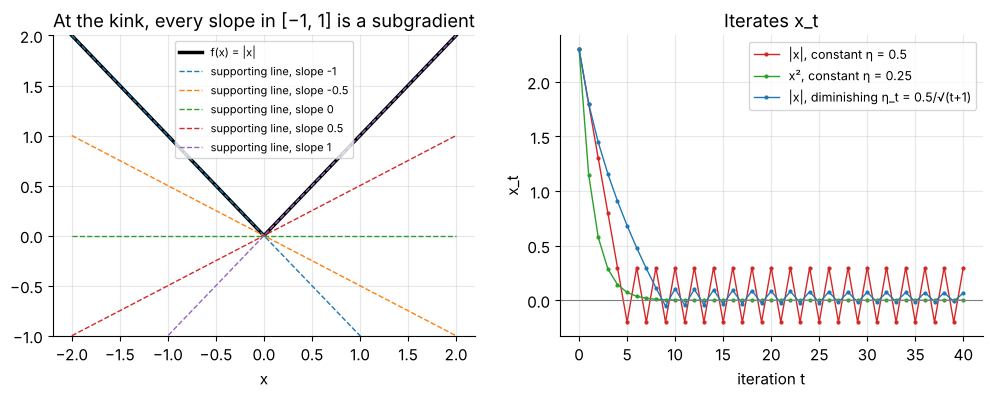

|x|, constant η = 0.5                last three iterates: [ 0.3 -0.2  0.3]
x², constant η = 0.25                last three iterates: [0. 0. 0.]
|x|, diminishing η_t = 0.5/√(t+1)    last three iterates: [ 0.0689 -0.0111  0.0679]


In [55]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.9))
xx = np.linspace(-2, 2, 200)
axes[0].plot(xx, np.abs(xx), lw=2.5, color="k", label="f(x) = |x|")
for g_sub in [-1, -0.5, 0, 0.5, 1]:
    axes[0].plot(xx, g_sub * xx, lw=1, ls="--", label=f"supporting line, slope {g_sub}")
axes[0].set(title="At the kink, every slope in [−1, 1] is a subgradient", xlabel="x", ylim=(-1, 2))
axes[0].legend(fontsize=8, loc="upper center")

n_show = 40
runs_kink = {
    "|x|, constant η = 0.5": gd_path_1d(np.sign, 2.3, 0.5, n_show),
    "x², constant η = 0.25": gd_path_1d(lambda x: 2 * x, 2.3, 0.25, n_show),
}
x, path_dim = 2.3, [2.3]
for t in range(n_show):
    x = x - 0.5 / np.sqrt(t + 1) * np.sign(x)
    path_dim.append(x)
runs_kink["|x|, diminishing η_t = 0.5/√(t+1)"] = np.array(path_dim)
for (name, path), col in zip(runs_kink.items(), ["C3", "C2", "C0"]):
    axes[1].plot(path, ".-", ms=4, lw=1, color=col, label=name)
axes[1].axhline(0, color="gray", lw=0.8)
axes[1].set(title="Iterates x_t", xlabel="iteration t", ylabel="x_t")
axes[1].legend(fontsize=9)
plt.show()
for name, path in runs_kink.items():
    print(f"{name:36s} last three iterates: {np.round(path[-3:], 4)}")

The constant-step run is stuck in the 2-cycle $0.3 \leftrightarrow -0.2$, while the diminishing-step run creeps in
(slowly: its error decays roughly like $1/\sqrt t$, much slower than the geometric decay on smooth bowls), and
GD on the smooth $x^2$ is already at $0$ to many digits.

What do the libraries do at a kink? They simply pick one subgradient:

In [56]:
xk = torch.tensor([-1.0, 0.0, 2.0], requires_grad=True)
torch.abs(xk).sum().backward()
print("PyTorch d|x|/dx  at x = -1, 0, 2:", xk.grad.tolist())
xk.grad = None
torch.relu(xk).sum().backward()
print("PyTorch dReLU/dx at x = -1, 0, 2:", xk.grad.tolist())

PyTorch d|x|/dx  at x = -1, 0, 2: [-1.0, 0.0, 1.0]
PyTorch dReLU/dx at x = -1, 0, 2: [0.0, 0.0, 1.0]


Both conventions choose 0 at the corner, a perfectly valid subgradient. Because a kink is a single point,
hitting it *exactly* is rare, and in practice ReLU networks and MAE losses train fine. When you want both
robustness to outliers (like the MAE) and smooth convergence (like the MSE), use a smooth approximation such as the
**Huber loss** (quadratic for small residuals, linear for large ones) or the "pseudo-absolute value"
$\sqrt{r^2 + \delta^2} - \delta$ with a small $\delta > 0$.

### 8.2 Vertical tangents and cusps

In Section 2.7 we saw that $\sqrt[3]{x}$ has a vertical tangent at 0: its slope $\frac13 x^{-2/3}$ blows up there. As a
loss it would be useless anyway (it has no minimum, as it decreases forever as $x \to -\infty$), but a close relative
shows the real danger. The **cusp** $f(x) = |x|^{2/3} = \big(\sqrt[3]{x}\big)^2$ *does* have its minimum at 0, yet

$$
f'(x) = \tfrac23\,\operatorname{sign}(x)\,|x|^{-1/3} \longrightarrow \pm\infty \quad\text{as } x \to 0 .
$$

The slope is *largest* right next to the minimum, the exact opposite of what GD needs. The closer GD gets, the
harder it is kicked away:

eta = 0.1  : |x_t| over the last 200 steps ranges from 2.0e-03 to 0.53; f(x_300) = 0.096
eta = 0.01 : |x_t| over the last 200 steps ranges from 7.8e-06 to 0.34; f(x_300) = 0.047


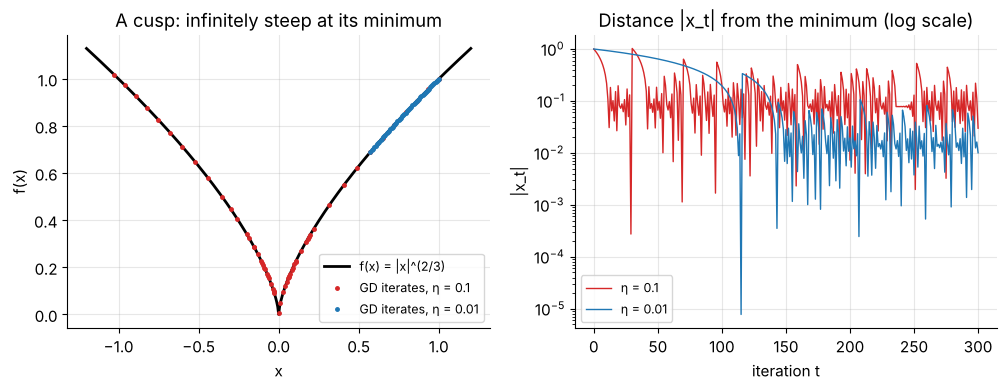

In [57]:
def d_cusp(x):
    """Derivative of |x|^(2/3), using 0 at the cusp itself."""
    return 0.0 if x == 0 else (2 / 3) * np.sign(x) * abs(x) ** (-1 / 3)


fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
xx = np.linspace(-1.2, 1.2, 401)
axes[0].plot(xx, np.abs(xx) ** (2 / 3), color="k", lw=2, label="f(x) = |x|^(2/3)")
for eta, col in [(0.1, "C3"), (0.01, "C0")]:
    path = gd_path_1d(d_cusp, 1.0, eta, 300)
    axes[1].semilogy(np.abs(path), color=col, lw=1, label=f"η = {eta}")
    print(f"eta = {eta:<5}: |x_t| over the last 200 steps ranges from {np.abs(path[100:]).min():.1e} "
          f"to {np.abs(path[100:]).max():.2f}, f(x_300) = {abs(path[-1]) ** (2 / 3):.3f}")
    axes[0].plot(path[:60], np.abs(path[:60]) ** (2 / 3), ".", color=col, ms=5, label=f"GD iterates, η = {eta}")
axes[0].set(title="A cusp: infinitely steep at its minimum", xlabel="x", ylabel="f(x)")
axes[0].legend(fontsize=9)
axes[1].set(title="Distance |x_t| from the minimum (log scale)", xlabel="iteration t", ylabel="|x_t|")
axes[1].legend(fontsize=9)
plt.show()

With either learning rate GD approaches the minimum, gets violently thrown back out, and keeps doing so forever.
A smaller $\eta$ only shrinks the region it rattles around in. Compare $x^2$, where we proved geometric convergence.
**Good losses have slopes that fade to zero at the minimum**, and that is one more reason the squared error is the default.

### 8.3 Jumps and flat steps

**(a) A cliff the derivative cannot see.** Let $f(x) = (x - 1)^2 + \mathbb 1[x \ge 0.5]$, where the indicator
$\mathbb 1[\cdot]$ adds a penalty of 1 for $x \ge 0.5$. Just left of the jump $f$ is about $0.25$, its lowest values, and
to the right of the jump the best value is $f(1) = 1$. The derivative, wherever it exists, is just $2(x - 1)$, and the
jump leaves no trace in it. GD from $x_0 = -1$ with $\eta = 0.1$ follows that derivative, steps over the cliff
without noticing, and settles at $x = 1$:

In [58]:
f_jump = lambda x: (x - 1) ** 2 + (x >= 0.5) * 1.0
df_jump = lambda x: 2 * (x - 1)                    # derivative everywhere except at the jump
path_jump = gd_path_1d(df_jump, -1.0, 0.1, 60)
print(f"GD ends at x = {path_jump[-1]:.4f} with f = {f_jump(path_jump[-1]):.4f},  "
      f"but f(0.4999) = {f_jump(0.4999):.4f}")

GD ends at x = 1.0000 with f = 1.0000;  but f(0.4999) = 0.2501


**(b) Flat steps: zero gradient almost everywhere.** Twelve students report hours studied and whether they passed.
A threshold rule predicts "pass" when hours $> t$. The natural loss, the **fraction of students misclassified**
(the *0–1 loss*), is a **staircase** in $t$: it only changes when $t$ crosses a data point. Between data points its
derivative is exactly 0, so GD has no signal and never moves, while at a data point the derivative does not exist.

The standard cure is a **smooth surrogate loss**: replace the hard rule by a soft one,
$p_i = \sigma\big(s(x_i - t)\big)$ (a "probability of passing" that rises smoothly from 0 to 1 around $t$, with a fixed
steepness $s = 2$), and minimize the squared error $L(t) = \frac1m\sum_i (p_i - y_i)^2$, which is differentiable.

0-1 loss at t0 = 1.2: 0.3333; central difference with h = 1e-3: 0.0


GD on the smooth surrogate: t goes from 1.2 to 3.2500; 0-1 loss there = 0.1667 (= 2 mistakes out of 12)


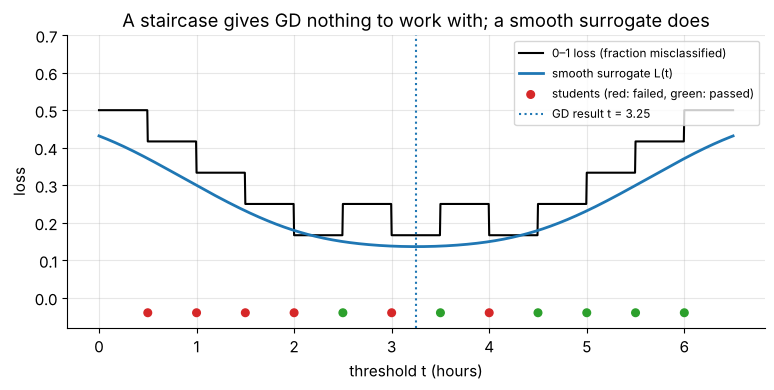

In [59]:
hours = np.array([0.5, 1.0, 1.5, 2.0, 2.5, 3.0, 3.5, 4.0, 4.5, 5.0, 5.5, 6.0])
passed = np.array([0, 0, 0, 0, 1, 0, 1, 0, 1, 1, 1, 1])
s_soft = 2.0


def zero_one_loss(t):
    return np.mean((hours > t).astype(int) != passed)


def surrogate_loss(t):
    return np.mean((sigmoid(s_soft * (hours - t)) - passed) ** 2)


def surrogate_grad(t):
    p = sigmoid(s_soft * (hours - t))
    return np.mean(2 * (p - passed) * p * (1 - p) * (-s_soft))     # chain rule: d p / d t = -s p (1 - p)


t0 = 1.2
print(f"0-1 loss at t0 = {t0}: {zero_one_loss(t0):.4f}, central difference with h = 1e-3: "
      f"{(zero_one_loss(t0 + 1e-3) - zero_one_loss(t0 - 1e-3)) / 2e-3}")
path_t = gd_path_1d(surrogate_grad, t0, 0.5, 2000)
print(f"GD on the smooth surrogate: t goes from {t0} to {path_t[-1]:.4f}, "
      f"0-1 loss there = {zero_one_loss(path_t[-1]):.4f} (= 2 mistakes out of 12)")

ts = np.linspace(0, 6.5, 1301)
fig, ax = plt.subplots(figsize=(9, 3.8))
ax.plot(ts, [zero_one_loss(t) for t in ts], color="k", lw=1.5, label="0–1 loss (fraction misclassified)")
ax.plot(ts, [surrogate_loss(t) for t in ts], color="C0", lw=2, label="smooth surrogate L(t)")
ax.scatter(hours, -0.04 + 0 * hours, c=["C3" if p == 0 else "C2" for p in passed], s=30, zorder=3,
           label="students (red: failed, green: passed)")
ax.axvline(path_t[-1], color="C0", ls=":", label=f"GD result t = {path_t[-1]:.2f}")
ax.set(title="A staircase gives GD nothing to work with, while a smooth surrogate does", xlabel="threshold t (hours)",
       ylabel="loss", ylim=(-0.08, 0.7))
ax.legend(fontsize=8.5, loc="upper right")
plt.show()

The derivative of the staircase at $t_0 = 1.2$ is exactly 0, so GD would stay at $t_0$ forever, misclassifying
a third of the students. The surrogate slopes gently towards good thresholds, and GD on it lands at $t \approx 3.25$,
which makes only 2 mistakes out of 12, as few as any threshold can make on this data.
(Careful with numerical derivatives here: a step $h$ that straddles a data point "sees" a jump and reports an
enormous slope.)

> **Key idea.** Train with a loss that is smooth and informative, and *report* whatever metric you care about.
> Classifiers are scored by accuracy but trained with smooth losses such as squared error on probabilities or,
> more commonly, **cross-entropy** (a later notebook). The same logic explains why the MSE, not the number of
> "big misses", is used to fit lines.

### 8.4 Non-convex landscapes: several valleys

Back to $f(x) = x^4 - 4x^2 + x$ from Section 4.2, with a global minimum at $x \approx -1.473$, a worse local minimum at
$x \approx 1.347$ and a hump (local maximum) at $x \approx 0.126$. Where does GD end up, as a function of where it starts?

eta = 0.01: the destination switches at x0 ≈ [0.13]


eta = 0.1: the destination switches at x0 ≈ [-2.18  0.13  2.06]


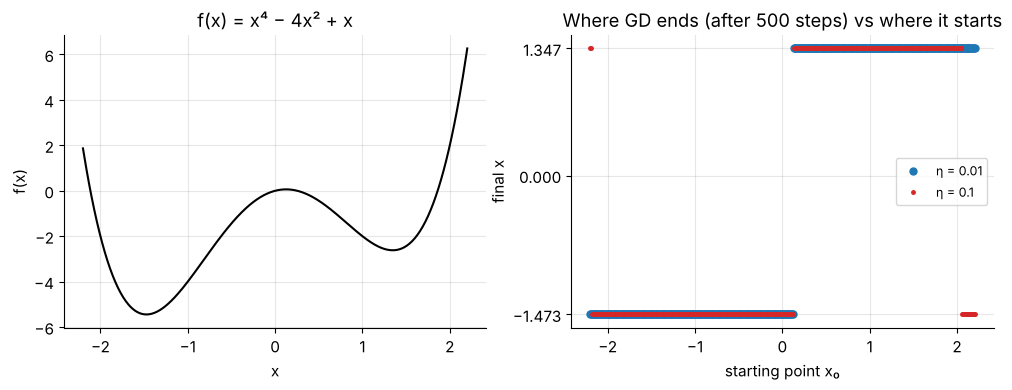

In [60]:
x0_grid = np.linspace(-2.2, 2.2, 441)
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
axes[0].plot(x0_grid, f_w(x0_grid), color="k")
axes[0].set(title="f(x) = x⁴ − 4x² + x", xlabel="x", ylabel="f(x)")
for eta, col, ms in [(0.01, "C0", 5), (0.1, "C3", 2.5)]:
    ends = np.array([gd_path_1d(df_w, x0, eta, 500)[-1] for x0 in x0_grid])
    axes[1].plot(x0_grid, ends, "o", ms=ms, color=col, label=f"η = {eta}")
    labels = np.where(ends < 0, -1, 1)
    switches = x0_grid[1:][np.diff(labels) != 0]
    print(f"eta = {eta}: the destination switches at x0 ≈ {np.round(switches, 2)}")
axes[1].set(title="Where GD ends (after 500 steps) vs where it starts", xlabel="starting point x₀",
            ylabel="final x", yticks=[-1.473, 0, 1.347])
axes[1].legend(fontsize=9)
plt.show()

With a small step ($\eta = 0.01$) the rule is simple: start left of the hump and you reach the global minimum, but start
right of it and you get stuck in the worse valley. Each valley has a **basin of attraction**. With $\eta = 0.1$, starts
far out on either side, where the slope is huge, overshoot across the hump (like $x_0 = 3$ in Section 7.1), so the
basins get chopped up. Derivatives only see the local slope, so **the answer depends on initialization**.

In two dimensions the picture is richer. **Himmelblau's function**
$f(x, y) = (x^2 + y - 11)^2 + (x + y^2 - 7)^2$ is a classic test landscape with **four** minima (all with $f = 0$):

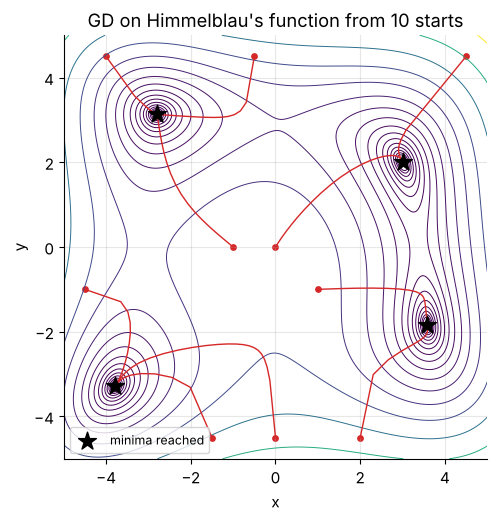

distinct end points: [(-3.779, -3.283), (-2.805, 3.131), (3.0, 2.0), (3.584, -1.848)]


In [61]:
def himmelblau(x, y):
    return (x**2 + y - 11) ** 2 + (x + y**2 - 7) ** 2


def grad_himmelblau(theta):
    x, y = theta
    a_h, b_h = x**2 + y - 11, x + y**2 - 7
    return np.array([4 * x * a_h + 2 * b_h, 2 * a_h + 4 * y * b_h])


starts_h = [(0, 0), (-1, 0), (-4, 4.5), (4.5, 4.5), (0, -4.5), (-4.5, -1), (1, -1), (-1.5, -4.5), (2, -4.5), (-0.5, 4.5)]
Xh, Yh = np.meshgrid(np.linspace(-5, 5, 300), np.linspace(-5, 5, 300))
fig, ax = plt.subplots(figsize=(6.5, 5.5))
ax.contour(Xh, Yh, himmelblau(Xh, Yh), levels=np.geomspace(0.5, 800, 16), cmap="viridis", linewidths=0.7)
ends_h = []
for st in starts_h:
    path, _ = gradient_descent(grad_himmelblau, st, lr=0.005, max_iter=2000, tol=1e-8)
    ends_h.append(tuple(round(float(v), 3) for v in path[-1]))
    ax.plot(path[:, 0], path[:, 1], "-", color="C3", lw=1)
    ax.scatter(*st, color="C3", s=15)
ax.scatter(*np.array(sorted(set(ends_h))).T, marker="*", s=180, color="k", zorder=3, label="minima reached")
ax.set(title="GD on Himmelblau's function from 10 starts", xlabel="x", ylabel="y")
ax.set_aspect("equal")
ax.legend(loc="lower left", fontsize=9)
plt.show()
print("distinct end points:", sorted(set(ends_h)))

Ten starting points, four different answers. Here all four minima happen to be equally good, but in general they
are not, and GD alone cannot tell you whether a better valley exists. Practical defenses:

- **Multiple restarts**: run GD from several random starting points and keep the best result.
- **Sensible initialization** (in deep learning, carefully scaled random initial weights).
- **Noise and momentum** (stochastic gradients, Section 10.8, and momentum, Section 6.8) can carry the iterate over
  small humps.
- **Convex formulations** whenever possible, and here is the good news for this notebook: the MSE of a *linear*
  model is convex (Section 9.5), so linear regression has none of these problems.

> **Going deeper.** Neural-network losses are highly non-convex, yet GD-based training works remarkably well.
> Part of the explanation is that in very high dimensions most critical points are saddles rather than bad local
> minima, and many of the minima that GD finds are about equally good. Understanding this precisely is an active
> research area.

### ✏️ Exercise 8: the best constant under the MAE is the median

If a model must predict the **same** number $c$ for everyone, the MAE is $g(c) = \frac1m\sum_i |y_i - c|$, a convex
function with kinks at the data points. Its subgradient (using $\operatorname{sign}(0) = 0$) is

$$
g'(c) = \frac1m\sum_{i=1}^m \operatorname{sign}(c - y_i) = \frac{\#\{y_i < c\} - \#\{y_i > c\}}{m}.
$$

1. Implement `mae_subgradient(c, y)`.
2. Implement `subgradient_descent_constant(y, c0, n_steps, eta0)`: start at `c0` and take `n_steps` steps
   $c \leftarrow c - \eta_t\, g'(c)$ with diminishing steps $\eta_t = \eta_0/\sqrt{t + 1}$, $t = 0, 1, \dots$, and return the final $c$.

The checker verifies that your method finds the **median** (for an even number of points, any value between the
two middle ones minimizes $g$).

In [62]:
# ✏️ Exercise 8: the best constant under the MAE is the median
def mae_subgradient(c, y):
    """Subgradient of g(c) = mean(|y_i - c|) at c, using sign(0) = 0."""
    # YOUR CODE HERE
    raise NotImplementedError


def subgradient_descent_constant(y, c0, n_steps=2000, eta0=1.0):
    """Minimize mean(|y - c|) over c with steps eta0 / sqrt(t + 1), and return the final c."""
    # YOUR CODE HERE
    raise NotImplementedError


def _test():
    y = np.array([12.0, 15.0, 16.0, 19.0, 22.0, 31.0, 58.0])   # delivery times in minutes, one very late
    assert np.isclose(mae_subgradient(10.0, y), -1.0), "below every data point the subgradient is -1"
    assert np.isclose(mae_subgradient(60.0, y), 1.0), "above every data point it is +1"
    assert np.isclose(mae_subgradient(17.0, y), -1 / 7), "at c = 17: 3 points below, 4 above -> (3 - 4)/7"
    assert np.isclose(mae_subgradient(19.0, y), 0.0), "at the median the subgradient (with sign(0) = 0) is 0"
    c = subgradient_descent_constant(y, c0=40.0)
    assert abs(c - 19.0) < 0.1, f"should end near the median 19, got {c:.4f}"
    c = subgradient_descent_constant(np.array([1.0, 2.0, 3.0, 10.0]), c0=-5.0)
    assert 1.9 <= c <= 3.1, f"for [1, 2, 3, 10] any c in [2, 3] is optimal, got {c:.4f}"

run_check("Exercise 8", _test)

⏳ Exercise 8: not implemented yet; fill in the function and re-run this cell.


<details>
<summary><b>Solution</b> (try first!)</summary>

```python
def mae_subgradient(c, y):
    return np.mean(np.sign(c - y))

def subgradient_descent_constant(y, c0, n_steps=2000, eta0=1.0):
    c = float(c0)
    for t in range(n_steps):
        c = c - eta0 / np.sqrt(t + 1) * mae_subgradient(c, y)
    return c
```
The subgradient counts "points below minus points above", and it is zero (or changes sign) exactly where half the data
lies on each side, which is the definition of the median. Note how robust that answer is: the mean of the delivery
times is about 24.7 minutes, pulled up by the single 58-minute outlier, while the MAE-optimal constant stays at 19.
</details>

## 9. Linear regression as an optimization problem

Everything is now in place to go back to the cafe from Section 1 and *derive* the best line yourself.
This section does the mathematics once, carefully, for any number of features, and Section 10 then applies it
to a realistic dataset.

### 9.1 The model and the loss in general notation

Suppose there are $m$ training examples, each with $d$ numerical features. Example $i$ has a feature vector
$\mathbf{x}_i = (x_{i1}, \dots, x_{id}) \in \mathbb{R}^{d}$ and a target $y_i \in \mathbb{R}$. A **linear
regression** model predicts

$$
\hat y_i = b + w_1 x_{i1} + w_2 x_{i2} + \dots + w_d x_{id} = b + \mathbf{w}^\top \mathbf{x}_i ,
$$

with one weight $w_j$ per feature and one bias $b$: $d + 1$ parameters in total. The training loss is the
mean squared error

$$
J(b, \mathbf{w}) = \frac{1}{m}\sum_{i=1}^{m}\big(\hat y_i - y_i\big)^2 .
$$

A small bookkeeping trick makes everything cleaner. Put a constant feature $x_{i0} = 1$ in front of every
example and call the bias $\theta_0$, and call the weights $\theta_1, \dots, \theta_d$. Stack the examples as rows
of the **design matrix** $X$ and the targets into a vector $\mathbf{y}$:

$$
X = \begin{pmatrix} 1 & x_{11} & \cdots & x_{1d} \\ 1 & x_{21} & \cdots & x_{2d} \\ \vdots & \vdots & & \vdots \\ 1 & x_{m1} & \cdots & x_{md} \end{pmatrix}
\in \mathbb{R}^{m \times (d+1)}, \qquad
\boldsymbol\theta = \begin{pmatrix} \theta_0 \\ \theta_1 \\ \vdots \\ \theta_d \end{pmatrix} \in \mathbb{R}^{d+1}, \qquad
\mathbf{y} \in \mathbb{R}^{m}.
$$

Then all $m$ predictions are one matrix–vector product, $\hat{\mathbf y} = X\boldsymbol\theta \in \mathbb{R}^{m}$,
and the loss is the squared length of the residual vector divided by $m$:

$$
J(\boldsymbol\theta) = \frac{1}{m}\,\lVert X\boldsymbol\theta - \mathbf{y} \rVert^2 = \frac{1}{m}\,(X\boldsymbol\theta - \mathbf{y})^\top (X\boldsymbol\theta - \mathbf{y}).
$$

Throughout this section $\mathbf{e} = X\boldsymbol\theta - \mathbf{y}$ ("prediction minus target") denotes the
**error vector**, and it is the negative of the residual $r_i = y_i - \hat y_i$ from Section 1. Using
prediction-minus-target removes a minus sign from every gradient formula below.

### 9.2 Gradients by hand: one feature

Start with $d = 1$, the cafe's case: $J(w, b) = \frac{1}{m}\sum_i (w x_i + b - y_i)^2$. Each term is a square
of an inner function $e_i(w, b) = w x_i + b - y_i$, so the chain rule (Section 2.5) gives
$\frac{\partial}{\partial w} e_i^2 = 2e_i \cdot \frac{\partial e_i}{\partial w} = 2 e_i x_i$ and
$\frac{\partial}{\partial b} e_i^2 = 2 e_i \cdot 1$. Averaging over the examples:

$$
\frac{\partial J}{\partial w} = \frac{2}{m}\sum_{i=1}^{m} e_i\, x_i , \qquad
\frac{\partial J}{\partial b} = \frac{2}{m}\sum_{i=1}^{m} e_i , \qquad e_i = w x_i + b - y_i .
$$

Read them like a story. $\partial J/\partial b$ is twice the **average error**: if the line predicts too high on
average, the gradient is positive and gradient descent lowers $b$. $\partial J/\partial w$ weighs each error by
its $x_i$: errors on points with large $x$ have more leverage on the slope.

**Worked example.** Four points $x = (1, 2, 3, 4)$, $y = (3, 5, 6, 9)$, starting from $w = b = 0$ with $\eta = 0.05$.

| $i$ | $x_i$ | $y_i$ | $\hat y_i = 0$ | $e_i = \hat y_i - y_i$ | $e_i^2$ | $e_i x_i$ |
|---|---|---|---|---|---|---|
| 1 | 1 | 3 | 0 | $-3$ | 9 | $-3$ |
| 2 | 2 | 5 | 0 | $-5$ | 25 | $-10$ |
| 3 | 3 | 6 | 0 | $-6$ | 36 | $-18$ |
| 4 | 4 | 9 | 0 | $-9$ | 81 | $-36$ |
| **sum** | | | | $-23$ | 151 | $-67$ |

So $J = 151/4 = 37.75$, $\;\partial J/\partial w = \tfrac{2}{4}(-67) = -33.5$, $\;\partial J/\partial b = \tfrac{2}{4}(-23) = -11.5$.
Both partial derivatives are negative ("increasing the parameter lowers the loss"), so both parameters go **up**:

$$
w_1 = 0 - 0.05\cdot(-33.5) = 1.675, \qquad b_1 = 0 - 0.05\cdot(-11.5) = 0.575 .
$$

The new predictions $1.675x + 0.575$ are $(2.25,\ 3.925,\ 5.6,\ 7.275)$, with errors $(-0.75, -1.075, -0.4, -1.725)$
and $J = 4.85375/4 \approx 1.2134$: one step cut the loss by a factor of about 31. The code below repeats the step
and checks the hand-derived gradient against the numerical gradient from Section 3.4.

In [63]:
x_toy = np.array([1.0, 2.0, 3.0, 4.0])
y_toy = np.array([3.0, 5.0, 6.0, 9.0])


def mse_wb(w, b, x, y):
    """Mean squared error of the line w*x + b."""
    return np.mean((w * x + b - y) ** 2)


def grad_mse_wb(w, b, x, y):
    """Hand-derived gradient (dJ/dw, dJ/db) of the MSE for one feature."""
    e = w * x + b - y                       # errors: prediction minus target, shape (m,)
    return np.array([2 * np.mean(e * x), 2 * np.mean(e)])


w0, b0, eta = 0.0, 0.0, 0.05
g0 = grad_mse_wb(w0, b0, x_toy, y_toy)
g0_num = numerical_gradient(lambda p: mse_wb(p[0], p[1], x_toy, y_toy), np.array([w0, b0]))
w1, b1 = np.array([w0, b0]) - eta * g0
print(f"J(0, 0) = {mse_wb(w0, b0, x_toy, y_toy):.4f}")
print(f"hand gradient      = {g0}   numerical gradient = {np.round(g0_num, 6)}")
print(f"after one step: w = {w1:.4f}, b = {b1:.4f}, J = {mse_wb(w1, b1, x_toy, y_toy):.4f}")

J(0, 0) = 37.7500
hand gradient      = [-33.5 -11.5]   numerical gradient = [-33.5 -11.5]
after one step: w = 1.6750, b = 0.5750, J = 1.2134


### 9.3 The vector form: $\nabla J = \frac{2}{m} X^\top (X\boldsymbol\theta - \mathbf{y})$

With $d$ features the same chain-rule argument works for every parameter at once. Write the error of example $i$
as $e_i = \sum_{k=0}^{d} X_{ik}\theta_k - y_i$. Since $\partial e_i / \partial \theta_j = X_{ij}$ (the $j$-th feature of
example $i$, and $X_{i0} = 1$ for the bias),

$$
\frac{\partial J}{\partial \theta_j} = \frac{1}{m}\sum_{i=1}^{m} 2 e_i \frac{\partial e_i}{\partial \theta_j}
= \frac{2}{m}\sum_{i=1}^{m} X_{ij}\, e_i = \frac{2}{m}\big(X^\top \mathbf{e}\big)_j .
$$

The sum over $i$ of "column $j$ of $X$ times $\mathbf{e}$" is exactly entry $j$ of $X^\top\mathbf{e}$. Stacking all
$j = 0, \dots, d$:

$$
\boxed{\;\nabla_{\boldsymbol\theta} J(\boldsymbol\theta) = \frac{2}{m}\,X^\top\big(X\boldsymbol\theta - \mathbf{y}\big)\;}
$$

**Shape check** (do this every time you write a vectorized formula): $X\boldsymbol\theta$ is $(m\times(d+1))\cdot(d+1) = m$,
minus $\mathbf{y}$ is still $m$, and $X^\top$ is $(d+1)\times m$, so $X^\top\mathbf{e}$ has $d+1$ entries, one per parameter.
For $d = 1$ the two entries are exactly $\frac{2}{m}\sum_i e_i$ and $\frac{2}{m}\sum_i e_i x_i$ from Section 9.2.

One gradient evaluation costs two matrix–vector products, about $2m(d+1)$ multiplications. That is all
gradient descent needs per step.

> **Common pitfall.** Forgetting the column of ones. Without it the model is forced through the origin
> ($\hat y = 0$ when all features are 0), and nothing in the gradient code will complain, but the fit is simply worse.

In [64]:
def add_ones(X_feat):
    """Prepend a column of ones (for the bias) to an (m, d) feature matrix -> (m, d + 1)."""
    X_feat = np.asarray(X_feat, dtype=float).reshape(len(X_feat), -1)
    return np.column_stack([np.ones(len(X_feat)), X_feat])


def mse(theta, X, y):
    """J(theta) = mean squared error of the linear model X @ theta (X already contains the ones column)."""
    e = X @ theta - y
    return e @ e / len(y)


def mse_grad(theta, X, y):
    """Gradient of the MSE: (2/m) X^T (X theta - y), shape (d + 1,)."""
    return 2.0 / len(y) * (X.T @ (X @ theta - y))


# Check on random data with 3 features against the numerical gradient from Section 3.4
X_chk = add_ones(rng.normal(size=(7, 3)))
y_chk = rng.normal(size=7)
theta_chk = rng.normal(size=4)
g_an = mse_grad(theta_chk, X_chk, y_chk)
g_nu = numerical_gradient(lambda t: mse(t, X_chk, y_chk), theta_chk)
print("shapes: X", X_chk.shape, " theta", theta_chk.shape, " gradient", g_an.shape)
print("analytic :", np.round(g_an, 6))
print("numerical:", np.round(g_nu, 6))
print(f"relative error = {relative_error(g_an, g_nu):.2e}")
# The toy example of Section 9.2 in the new notation: theta = (b, w)
print("toy gradient at theta = (0, 0):", mse_grad(np.zeros(2), add_ones(x_toy), y_toy), "(order: d/db, d/dw)")

shapes: X (7, 4)  theta (4,)  gradient (4,)
analytic : [ 0.209324 -1.715881  4.204188  1.874965]
numerical: [ 0.209324 -1.715881  4.204188  1.874965]
relative error = 2.22e-10
toy gradient at theta = (0, 0): [-11.5 -33.5] (order: d/db, d/dw)


### 9.4 Gradient descent on the cafe data, and why it crawls

Time to fit the cafe line with gradient descent, using the `gradient_descent` function from Section 5.5 and the
vector gradient. Section 6.6 taught us to ask *before* running: what learning rates are safe, and how fast can
we expect to go? Because the MSE is a quadratic function of $\boldsymbol\theta$ (Section 9.5 below makes this
precise), the answers come from its **Hessian**, the matrix of second derivatives:

$$
H = \nabla^2 J = \frac{2}{m} X^\top X \qquad \big(\text{differentiate } \tfrac{2}{m}X^\top X\boldsymbol\theta - \tfrac{2}{m}X^\top\mathbf y \text{ once more}\big).
$$

It does not depend on $\boldsymbol\theta$ or on $\mathbf{y}$ at all, only on the features. Section 6.6 showed that on a
quadratic bowl GD converges if and only if $0 < \eta < 2/\lambda_{\max}(H)$, and that the slowest direction
shrinks by the factor $|1 - \eta\lambda_{\min}|$ per step.

In [65]:
X_cafe = add_ones(temp)                       # shape (8, 2): columns [1, temperature]
H_cafe = 2 / len(drinks) * X_cafe.T @ X_cafe
lam_cafe = np.linalg.eigvalsh(H_cafe)         # eigenvalues in increasing order
print("H =\n", H_cafe)
print(f"eigenvalues: {lam_cafe[0]:.5f} and {lam_cafe[1]:.2f}  ->  condition number kappa = {lam_cafe[1] / lam_cafe[0]:,.0f}")
print(f"GD converges only for eta < 2 / lambda_max = {2 / lam_cafe[1]:.6f}")

theta_star_cafe = np.array([b_star, w_star])  # the best line from Section 1.3 (order: b, w)
J_star_cafe = mse(theta_star_cafe, X_cafe, drinks)
eta_cafe = 0.0016
path_cafe, status = gradient_descent(lambda t: mse_grad(t, X_cafe, drinks), [0.0, 0.0], lr=eta_cafe,
                                     max_iter=100_000, tol=0)
for t in [0, 10, 100, 1_000, 10_000, 100_000]:
    b_t, w_t = path_cafe[t]
    print(f"step {t:>7,}: w = {w_t:7.4f}, b = {b_t:8.4f}, J - J* = {mse(path_cafe[t], X_cafe, drinks) - J_star_cafe:10.4f}")
rho_slow = 1 - eta_cafe * lam_cafe[0]
print(f"slow-direction factor per step: {rho_slow:.6f} -> steps per 10^6-fold error reduction: "
      f"{np.log(1e-6) / np.log(rho_slow):,.0f}")

H =
 [[   2.   48.]
 [  48. 1219.]]
eigenvalues: 0.10976 and 1220.89  ->  condition number kappa = 11,124
GD converges only for eta < 2 / lambda_max = 0.001638


step       0: w =  0.0000, b =   0.0000, J - J* =  2378.0317
step      10: w =  0.7482, b =   0.0172, J - J* =   917.7405
step     100: w =  1.9591, b =  -0.0447, J - J* =     2.7624
step   1,000: w =  2.0154, b =  -1.0479, J - J* =     1.8890
step  10,000: w =  2.1987, b =  -5.7037, J - J* =     0.0800
step 100,000: w =  2.2463, b =  -6.9104, J - J* =     0.0000
slow-direction factor per step: 0.999824 -> steps per 10^6-fold error reduction: 78,665


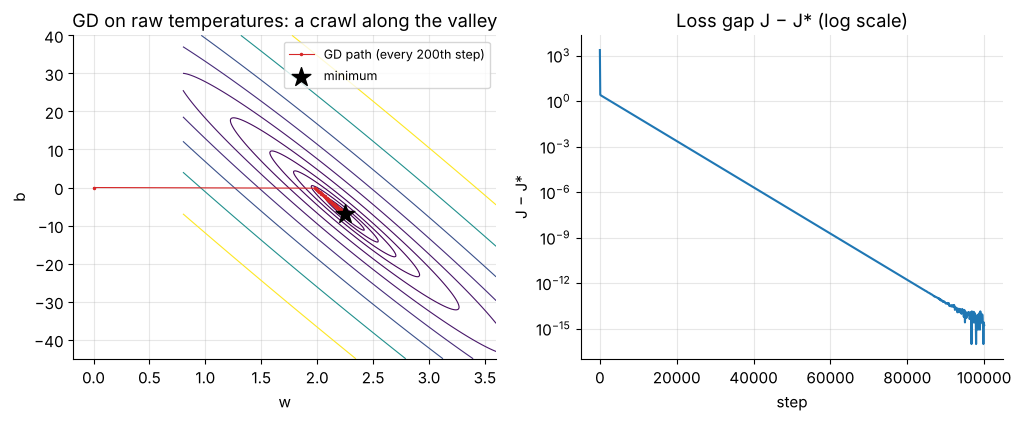

In [66]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
axes[0].contour(W, B, J_grid, levels=levels, cmap="viridis", linewidths=0.8)
axes[0].plot(path_cafe[::200, 1], path_cafe[::200, 0], ".-", color="C3", ms=3, lw=0.8,
             label="GD path (every 200th step)")
axes[0].scatter([w_star], [b_star], marker="*", s=200, color="k", zorder=3, label="minimum")
axes[0].set(title="GD on raw temperatures: a crawl along the valley", xlabel="w", ylabel="b")
axes[0].legend(loc="upper right", fontsize=9)
gaps = np.array([mse(p, X_cafe, drinks) for p in path_cafe[::100]]) - J_star_cafe
axes[1].semilogy(np.arange(len(gaps)) * 100, np.maximum(gaps, 1e-16))
axes[1].set(title="Loss gap J − J* (log scale)", xlabel="step", ylabel="J − J*")
plt.show()

Reading the output:

- The two curvatures of the bowl differ by a factor $\kappa \approx 11{,}000$. The steep direction (mostly "change
  $w$", which moves every prediction by about $24$ times as much as changing $b$ does) caps the learning rate at about
  $0.0016$, and with such a small $\eta$ the flat direction ("pivot the line around the data") shrinks by only
  $0.00018$ (that is, 0.018 %) per step.
- So after 1,000 steps the line has the right *average height* but the wrong tilt ($b \approx -1$ instead of $-6.9$),
  and it takes roughly 79,000 steps to shrink the remaining error a million-fold. The left plot shows the
  iterate dropping quickly onto the valley floor and then creeping along it.
- Nothing is wrong with gradient descent or with the gradient: this is exactly the ill-conditioned bowl of
  Section 6.6, created here by the fact that temperatures sit far from zero. Section 9.7 fixes it with one line of code.

### 9.5 The MSE of a linear model is convex

Why can we trust that the valley has a single floor, with no local minima to get stuck in? Because the Hessian is
**positive semi-definite**: for any direction $\mathbf{v} \in \mathbb{R}^{d+1}$,

$$
\mathbf{v}^\top H \mathbf{v} = \frac{2}{m}\,\mathbf{v}^\top X^\top X \mathbf{v} = \frac{2}{m}\,(X\mathbf{v})^\top (X\mathbf{v}) = \frac{2}{m}\,\lVert X\mathbf{v}\rVert^2 \;\ge\; 0 .
$$

In words: moving the parameters in direction $\mathbf{v}$ changes the predictions by $X\mathbf{v}$, and a squared
length can never be negative, so the loss curves upward (or stays flat) in every direction. A function with a
positive semi-definite Hessian everywhere is convex (Section 4.3 in one variable, and the multivariable version
is the same idea along every line through the parameter space). And because $J$ is a quadratic, Taylor's expansion
around any minimizer $\boldsymbol\theta^*$ is *exact*:

$$
J(\boldsymbol\theta) = J(\boldsymbol\theta^*) + \tfrac{1}{2}(\boldsymbol\theta - \boldsymbol\theta^*)^\top H\,(\boldsymbol\theta - \boldsymbol\theta^*)
= J(\boldsymbol\theta^*) + \tfrac{1}{m}\,\lVert X(\boldsymbol\theta - \boldsymbol\theta^*)\rVert^2 ,
$$

(the linear term vanishes because $\nabla J(\boldsymbol\theta^*) = \mathbf 0$). Two cases:

| Case | When it happens | Shape of the valley | Minimizers |
|---|---|---|---|
| $X\mathbf{v} \neq \mathbf 0$ for every $\mathbf v \ne \mathbf 0$ (columns of $X$ linearly independent) | the usual case: $m \ge d+1$, no feature is an exact combination of others | strictly convex bowl, $\lambda_{\min} > 0$ | exactly one |
| some $\mathbf v \ne \mathbf 0$ has $X\mathbf v = \mathbf 0$ | a duplicated feature, a feature that is a sum of others, fewer examples than parameters | a flat-bottomed trough | infinitely many, all with the same loss |

The second row is the extreme form of **multicollinearity**, and Section 11 studies the realistic, *almost*
collinear version, where the bowl is strictly convex but its floor is nearly flat in one direction.

> **Key idea.** For linear regression with the MSE, every local minimum is a global minimum, gradient descent with
> $0 < \eta < 2/\lambda_{\max}$ converges from any starting point, and the whole Section 6.6 analysis (condition number,
> zig-zags, best learning rate $2/(\lambda_{\min} + \lambda_{\max})$) applies *exactly*, not just approximately.

### 9.6 The closed-form solution: the normal equation

For this particular problem we do not even need to walk: we can solve $\nabla J(\boldsymbol\theta) = \mathbf 0$ directly.

$$
\frac{2}{m}X^\top(X\boldsymbol\theta - \mathbf y) = \mathbf 0
\quad\Longleftrightarrow\quad
\boxed{\;X^\top X\,\boldsymbol\theta = X^\top \mathbf y\;}
$$

This $(d+1)\times(d+1)$ linear system is called the **normal equation** (the error vector at the optimum is
*normal*, i.e. perpendicular, to every column of $X$: $X^\top\mathbf e = \mathbf 0$). When the columns of $X$ are linearly
independent, $X^\top X$ is invertible and $\boldsymbol\theta^* = (X^\top X)^{-1}X^\top\mathbf y$.

For one feature the two equations can be solved by hand. The $b$-equation, $\sum_i e_i = 0$, says the best line
passes through the centroid: $b^* = \bar y - w^*\bar x$. Substituting into the $w$-equation $\sum_i e_i x_i = 0$ gives

$$
w^* = \frac{\sum_i (x_i - \bar x)(y_i - \bar y)}{\sum_i (x_i - \bar x)^2}, \qquad b^* = \bar y - w^*\,\bar x .
$$

The code computes the cafe line three ways: this formula, a linear solver applied to the normal equation, and
`np.linalg.lstsq` (which solves the least-squares problem directly from $X$, without forming $X^\top X$).

> **Olympiad tip.** The two normal equations are worth memorizing as facts about the least-squares line (with an intercept):
> the errors **sum to zero** ($\sum_i e_i = 0$, so the line passes through the centroid $(\bar x, \bar y)$), and they are
> **uncorrelated with the feature** ($\sum_i e_i x_i = 0$). Many contest questions ("which of these lines could be the
> least-squares fit?", "what is the prediction at $x = \bar x$?") are answered by these two lines alone, without computing anything.

In [67]:
xc, yc = temp - temp.mean(), drinks - drinks.mean()
w_formula = (xc @ yc) / (xc @ xc)
b_formula = drinks.mean() - w_formula * temp.mean()
theta_normal = np.linalg.solve(X_cafe.T @ X_cafe, X_cafe.T @ drinks)     # solve, never invert explicitly
theta_lstsq = np.linalg.lstsq(X_cafe, drinks, rcond=None)[0]
print(f"by formula     : w = {w_formula:.5f}, b = {b_formula:.5f}")
print(f"normal equation: w = {theta_normal[1]:.5f}, b = {theta_normal[0]:.5f}")
print(f"lstsq          : w = {theta_lstsq[1]:.5f}, b = {theta_lstsq[0]:.5f}")
print(f"np.polyfit (Section 1.3): w = {w_star:.5f}, b = {b_star:.5f}")
e_opt = X_cafe @ theta_normal - drinks
print("X^T e at the optimum (should be ~0):", np.round(X_cafe.T @ e_opt, 10))
print(f"forecast for 26 °C: {theta_normal[0] + 26 * theta_normal[1]:.1f} drinks")

by formula     : w = 2.24627, b = -6.91045
normal equation: w = 2.24627, b = -6.91045
lstsq          : w = 2.24627, b = -6.91045
np.polyfit (Section 1.3): w = 2.24627, b = -6.91045
X^T e at the optimum (should be ~0): [0. 0.]
forecast for 26 °C: 51.5 drinks


**Normal equation or gradient descent?**

| | Normal equation (`lstsq` / `solve`) | Gradient descent |
|---|---|---|
| Cost | form $X^\top X$: about $m(d+1)^2$, solve: about $(d+1)^3/3$ | about $2m(d+1)$ **per step** |
| Answer | exact (up to rounding), no learning rate to tune | approximate, depends on $\eta$, number of steps, scaling |
| Large $d$ (say $10^5$ features) | $(d+1)^3$ becomes prohibitive | still cheap per step |
| Data too big for memory | awkward | natural: use mini-batches (Section 10.8) |
| Other losses / models (logistic regression, neural nets) | **no closed form exists** | works unchanged |

For a few thousand features or fewer, a direct solver is the right tool for plain linear regression (scikit-learn's
`LinearRegression` uses one). We still study GD on linear regression because it is the cleanest setting in which to
*understand* GD: the answer is known exactly, the loss surface is an exact quadratic, and every phenomenon
(learning-rate limits, ill-conditioning, scaling, stochastic updates) can be measured precisely. Everything carries
over to models that have no normal equation.

> **Common pitfall.** Computing `np.linalg.inv(X.T @ X) @ X.T @ y`. Forming the inverse is slower and less accurate than
> solving the system, and forming $X^\top X$ at all squares the condition number. Prefer `np.linalg.lstsq(X, y)` (or
> `np.linalg.solve` on the normal equation for small, well-conditioned problems).

### 9.7 Feature scaling with z-scores

The cure for the crawl in Section 9.4 is to measure the feature in better units. The **z-score** (standardization)
of a value says how many standard deviations it lies above the mean:

$$
z_i = \frac{x_i - \mu}{\sigma}, \qquad \mu = \frac{1}{m}\sum_{i=1}^{m} x_i, \qquad \sigma = \sqrt{\frac{1}{m}\sum_{i=1}^{m}(x_i - \mu)^2}.
$$

For the cafe, $\mu = 24$ °C and $\sigma \approx 5.79$ °C, so a 33 °C day has $z = 9/5.79 \approx 1.55$ and a 15 °C day has
$z \approx -1.55$. After standardizing, the feature has mean 0 and standard deviation 1, and the Hessian becomes

$$
H = \frac{2}{m}\begin{pmatrix} m & \sum_i z_i \\ \sum_i z_i & \sum_i z_i^2 \end{pmatrix} = \frac{2}{m}\begin{pmatrix} m & 0 \\ 0 & m \end{pmatrix} = \begin{pmatrix} 2 & 0 \\ 0 & 2 \end{pmatrix},
$$

a perfectly round bowl ($\kappa = 1$). With $\eta = 1/2$ gradient descent jumps to the minimum in **one step**,
from any start: the update is $\boldsymbol\theta - \tfrac12 H(\boldsymbol\theta - \boldsymbol\theta^*) = \boldsymbol\theta^*$.

In [68]:
mu_t, sd_t = temp.mean(), temp.std()          # population standard deviation (ddof=0), like scikit-learn
z_temp = (temp - mu_t) / sd_t
X_cafe_z = add_ones(z_temp)
print(f"mu = {mu_t:.4f}, sigma = {sd_t:.4f}")
print("z-scores:", np.round(z_temp, 3), f"| mean {z_temp.mean():.1e}, std {z_temp.std():.4f}")
print("Hessian after scaling:\n", np.round(2 / len(drinks) * X_cafe_z.T @ X_cafe_z, 10))

path_z, status_z = gradient_descent(lambda t: mse_grad(t, X_cafe_z, drinks), [0.0, 0.0], lr=0.5, max_iter=100, tol=1e-10)
b_z, w_z = path_z[1]
print(f"after ONE step: b~ = {b_z:.5f}, w~ = {w_z:.5f}, J = {mse(path_z[1], X_cafe_z, drinks):.5f} "
      f"(J* = {J_star_cafe:.5f}), status: {status_z}")

# Convert back to the original units
w_back = w_z / sd_t
b_back = b_z - w_z * mu_t / sd_t
print(f"back in °C units: w = {w_back:.5f}, b = {b_back:.5f}   (normal equation: w = {w_star:.5f}, b = {b_star:.5f})")

mu = 24.0000, sigma = 5.7879
z-scores: [-1.555 -1.037 -0.691 -0.173  0.173  0.691  1.037  1.555] | mean 0.0e+00, std 1.0000
Hessian after scaling:
 [[2. 0.]
 [0. 2.]]
after ONE step: b~ = 47.00000, w~ = 13.00122, J = 4.96828 (J* = 4.96828); status: converged
back in °C units: w = 2.24627, b = -6.91045   (normal equation: w = 2.24627, b = -6.91045)


**Converting back.** The standardized model predicts $\hat y = \tilde b + \tilde w\, z = \tilde b + \tilde w\,\frac{x - \mu}{\sigma}$.
Multiply out:

$$
\hat y = \underbrace{\Big(\tilde b - \frac{\tilde w\,\mu}{\sigma}\Big)}_{b} + \underbrace{\frac{\tilde w}{\sigma}}_{w}\,x .
$$

With $\tilde w \approx 13.00$ and $\tilde b = 47$: $w = 13.00/5.79 \approx 2.246$ drinks per °C and
$b = 47 - 2.246 \cdot 24 \approx -6.91$, exactly the normal-equation line. Scaling changes the *coordinates* in which GD
walks, not the model it finds.

**Interpreting the two intercepts.** They answer different questions:

- $\tilde b = 47$ is the prediction when $z = 0$, i.e. **on an average day** ($24$ °C). It equals $\bar y$, the mean sales,
  because the best line passes through the centroid. This number is meaningful.
- $b \approx -6.9$ is the prediction at $x = 0$ °C: *negative* drinks. Zero degrees is far outside the observed range
  (15–33 °C), so this is a wild extrapolation, and $b$ merely positions the line and should not be read as a fact about cold days.
- Likewise, $\tilde w \approx 13$ means "one standard deviation warmer (about 5.8 °C) → about 13 more drinks", while
  $w \approx 2.25$ means "1 °C warmer → about 2.25 more drinks". Same line, two units.

> **Common pitfall.** Computing $\mu$ and $\sigma$ on *all* the data (including the test set) before splitting, or
> re-computing them on the test set. The scaler is part of the model: estimate $\mu$ and $\sigma$ on the training data
> only, then apply those same numbers to validation, test and future data (Section 10.5).

> **Going deeper.** Whether you divide by $m$ or $m - 1$ in $\sigma$ does not matter for optimization, as long as you
> use the same $\sigma$ when converting back. NumPy's `std` uses $m$ by default (`ddof=0`), pandas' `std` uses $m-1$
> (`ddof=1`), and scikit-learn's `StandardScaler` uses $m$. Mixing conventions between training and conversion gives
> slightly wrong coefficients.

**Quick check.** A feature has training mean 50 and standard deviation 8. What is the z-score of a test value of 38?
If the standardized model has $\tilde w = 6$ for this feature, how much does the prediction change per original unit?

<details>
<summary>Answer</summary>

$z = (38 - 50)/8 = -1.5$ (one and a half standard deviations below the training mean, and a test value can have any
z-score, it is *not* re-standardized). In original units $w = \tilde w/\sigma = 6/8 = 0.75$ per unit.
</details>

## 10. Practical: multivariate linear regression from scratch

Now a realistic workflow with several features, a train/test split, feature scaling and three flavors of gradient
descent. We use a **synthetic** dataset on purpose: because we generate it ourselves, we know the true coefficients
and the true noise level, so we can check every number the algorithms produce against the truth.

### 10.1 The dataset: household electricity use

Each row is one household and one month. The target is the electricity used, in kWh. The four features are:

| feature | meaning | range | true effect on monthly kWh |
|---|---|---|---|
| `area_m2` | floor area of the home (m²) | 40–220 | $+1.8$ per m² |
| `occupants` | people living there | 1–6 | $+40$ per person |
| `ac_hours` | average daily air-conditioning use (hours) | 0–12 | $+22$ per daily hour |
| `solar_kw` | rooftop solar capacity (kW), 0 for homes without panels (about 60 %) | 0 or 1.5–5 | $-35$ per kW |

plus a baseline of 80 kWh (fridge, router, standby devices) and random noise with standard deviation 35 kWh (weather,
habits, things no feature captures):

$$
\text{kWh} = 80 + 1.8\,\text{area} + 40\,\text{occupants} + 22\,\text{ac\_hours} - 35\,\text{solar\_kw} + \varepsilon,
\qquad \varepsilon \sim \mathcal N(0, 35^2).
$$

The model is told none of this, and it only sees the 240 rows.

In [69]:
TRUE_B = 80.0
TRUE_W = np.array([1.8, 40.0, 22.0, -35.0])
FEATURES = ["area_m2", "occupants", "ac_hours", "solar_kw"]

gen = np.random.default_rng(SEED)                      # a dedicated generator, so this section is reproducible
m_all = 240
area = gen.uniform(40, 220, m_all)
occupants = gen.integers(1, 7, m_all).astype(float)    # integers 1..6
ac_hours = gen.uniform(0, 12, m_all)
has_solar = gen.random(m_all) < 0.4
solar_kw = np.where(has_solar, gen.uniform(1.5, 5.0, m_all), 0.0)
noise = gen.normal(0, 35, m_all)

X_all = np.column_stack([area, occupants, ac_hours, solar_kw])     # shape (240, 4)
y_all = TRUE_B + X_all @ TRUE_W + noise                            # shape (240,)
homes = pd.DataFrame(X_all, columns=FEATURES).assign(kwh=y_all)
display(homes.head().round(2))
display(homes.describe().loc[["mean", "std", "min", "max"]].round(2))

,area_m2,occupants,ac_hours,solar_kw,kwh
0,179.31,2.0,11.17,0.0,698.54
1,119.00,5.0,1.44,0.0,506.99
2,194.55,2.0,1.41,0.0,560.09
3,165.53,5.0,1.05,0.0,567.66
4,56.95,3.0,7.89,0.0,491.50


,area_m2,occupants,ac_hours,solar_kw,kwh
mean,128.76,3.61,5.99,1.37,540.20
std,51.70,1.71,3.50,1.77,150.68
min,41.33,1.00,0.07,0.00,149.96
max,218.63,6.00,11.99,4.98,928.43


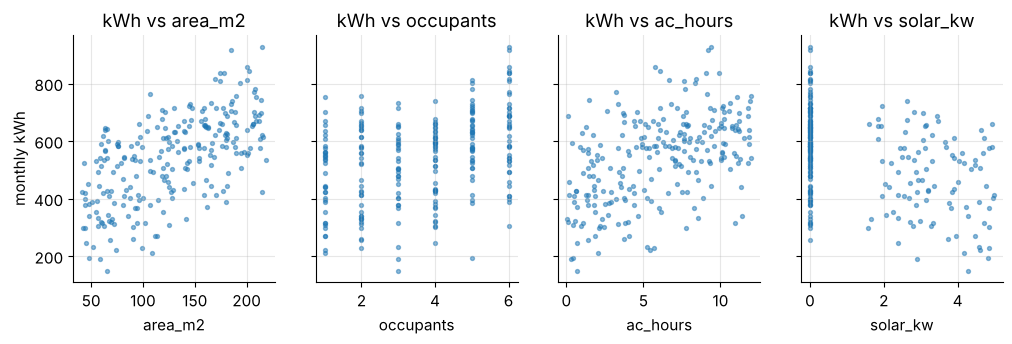

In [70]:
fig, axes = plt.subplots(1, 4, figsize=(12, 3.2), sharey=True)
for ax, name in zip(axes, FEATURES):
    ax.scatter(homes[name], homes["kwh"], s=8, alpha=0.5)
    ax.set(xlabel=name, title=f"kWh vs {name}")
axes[0].set_ylabel("monthly kWh")
plt.show()

Each panel shows a trend buried in scatter: no single feature explains the target, because the other three vary
at the same time. Linear regression untangles them by fitting all four slopes *jointly*.

### 10.2 A train/test split

We hold out a quarter of the homes as a **test set** that the fitting procedure never sees (not even for the
scaling statistics), so we can later measure how well the model predicts *new* homes.

In [71]:
perm = gen.permutation(m_all)
idx_train, idx_test = perm[:180], perm[180:]
X_train, X_test = X_all[idx_train], X_all[idx_test]
y_train, y_test = y_all[idx_train], y_all[idx_test]
print("train:", X_train.shape, y_train.shape, "| test:", X_test.shape, y_test.shape)

train: (180, 4) (180,) | test: (60, 4) (60,)


### 10.3 The reference answer from the normal equation

Before running any gradient descent, compute the exact minimizer of the training MSE (Section 9.6). Every
GD variant below will be judged by how close it gets to these numbers.

In [72]:
A_train = add_ones(X_train)                                 # (180, 5): [1, area, occupants, ac_hours, solar_kw]
theta_ref = np.linalg.lstsq(A_train, y_train, rcond=None)[0]
J_ref = mse(theta_ref, A_train, y_train)
param_names = ["intercept"] + FEATURES
display(pd.DataFrame({"true": np.r_[TRUE_B, TRUE_W], "least squares": theta_ref}, index=param_names).round(3))
print(f"training MSE at the optimum J* = {J_ref:.2f}  (RMSE = {np.sqrt(J_ref):.2f} kWh, noise sd was 35)")

,true,least squares
intercept,80.0,92.435
area_m2,1.8,1.832
occupants,40.0,37.340
ac_hours,22.0,20.765
solar_kw,-35.0,-34.227


training MSE at the optimum J* = 1150.52  (RMSE = 33.92 kWh; noise sd was 35)


The estimates are close to the truth but not equal to it: with only 180 noisy homes, the data cannot pin the
coefficients down exactly. The intercept is the least precise (about 92 instead of 80) because it is an
extrapolation to a home with 0 m², 0 occupants and no air-conditioning, far from any observed home. Notice also that
the training RMSE is slightly *below* the true noise level 35: the fit adapts a little to the particular noise in
these 180 rows (a first glimpse of overfitting).

### 10.4 Gradient descent on the raw features: a crawl

The features live on very different scales: area in the hundreds, occupants between 1 and 6. Section 9.4 predicts
trouble, and the Hessian $H = \frac{2}{m}X^\top X$ quantifies it.

In [73]:
H_raw = 2 / len(y_train) * A_train.T @ A_train
lam_raw = np.linalg.eigvalsh(H_raw)
eta_raw = 1 / lam_raw[-1]                                   # half of the divergence limit 2 / lambda_max
print("eigenvalues of H:", ", ".join(f"{v:,.4g}" for v in lam_raw))
print(f"kappa = {lam_raw[-1] / lam_raw[0]:,.0f},  stable only for eta < {2 / lam_raw[-1]:.3e},  using eta = {eta_raw:.3e}")

path_raw, _ = gradient_descent(lambda t: mse_grad(t, A_train, y_train), np.zeros(5), lr=eta_raw,
                               max_iter=20_000, tol=0)
for t in [1_000, 20_000]:
    print(f"after {t:>6,} steps: J - J* = {mse(path_raw[t], A_train, y_train) - J_ref:9.2f},  theta = {np.round(path_raw[t], 2)}")
rho_raw = 1 - eta_raw * lam_raw[0]
print(f"slowest direction shrinks by {rho_raw:.7f} per step -> about {np.log(1e-6) / np.log(rho_raw):,.0f} steps "
      "for a 10^6-fold reduction")

eigenvalues of H: 0.1158, 6.03, 9.113, 32.62, 4.084e+04
kappa = 352,544;  stable only for eta < 4.897e-05;  using eta = 2.449e-05


after  1,000 steps: J - J* =   9942.10,  theta = [ 1.52  2.99  9.94 15.48 -3.48]
after 20,000 steps: J - J* =    427.68,  theta = [  8.51   2.08  43.28  23.77 -29.75]
slowest direction shrinks by 0.9999972 per step -> about 4,870,573 steps for a 10^6-fold reduction


A condition number of about 350,000 is catastrophic: the learning rate is capped by the steep "area" direction
(area values are large, so its column dominates $X^\top X$), while the flat directions (mainly the intercept, which
has to travel from 0 to about 92) barely move. After 20,000 steps the intercept is still below 10 and the loss is
hundreds of units above the optimum, and finishing the job would take millions of steps.

### 10.5 Z-score scaling with *training* statistics

Standardize every feature column $j$ with the mean $\mu_j$ and standard deviation $\sigma_j$ **of the training rows**,
and apply exactly the same $\mu_j, \sigma_j$ to the test rows:

$$
z_{ij} = \frac{x_{ij} - \mu_j}{\sigma_j}, \qquad \mu_j = \frac{1}{m}\sum_{i \in \text{train}} x_{ij}, \qquad
\sigma_j = \sqrt{\frac{1}{m}\sum_{i \in \text{train}} (x_{ij} - \mu_j)^2 } .
$$

Why training statistics only? The test set stands in for future data that you do not have yet. If $\mu$ and
$\sigma$ were computed with the test rows included, information about the test set would leak into the model, and
the test score would be slightly optimistic. (With 60 test homes the effect is small, but with tiny datasets or
time-ordered data it can be large.)

In [74]:
mu_tr = X_train.mean(axis=0)
sd_tr = X_train.std(axis=0)                      # ddof=0
Z_train = (X_train - mu_tr) / sd_tr
Z_test = (X_test - mu_tr) / sd_tr                # the TRAINING mu and sigma, applied to the test rows
display(pd.DataFrame({"mu": mu_tr, "sigma": sd_tr,
                      "train z mean": Z_train.mean(axis=0), "train z std": Z_train.std(axis=0),
                      "test z mean": Z_test.mean(axis=0), "test z std": Z_test.std(axis=0)},
                     index=FEATURES).round(3))

Az_train = add_ones(Z_train)
H_z = 2 / len(y_train) * Az_train.T @ Az_train
lam_z = np.linalg.eigvalsh(H_z)
print("eigenvalues of H after scaling:", np.round(lam_z, 4))
print(f"kappa = {lam_z[-1] / lam_z[0]:.3f},  stable for eta < {2 / lam_z[-1]:.4f},  "
      f"best constant eta = 2/(lam_min + lam_max) = {2 / (lam_z[0] + lam_z[-1]):.4f}")

,mu,sigma,train z mean,train z std,test z mean,test z std
area_m2,133.459,50.642,0.0,1.0,-0.372,1.024
occupants,3.633,1.716,0.0,1.0,-0.049,0.966
ac_hours,5.884,3.443,-0.0,1.0,0.120,1.048
solar_kw,1.426,1.746,0.0,1.0,-0.123,1.039


eigenvalues of H after scaling: [1.6843 1.8794 2.     2.1438 2.2925]
kappa = 1.361;  stable for eta < 0.8724;  best constant eta = 2/(lam_min + lam_max) = 0.5029


The training columns now have mean 0 and standard deviation 1 exactly. The test columns do not (the test homes
happen to be somewhat smaller, $-0.37$ standard deviations in area on average), and that is expected and correct: test
data is *transformed* with the training numbers, never re-standardized. The condition number dropped from about
350,000 to about **1.36**:
the four features are nearly uncorrelated, so after scaling the bowl is almost round. Three learning rates:

eta = 0.1: gap < 1e-6·J* after 44 steps

eta = 0.5: gap < 1e-6·J* after 4 steps
eta = 0.9: no convergence: J - J* grew from 3.18e+05 to 2.12e+19 in 300 steps


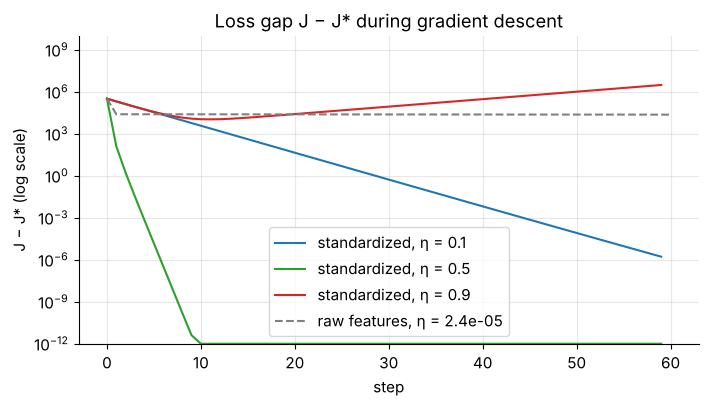

In [75]:
theta_z_ref = np.linalg.lstsq(Az_train, y_train, rcond=None)[0]       # exact optimum in z-coordinates
J_z_ref = mse(theta_z_ref, Az_train, y_train)
fig, ax = plt.subplots(figsize=(8, 4))
for lr, col in [(0.1, "C0"), (0.5, "C2"), (0.9, "C3")]:
    path_z, status = gradient_descent(lambda t: mse_grad(t, Az_train, y_train), np.zeros(5), lr=lr,
                                      max_iter=300, tol=0)
    gaps = np.array([mse(p, Az_train, y_train) for p in path_z]) - J_z_ref
    done = np.flatnonzero(gaps < 1e-6 * J_z_ref)
    if len(done):
        msg = f"gap < 1e-6·J* after {done[0]} steps"
    else:
        msg = f"no convergence: J - J* grew from {gaps[0]:.2e} to {gaps[-1]:.2e} in {len(gaps) - 1} steps"
    print(f"eta = {lr}: {msg}")
    ax.semilogy(np.maximum(gaps[:60], 1e-12), color=col, label=f"standardized, η = {lr}")
gaps_raw = np.array([mse(p, A_train, y_train) for p in path_raw[:61]]) - J_ref
ax.semilogy(gaps_raw, color="gray", ls="--", label=f"raw features, η = {eta_raw:.1e}")
ax.set(title="Loss gap J − J* during gradient descent", xlabel="step", ylabel="J − J* (log scale)", ylim=(1e-12, 1e10))
ax.legend()
plt.show()
theta_gd_z = gradient_descent(lambda t: mse_grad(t, Az_train, y_train), np.zeros(5), lr=0.5, max_iter=1000)[0][-1]

With standardized features, $\eta = 0.5$ (close to the optimal $0.503$) brings the loss within one part in a million of
the optimum in **4 steps**, and $\eta = 0.1$ needs 44. But $\eta = 0.9$ exceeds the limit $2/\lambda_{\max} \approx 0.872$ and
diverges, exactly as the eigenvalue analysis predicted, even though $0.9$ "looks" like a modest learning rate.
Compare the gray dashed line: on raw features the same number of steps achieves almost nothing.

> **Key idea.** Feature scaling does not change the model or the optimum, but it changes the *geometry* that gradient
> descent sees. For linear regression with z-scored, weakly correlated features, the Hessian is close to $2I$, and a
> learning rate around $0.5$ is close to ideal. That is why "standardize, then use $\eta \approx 0.1$–$0.5$" is a sensible
> default for this model.

### 10.6 Back to original units, and what the coefficients mean

The model was trained on z-scores, but people think in m² and kWh. Applying Section 9.7 to every feature,
$\hat y = \tilde b + \sum_j \tilde w_j \frac{x_j - \mu_j}{\sigma_j}$ becomes

$$
w_j = \frac{\tilde w_j}{\sigma_j}, \qquad b = \tilde b - \sum_{j=1}^{d} \frac{\tilde w_j\,\mu_j}{\sigma_j} = \tilde b - \sum_{j=1}^{d} w_j\,\mu_j .
$$

In [76]:
def unstandardize(theta_z, mu, sd):
    """Convert (b~, w~_1, ..., w~_d), fitted on z-scores, to (b, w_1, ..., w_d) in the original units."""
    w = theta_z[1:] / sd
    b = theta_z[0] - np.sum(w * mu)
    return np.r_[b, w]


theta_gd = unstandardize(theta_gd_z, mu_tr, sd_tr)
display(pd.DataFrame({"standardized (GD)": theta_gd_z, "original units (GD)": theta_gd,
                      "normal equation": theta_ref, "true": np.r_[TRUE_B, TRUE_W]}, index=param_names).round(3))
print(f"mean of y_train = {y_train.mean():.3f}")

,standardized (GD),original units (GD),normal equation,true
intercept,545.924,92.435,92.435,80.0
area_m2,92.753,1.832,1.832,1.8
occupants,64.061,37.340,37.340,40.0
ac_hours,71.487,20.765,20.765,22.0
solar_kw,-59.746,-34.227,-34.227,-35.0


mean of y_train = 545.924


How to read this table:

- The two GD columns describe **the same model**, and the original-units version matches the normal equation to all
  printed digits.
- **Standardized intercept** $\tilde b \approx 545.9$ $=$ the mean kWh of the training homes: the prediction for a home that is
  average in every feature (about 133 m², 3.6 occupants, 5.9 hours of AC, 1.4 kW of solar). Meaningful.
- **Original intercept** $b \approx 92.4$: the prediction for a home with 0 m², 0 occupants, no AC and no solar. No such
  home exists, so treat it as a constant that positions the plane, not as a "base load" estimate, even though here,
  by construction, the true baseline happens to be 80.
- **Original-unit weights** answer "what if this feature increases by one unit while the others stay fixed?": one more
  occupant adds about 37 kWh, one more daily AC hour about 21 kWh, each kW of solar removes about 34 kWh.
- **Standardized weights** answer "what if this feature increases by one *typical spread* (one standard deviation)?",
  which puts features measured in different units on a common footing: area (about 93 kWh per SD) matters most in this
  population, then AC (71), occupants (64) and solar ($-60$). Raw weights cannot be compared this way: $1.83$ per m²
  is not "smaller" than $37.3$ per occupant, because the units differ.

> **Common pitfall.** Standardized weights describe importance *in this dataset's spread of values*. Collect homes that
> all have 2–3 occupants and the occupants' standardized weight shrinks, although the physics did not change.
> And "holding the other features fixed" is only meaningful when the features *can* vary separately. Section 11 shows
> what happens when they cannot.

### 10.7 Evaluating on the test set, and a library cross-check

Two standard measures of fit, computed on data the model has never seen:

- **RMSE** $= \sqrt{\frac{1}{m}\sum_i (\hat y_i - y_i)^2}$, in the target's units (kWh), so it reads as "a typical miss".
- **$R^2$** $= 1 - \frac{\sum_i (y_i - \hat y_i)^2}{\sum_i (y_i - \bar y)^2}$: the fraction of the target's variance the model
  explains. $R^2 = 1$ is perfect, and $R^2 = 0$ is no better than always predicting the mean $\bar y$.

The predictions can be made either way (standardized test features with $\tilde{\boldsymbol\theta}$, or raw test features
with $\boldsymbol\theta$) and must agree.

In [77]:
from sklearn.linear_model import LinearRegression


def rmse(y, y_hat):
    return np.sqrt(np.mean((y - y_hat) ** 2))


def r2(y, y_hat):
    return 1 - np.sum((y - y_hat) ** 2) / np.sum((y - y.mean()) ** 2)


pred_test_raw = add_ones(X_test) @ theta_gd              # original units
pred_test_z = add_ones(Z_test) @ theta_gd_z              # standardized units (training mu and sigma!)
print("max |difference| between the two ways of predicting:", f"{np.max(np.abs(pred_test_raw - pred_test_z)):.1e}")
pred_train = add_ones(X_train) @ theta_gd
baseline = np.full_like(y_test, y_train.mean())          # "always predict the training mean"
print(f"train: RMSE = {rmse(y_train, pred_train):6.2f} kWh, R^2 = {r2(y_train, pred_train):.4f}")
print(f"test : RMSE = {rmse(y_test, pred_test_raw):6.2f} kWh, R^2 = {r2(y_test, pred_test_raw):.4f}")
print(f"test baseline (predict {y_train.mean():.1f} for every home): RMSE = {rmse(y_test, baseline):6.2f} kWh")

sk_model = LinearRegression().fit(X_train, y_train)
print("scikit-learn intercept and weights:", np.round(np.r_[sk_model.intercept_, sk_model.coef_], 3))
print("our GD (original units)           :", np.round(theta_gd, 3))

max |difference| between the two ways of predicting: 1.1e-13
train: RMSE =  33.92 kWh, R^2 = 0.9467
test : RMSE =  37.58 kWh, R^2 = 0.9441
test baseline (predict 545.9 for every home): RMSE = 160.61 kWh


scikit-learn intercept and weights: [ 92.435   1.832  37.34   20.765 -34.227]
our GD (original units)           : [ 92.435   1.832  37.34   20.765 -34.227]


The model explains about 94 % of the variance on unseen homes, and its typical miss (about 38 kWh) is close to the
noise level of 35 kWh that we built into the data, the part no model can predict. Compared with the baseline's
typical miss of about 161 kWh, the four features carry most of the signal. scikit-learn (which uses a direct
least-squares solver, not GD) agrees with our gradient-descent coefficients.

**Quick check.** A colleague standardizes the *test* set with its own mean and standard deviation "so that it also has
mean 0 and SD 1", then applies $\tilde{\boldsymbol\theta}$. What goes wrong?

<details>
<summary>Answer</summary>

The model learned "a home 1 SD above the *training* mean in area uses about 93 kWh more". Re-standardizing the test set
shifts every test home by the difference between the test and training means: here the test homes are smaller on
average, so re-centering would make them look average-sized and inflate every prediction for them. Even a single
future home could not be standardized "with its own statistics" at all. The scaler's $\mu$ and $\sigma$ are model
parameters, fitted once on the training data.
</details>

### ✏️ Exercise 9: a z-score scaler that survives constant columns

Real datasets sometimes contain a column that is constant in the training data (for example, a sensor that was
never switched on). Its standard deviation is 0, and naive standardization divides by zero.

Write `fit_scaler(X_tr)` returning the column means and standard deviations (`ddof=0`) of the training matrix,
with any standard deviation equal to 0 replaced by 1, and `transform(X, mu, sd)` that applies them to any matrix.
The checker also compares against scikit-learn's `StandardScaler`, which uses the same convention.

In [78]:
# ✏️ Exercise 9: a z-score scaler
def fit_scaler(X_tr):
    """Return (mu, sd): per-column mean and standard deviation (ddof=0) of X_tr, with sd == 0 replaced by 1."""
    # YOUR CODE HERE
    raise NotImplementedError


def transform(X, mu, sd):
    """Standardize the rows of X with training statistics mu and sd."""
    # YOUR CODE HERE
    raise NotImplementedError


def _test():
    from sklearn.preprocessing import StandardScaler
    X_tr = np.array([[1.0, 5.0, 10.0], [2.0, 5.0, 30.0], [3.0, 5.0, 20.0], [6.0, 5.0, 40.0]])
    mu, sd = fit_scaler(X_tr)
    assert np.allclose(mu, [3.0, 5.0, 25.0]), f"means should be [3, 5, 25], got {mu}"
    assert np.allclose(sd, [np.sqrt(3.5), 1.0, np.sqrt(125.0)]), \
        f"sd should be [sqrt(3.5), 1, sqrt(125)] (ddof=0, constant column -> 1), got {sd}"
    Z = transform(X_tr, mu, sd)
    assert np.all(np.isfinite(Z)), "the constant column produced nan or inf"
    assert np.allclose(Z.mean(axis=0), 0), "standardized training columns must have mean 0"
    X_new = np.array([[4.0, 5.0, 0.0], [0.0, 7.0, 25.0]])
    expected = StandardScaler().fit(X_tr).transform(X_new)
    assert np.allclose(transform(X_new, mu, sd), expected), "new rows must be transformed with the TRAINING statistics"


run_check("Exercise 9", _test)

⏳ Exercise 9: not implemented yet; fill in the function and re-run this cell.


<details>
<summary><b>Solution</b> (try first!)</summary>

```python
def fit_scaler(X_tr):
    X_tr = np.asarray(X_tr, dtype=float)
    mu = X_tr.mean(axis=0)
    sd = X_tr.std(axis=0)                 # ddof=0
    sd = np.where(sd == 0, 1.0, sd)       # constant column: leave it centered (all zeros)
    return mu, sd

def transform(X, mu, sd):
    return (np.asarray(X, dtype=float) - mu) / sd
```
A constant training column becomes all zeros after centering, so dividing by 1 keeps it at 0, and its weight then has no
effect on training (its gradient entry is always 0). On new data the column is simply shifted by the training mean.
</details>

### 10.8 Per-sample, mini-batch and batch updates

The batch gradient is an **average of per-example gradients**:

$$
\nabla J(\boldsymbol\theta) = \frac{1}{m}\sum_{i=1}^{m} \mathbf g_i(\boldsymbol\theta), \qquad
\mathbf g_i(\boldsymbol\theta) = 2\,(\mathbf x_i^\top\boldsymbol\theta - y_i)\,\mathbf x_i ,
$$

where $\mathbf x_i$ is row $i$ of the design matrix (including its leading 1). Each $\mathbf g_i$ is example $i$'s "opinion"
about which way to move. That suggests three ways to update:

| Method | Update uses | Updates per epoch (one pass over the data) |
|---|---|---|
| **Batch** gradient descent | the average of all $m$ opinions | 1 |
| **Per-sample** (sequential, online, *stochastic* gradient descent, SGD) | one example: $\boldsymbol\theta \leftarrow \boldsymbol\theta - \eta\,\mathbf g_i(\boldsymbol\theta)$ | $m$ |
| **Mini-batch** | the average over a random batch of $B$ examples | $m/B$ |

If the example is picked uniformly at random, $\mathbb E[\mathbf g_i] = \nabla J$: a single example's gradient is an
**unbiased but noisy estimate** of the full gradient, and averaging over $B$ examples divides the noise variance by $B$.
Far from the optimum all examples roughly agree on the direction, so the cheap noisy steps make rapid progress.
Near the optimum the examples disagree (each wants the plane to pass through *its own* point), so with a constant
$\eta$ per-sample updates never settle, but they jitter around $\boldsymbol\theta^*$ in a cloud whose size grows with $\eta$.
The remedies are a **decaying learning rate** (for example $\eta_k = \eta_0/(1 + k/K)$ after $k$ updates), larger
batches, or both.

The experiment below trains on the standardized homes, reshuffling the order every epoch, and records the training
loss as a function of **epochs** (how many examples' worth of gradients have been computed), which makes the methods
comparable in work done.

In [79]:
def train_minibatch(A, y, batch_size, lr_fn, epochs, seed=0, log_every=1):
    """Mini-batch gradient descent on the MSE (A includes the ones column).

    batch_size=1 gives per-sample updates (SGD), and batch_size=len(y) gives batch gradient descent.
    lr_fn(k) returns the learning rate for update number k = 0, 1, 2, ...
    Returns (theta, epochs_seen, loss) with the training loss logged every `log_every` updates.
    """
    shuffler = np.random.default_rng(seed)
    m = len(y)
    theta, k = np.zeros(A.shape[1]), 0
    seen, losses = [0.0], [mse(theta, A, y)]
    for epoch in range(epochs):
        order = shuffler.permutation(m)                  # a fresh random order every epoch
        for start in range(0, m, batch_size):
            rows = order[start:start + batch_size]
            theta = theta - lr_fn(k) * mse_grad(theta, A[rows], y[rows])
            k += 1
            if k % log_every == 0:
                seen.append(epoch + (start + len(rows)) / m)
                losses.append(mse(theta, A, y))
    return theta, np.array(seen), np.array(losses)


configs = {                      # name: (batch size, learning-rate schedule, log every k updates)
    "batch, η = 0.5": (180, lambda k: 0.5, 1),
    "mini-batch 16, η = 0.05": (16, lambda k: 0.05, 1),
    "per-sample, η = 0.01": (1, lambda k: 0.01, 10),
    "per-sample, η = 0.005": (1, lambda k: 0.005, 10),
    "per-sample, η = 0.02/(1 + k/360)": (1, lambda k: 0.02 / (1 + k / 360), 10),
}
runs = {name: train_minibatch(Az_train, y_train, bs, fn, epochs=20, log_every=ev)
        for name, (bs, fn, ev) in configs.items()}


def rel_gap_at(seen, losses, e):
    """(J - J*) / J* at the last logged point not later than epoch e."""
    i = np.searchsorted(seen, e + 1e-9) - 1
    return (losses[i] - J_z_ref) / J_z_ref


table = pd.DataFrame({name: [rel_gap_at(s, L, e) for e in [0.25, 1, 2, 5, 20]] + [np.mean((L[s > 15] - J_z_ref) / J_z_ref)]
                      for name, (_, s, L) in runs.items()},
                     index=["1/4 ep", "1 ep", "2 ep", "5 ep", "20 ep", "avg 15-20"]).T
print("relative gap (J - J*) / J* on the training set, after a given number of epochs (ep):")
print(table.clip(lower=0).to_string(float_format=lambda v: f"{v:9.2g}"))

relative gap (J - J*) / J* on the training set, after a given number of epochs (ep):
                                    1/4 ep      1 ep      2 ep      5 ep     20 ep  avg 15-20
batch, η = 0.5                     2.8e+02      0.11    0.0014   1.3e-08         0          0
mini-batch 16, η = 0.05            1.9e+02        20       1.5    0.0068    0.0093     0.0079
per-sample, η = 0.01                    68      0.18     0.043      0.02     0.029      0.032
per-sample, η = 0.005              1.4e+02         7       0.2    0.0059    0.0073       0.01
per-sample, η = 0.02/(1 + k/360)        21     0.025     0.045    0.0082   0.00042     0.0022


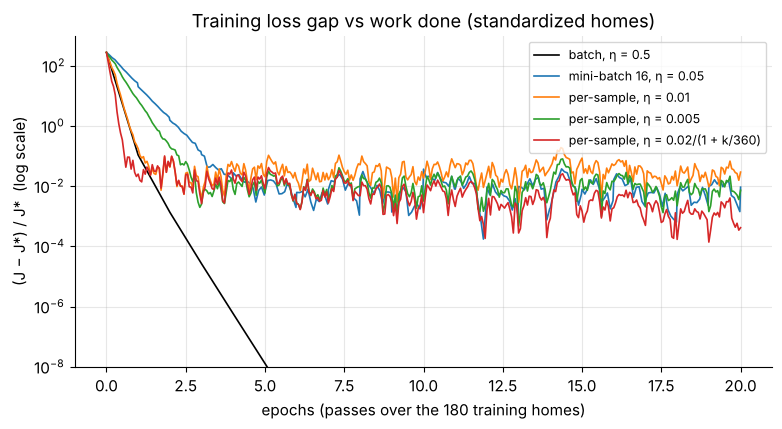

In [80]:
fig, ax = plt.subplots(figsize=(9, 4.3))
for (name, (_, seen, losses)), col in zip(runs.items(), ["k", "C0", "C1", "C2", "C3"]):
    ax.semilogy(seen, np.maximum((losses - J_z_ref) / J_z_ref, 1e-10), color=col, lw=1.2, label=name)
ax.set(title="Training loss gap vs work done (standardized homes)", xlabel="epochs (passes over the 180 training homes)",
       ylabel="(J − J*) / J*  (log scale)", ylim=(1e-8, 1e3))
ax.legend(fontsize=9, loc="upper right")
plt.show()

What the table and plot show (the numbers are the relative excess loss $(J - J^*)/J^*$, where 0.01 means "1 % above the best
possible training loss"):

- **Early progress favors per-sample updates.** After a quarter of an epoch, batch GD has not made a single update
  (its excess loss is still the initial $280\,J^*$), while the per-sample runs have already cut it to between $21\,J^*$ and
  $140\,J^*$, and after one epoch the decaying-rate run (0.025) is ahead of batch GD (0.11). With millions of training
  examples, being useful *before* finishing one pass is a big deal.
- **Constant-rate per-sample updates stall at a noise floor.** With $\eta = 0.01$ the loss hovers about 3 % above $J^*$
  from epoch 2 onward and never improves, while halving the rate to $0.005$ lowers the floor (to about 1 %) but makes the start
  slower. Mini-batches of 16 with $\eta = 0.05$ (each step averages 16 gradients, so it tolerates a larger rate) settle at
  a similar floor, just under 1 %.
- **A decaying learning rate gets the best of both**: a fast start like large-$\eta$ SGD, then ever smaller jitter
  (about 0.04 % above $J^*$ after 20 epochs, and still improving).
- **On this small, well-conditioned problem, full-batch GD with a well-chosen $\eta$ wins** after the first epoch: it is
  within about $10^{-8}$ (relative) of the optimum after five epochs. There is no universal winner: the right choice depends on the data size,
  the hardware (mini-batches use vectorized/GPU arithmetic efficiently) and how precise the answer must be.

The noisy steps have one more benefit on *non-convex* losses (Section 8.4): the jitter can shake the iterate out of
shallow local minima and off saddle points. That, plus cheap updates on huge datasets, is why neural networks are
almost always trained with mini-batch SGD (and its adaptive variants).

> **Common pitfall.** Not shuffling. If the examples are sorted (say, by area), per-sample updates first see only small
> homes, then only large ones, and the parameters chase whichever group they saw last. Reshuffle every epoch.

Why did the per-sample runs need learning rates 25–100 times smaller than batch GD's $0.5$? Look at the loss of a
**single** example, $(\mathbf a_i^\top\boldsymbol\theta - y_i)^2$ (with $\mathbf a_i$ the row of the design matrix). Its Hessian is $2\mathbf a_i\mathbf a_i^\top$, a rank-one
matrix whose only nonzero eigenvalue is $2\lVert\mathbf a_i\rVert^2$: each example's own bowl is a sharp trough, much steeper than the
averaged bowl.

In [81]:
row_norm2 = np.sum(Az_train ** 2, axis=1)                  # ||a_i||^2 for every training row
print(f"||a_i||^2 over the 180 training rows: mean {row_norm2.mean():.2f}, max {row_norm2.max():.2f}")
print(f"one-example step limits 1/||a_i||^2: typical {1 / row_norm2.mean():.3f}, strictest {1 / row_norm2.max():.3f}"
      f"   (batch GD limit: {2 / lam_z[-1]:.3f})")

||a_i||^2 over the 180 training rows: mean 5.00, max 10.03
one-example step limits 1/||a_i||^2: typical 0.200, strictest 0.100   (batch GD limit: 0.872)


One update multiplies example $i$'s own error by $1 - 2\eta\lVert\mathbf a_i\rVert^2$ (the Section 5.4 factor with curvature $2\lVert\mathbf a_i\rVert^2$): with
$\eta = 1/(2\lVert\mathbf a_i\rVert^2)$ the plane fits that example perfectly after the step, at $\eta = 1/\lVert\mathbf a_i\rVert^2$ the error just flips sign,
and beyond that the step makes the example's own error *larger*. With standardized features $\lVert\mathbf a_i\rVert^2 = 1 + \sum_j z_{ij}^2$ averages $1 + d = 5$, so per-sample steps
must stay well below about $0.1$–$0.2$ to avoid violently over-correcting for individual homes, while batch GD, which sees the
gentler *average* curvature, tolerates up to $0.87$.

> **Going deeper.** This one-example-at-a-time rule for linear models is classic: with $\eta_k = 1/(2\lVert\mathbf a_i\rVert^2)$ it is the
> *Kaczmarz method* for solving linear systems, and with a small constant rate it is the *LMS* (least mean squares) rule used in
> adaptive filters since the 1960s.

### ✏️ Exercise 10: one epoch of per-sample updates

Write `sgd_epoch(theta, A, y, lr, order)` that visits the rows of the design matrix `A` (which already contains the
column of ones) in the given `order` and, for each row $i$, applies $\boldsymbol\theta \leftarrow \boldsymbol\theta - \eta\cdot 2(\mathbf a_i^\top\boldsymbol\theta - y_i)\,\mathbf a_i$.
Return the new parameter vector without modifying the input array.

In [82]:
# ✏️ Exercise 10: per-sample (sequential) updates
def sgd_epoch(theta, A, y, lr, order):
    """One pass of per-sample gradient descent on the MSE, visiting rows of A in `order`."""
    # YOUR CODE HERE
    raise NotImplementedError


def _test():
    A = np.array([[1.0, 1.0], [1.0, 2.0], [1.0, 3.0]])
    y = np.array([2.0, 3.0, 5.0])
    theta0 = np.array([0.0, 0.0])
    out = sgd_epoch(theta0, A, y, lr=0.1, order=[0])
    assert np.allclose(out, [0.4, 0.4]), f"one update on row 0 from (0, 0) should give (0.4, 0.4), got {out}"
    assert np.allclose(theta0, 0), "do not modify the input theta in place"
    out = sgd_epoch(theta0, A, y, lr=0.1, order=[0, 1, 2])
    assert np.allclose(out, [0.936, 1.648]), f"expected (0.936, 1.648) after rows 0, 1, 2, got {out}"
    out_rev = sgd_epoch(theta0, A, y, lr=0.1, order=[2, 1, 0])
    assert not np.allclose(out_rev, out), "the visiting order should matter for per-sample updates"
    exact = np.array([1.0, 2.0])                       # y = 1 + 2x passes through all three points of A, y_line
    y_line = A @ exact
    assert np.allclose(sgd_epoch(exact, A, y_line, 0.1, [0, 1, 2]), exact), "a perfect fit must not move"


run_check("Exercise 10", _test)

⏳ Exercise 10: not implemented yet; fill in the function and re-run this cell.


<details>
<summary><b>Solution</b> (try first!)</summary>

```python
def sgd_epoch(theta, A, y, lr, order):
    theta = np.array(theta, dtype=float)          # a copy, so the caller's array is untouched
    for i in order:
        error = A[i] @ theta - y[i]               # prediction minus target for ONE example
        theta = theta - lr * 2 * error * A[i]     # that example's gradient step
    return theta
```
By hand for the checker's data: row 0 has error $-2$, so $\boldsymbol\theta = (0,0) - 0.1\cdot2\cdot(-2)\cdot(1,1) = (0.4, 0.4)$,
row 1 has error $0.4 + 0.8 - 3 = -1.8$, giving $(0.4 + 0.36,\ 0.4 + 0.72) = (0.76, 1.12)$, and row 2 has error
$0.76 + 3.36 - 5 = -0.88$, so the step is $0.1\cdot 2\cdot 0.88 = 0.176$ times $(1, 3)$, giving $(0.936, 1.648)$.
Visiting the rows in the reverse order ends at $(0.28, 1.48)$ instead: per-sample updates depend on the order.
</details>

## 11. Case study: multicollinearity

In Section 10 the features were nearly uncorrelated, and every coefficient landed close to its true value. Real
features are often strongly correlated with each other: floor area and number of rooms, a person's height and
weight, distance driven and time spent driving. Then something surprising happens: the model still predicts well,
but its individual coefficients become unreliable, sometimes with the **wrong sign**. This section shows the effect,
explains it with the loss-surface geometry from Sections 6 and 9, and introduces the standard diagnostic, the
**variance inflation factor (VIF)**.

### 11.1 Two features that tell the same story

A delivery company logs 30 van trips: the distance (km), the time spent driving (hours) and the fuel used (liters).
We simulate the trips so that fuel truly increases with **both** distance and time:

$$
\text{fuel} = 0.5 + 0.08\,\text{km} + 0.8\,\text{hours} + \varepsilon, \qquad \varepsilon \sim \mathcal N(0, 0.4^2),
$$

(0.08 L per km of driving, plus 0.8 L per hour for idling, traffic lights and air-conditioning). The catch: the vans
travel at a fairly steady 50 km/h, so the driving time is almost determined by the distance,
$\text{hours} \approx \text{km}/50$ give or take a few minutes.

correlation between km and hours: r = 0.9863


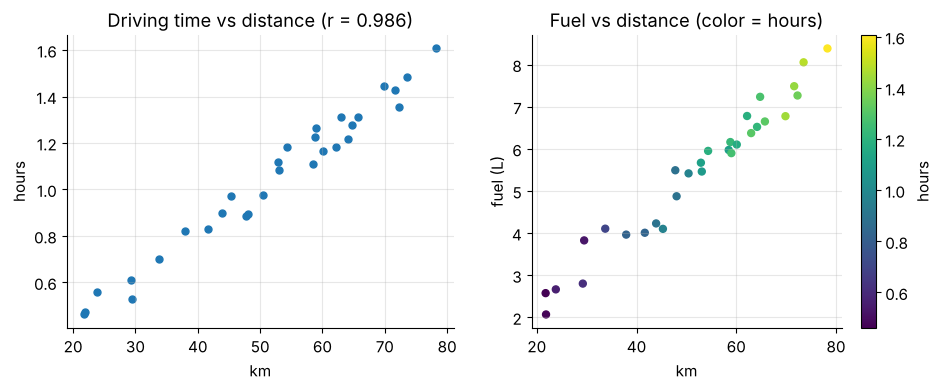

In [83]:
def make_trips(seed, n=30):
    """Simulate n delivery trips: distance (km), driving time (h) and fuel used (L)."""
    g = np.random.default_rng(seed)
    km = g.uniform(20, 80, n)
    hours = km / 50 + g.normal(0, 0.06, n)            # about 50 km/h, give or take ~4 minutes
    fuel = 0.5 + 0.08 * km + 0.8 * hours + g.normal(0, 0.4, n)
    return km, hours, fuel


TRUE_TRIP = np.array([0.5, 0.08, 0.8])                 # (intercept, per km, per hour)
km, hours, fuel = make_trips(seed=14)
r_kh = np.corrcoef(km, hours)[0, 1]
print(f"correlation between km and hours: r = {r_kh:.4f}")

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
axes[0].scatter(km, hours, s=25)
axes[0].set(title=f"Driving time vs distance (r = {r_kh:.3f})", xlabel="km", ylabel="hours")
sc = axes[1].scatter(km, fuel, c=hours, cmap="viridis", s=25)
fig.colorbar(sc, ax=axes[1], label="hours")
axes[1].set(title="Fuel vs distance (color = hours)", xlabel="km", ylabel="fuel (L)")
plt.show()

### 11.2 One fit: does driving longer *save* fuel?

Fit $\text{fuel} \approx b + w_{\text{km}}\,\text{km} + w_{\text{h}}\,\text{hours}$ by least squares (the normal equation,
Section 9.6, and gradient descent would converge to the same point, only slowly, see 11.4), and also fit a model that uses
distance alone.

In [84]:
A_trip = add_ones(np.column_stack([km, hours]))
theta_trip = np.linalg.lstsq(A_trip, fuel, rcond=None)[0]
A_km = add_ones(km)
theta_km_only = np.linalg.lstsq(A_km, fuel, rcond=None)[0]
print(f"true model      : fuel = {TRUE_TRIP[0]:.3f} + {TRUE_TRIP[1]:.4f}·km + {TRUE_TRIP[2]:.3f}·hours")
print(f"fitted (2 feats): fuel = {theta_trip[0]:.3f} + {theta_trip[1]:.4f}·km + ({theta_trip[2]:.3f})·hours"
      f"   RMSE = {rmse(fuel, A_trip @ theta_trip):.3f} L")
print(f"fitted (km only): fuel = {theta_km_only[0]:.3f} + {theta_km_only[1]:.4f}·km"
      f"                    RMSE = {rmse(fuel, A_km @ theta_km_only):.3f} L")

typical = np.array([1.0, 50.0, 1.0])     # 50 km in 1 hour: like the trips in the data
odd = np.array([1.0, 50.0, 2.0])         # 50 km in 2 hours (a traffic jam): unlike any trip in the data
print(f"typical trip (50 km, 1 h): true {typical @ TRUE_TRIP:.2f} L, fitted {typical @ theta_trip:.2f} L")
print(f"odd trip     (50 km, 2 h): true {odd @ TRUE_TRIP:.2f} L, fitted {odd @ theta_trip:.2f} L")

true model      : fuel = 0.500 + 0.0800·km + 0.800·hours
fitted (2 feats): fuel = 0.222 + 0.1259·km + (-1.272)·hours   RMSE = 0.318 L
fitted (km only): fuel = 0.170 + 0.1013·km                    RMSE = 0.325 L
typical trip (50 km, 1 h): true 5.30 L, fitted 5.25 L
odd trip     (50 km, 2 h): true 6.10 L, fitted 3.98 L


Taken literally, the fitted model says "every extra hour of driving *saves* 1.27 liters of fuel", which is physically
absurd, and the truth is $+0.8$. Yet the model is not broken as a predictor: its RMSE (0.318 L) is as good as the
distance-only model's, and for a typical trip it predicts 5.25 L versus the true 5.30 L. Only for the "odd" trip
(50 km in two hours, a combination that never occurs in the data) does it fail badly, predicting *less* fuel for the
slower trip.

What happened? Because hours $\approx$ km/50 in every trip, the data contain almost no information about the effect of
hours *with distance held fixed*. Raising $w_{\text{km}}$ a little and lowering $w_{\text{h}}$ by about 50 times as much
leaves every prediction nearly unchanged, so the data can barely tell such coefficient pairs apart, and the noise
decides where the fit lands.

### 11.3 Re-sampling the data: coefficients wobble, predictions don't

How much would the coefficients change with slightly different data? The **bootstrap** answers this using only the
data in hand: draw 30 trips *with replacement* from the 30 we have (some trips appear twice, some not at all), refit,
and repeat many times. The spread of the refitted coefficients estimates how uncertain each coefficient is. Because
this is a simulation, we can also do what is impossible in real life: draw 1,000 genuinely **fresh** datasets of 30
trips from the true process and fit each one.

In [85]:
boot_rng = np.random.default_rng(0)
n_boot = 2000
boot_coefs = np.empty((n_boot, 3))
for k in range(n_boot):
    rows = boot_rng.integers(0, len(fuel), len(fuel))            # resample trips with replacement
    boot_coefs[k] = np.linalg.lstsq(A_trip[rows], fuel[rows], rcond=None)[0]

fresh_coefs = np.empty((1000, 3))
for s in range(1000):
    k_s, h_s, f_s = make_trips(seed=1000 + s)
    fresh_coefs[s] = np.linalg.lstsq(add_ones(np.column_stack([k_s, h_s])), f_s, rcond=None)[0]

summary = pd.DataFrame({
    "bootstrap (one dataset)": [boot_coefs[:, 1].std(), boot_coefs[:, 2].std(), np.mean(boot_coefs[:, 2] < 0),
                                (boot_coefs @ typical).std(), (boot_coefs @ odd).std()],
    "1,000 fresh datasets": [fresh_coefs[:, 1].std(), fresh_coefs[:, 2].std(), np.mean(fresh_coefs[:, 2] < 0),
                             (fresh_coefs @ typical).std(), (fresh_coefs @ odd).std()]},
    index=["SD of w_km", "SD of w_hours", "fraction with w_hours < 0",
           "SD of prediction, typical trip (L)", "SD of prediction, odd trip (L)"])
display(summary.round(3))
print(f"fresh datasets: mean w_km = {fresh_coefs[:, 1].mean():.4f} (true 0.08), "
      f"mean w_hours = {fresh_coefs[:, 2].mean():.3f} (true 0.8)")
print(f"correlation between bootstrap w_km and w_hours: {np.corrcoef(boot_coefs[:, 1], boot_coefs[:, 2])[0, 1]:.3f}")

,bootstrap (one dataset),"1,000 fresh datasets"
SD of w_km,0.023,0.027
SD of w_hours,1.222,1.348
fraction with w_hours < 0,0.849,0.290
"SD of prediction, typical trip (L)",0.064,0.075
"SD of prediction, odd trip (L)",1.206,1.351


fresh datasets: mean w_km = 0.0805 (true 0.08), mean w_hours = 0.772 (true 0.8)
correlation between bootstrap w_km and w_hours: -0.985


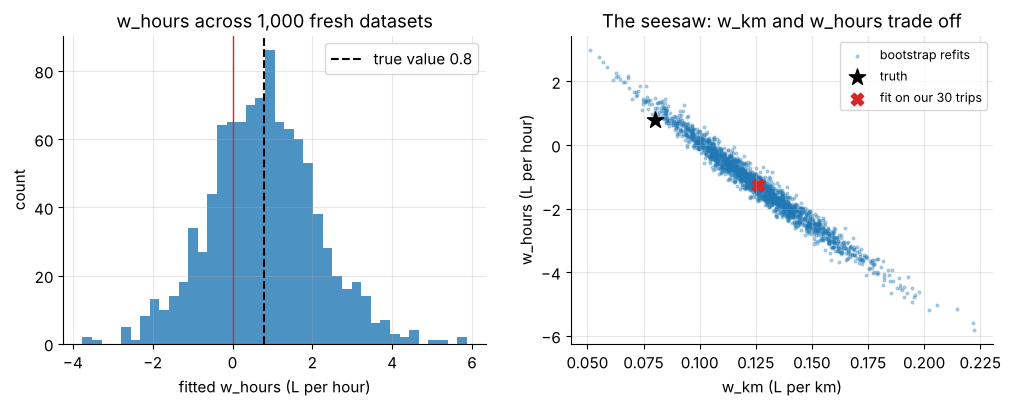

In [86]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(fresh_coefs[:, 2], bins=40, color="C0", alpha=0.8)
axes[0].axvline(0.8, color="k", ls="--", label="true value 0.8")
axes[0].axvline(0, color="C3", lw=1)
axes[0].set(title="w_hours across 1,000 fresh datasets", xlabel="fitted w_hours (L per hour)", ylabel="count")
axes[0].legend()
axes[1].scatter(boot_coefs[:, 1], boot_coefs[:, 2], s=4, alpha=0.3, label="bootstrap refits")
axes[1].scatter([TRUE_TRIP[1]], [TRUE_TRIP[2]], color="k", marker="*", s=150, label="truth")
axes[1].scatter([theta_trip[1]], [theta_trip[2]], color="C3", marker="X", s=80, label="fit on our 30 trips")
axes[1].set(title="The seesaw: w_km and w_hours trade off", xlabel="w_km (L per km)", ylabel="w_hours (L per hour)")
axes[1].legend(fontsize=9)
plt.show()

The pattern is the signature of multicollinearity:

- Over fresh datasets the fitted $w_{\text{hours}}$ is right **on average** (about 0.77 versus the true 0.8, since least squares
  is unbiased), but its standard deviation (about 1.35) is larger than the value itself, so about **29 % of datasets
  produce a negative coefficient**. Our dataset happened to be one of them, and bootstrapping it shows a similar huge spread.
  (Note that 85 % of the *bootstrap* refits are negative: resamples of our data scatter around *our* estimate $-1.27$,
  not around the truth. The bootstrap measures how uncertain an estimate is, not which direction it is wrong in.)
- The coefficients move in a **seesaw**: their bootstrap correlation is about $-0.99$. Whatever one gains, the other loses,
  along a line on which predictions for typical trips barely change.
- Predictions for **typical trips are stable** (standard deviation about 0.06–0.07 L), while predictions for the **odd
  trip are not** (about 1.2–1.35 L). The model is reliable where the data are, and unreliable off the data's narrow ridge.

### 11.4 Why: a long, flat, *tilted* valley

Standardize both features. Then $\frac{1}{m}Z^\top Z$ is the correlation matrix, and the Hessian of the MSE in the two
weights is

$$
H = 2\begin{pmatrix} 1 & r \\ r & 1 \end{pmatrix}, \qquad \text{eigenvalues } 2(1 + r) \text{ along } \tfrac{1}{\sqrt2}(1, 1)
\;\text{ and }\; 2(1 - r) \text{ along } \tfrac{1}{\sqrt2}(1, -1),
$$

so the condition number is $\kappa = \frac{1 + r}{1 - r}$. With $r \approx 0.986$ that is about 145: the valley is long, almost
flat along the diagonal direction "raise one weight, lower the other", and, unlike Section 6.6, **tilted** at
45° to the axes. Rescaling the features individually cannot fix a tilted valley (Section 6.7's pitfall): they are
already standardized. A flat valley floor means two things: gradient descent creeps along it (optimization is slow),
and a small change in the data moves the minimum a long way along it (the estimates are unstable).

Hessian (standardized weights):
 [[2.     1.9726]
 [1.9726 2.    ]]
eigenvalues 0.0274, 3.9726;  kappa = 145.0;  (1 + r)/(1 - r) = 145.0


limit 2/lambda_max = 0.503; GD from 0 with eta = 0.2: loss gap below 1e-6 after 964 steps; slow-direction factor per step = 0.9945


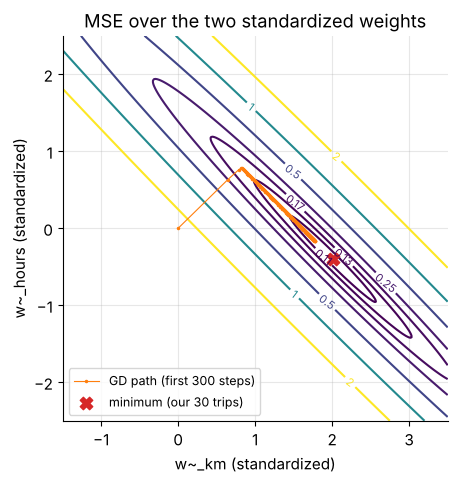

In [87]:
Z_trip = (np.column_stack([km, hours]) - np.column_stack([km, hours]).mean(axis=0)) / np.column_stack([km, hours]).std(axis=0)
H_trip = 2 / len(fuel) * Z_trip.T @ Z_trip
lam_trip = np.linalg.eigvalsh(H_trip)
print("Hessian (standardized weights):\n", np.round(H_trip, 4))
print(f"eigenvalues {lam_trip[0]:.4f}, {lam_trip[1]:.4f},  kappa = {lam_trip[1] / lam_trip[0]:.1f},  "
      f"(1 + r)/(1 - r) = {(1 + r_kh) / (1 - r_kh):.1f}")

A_trip_z = add_ones(Z_trip)
w_opt_z = np.linalg.lstsq(A_trip_z, fuel, rcond=None)[0]                   # (b~, w~_km, w~_hours)
G1, G2 = np.meshgrid(np.linspace(-1.5, 3.5, 250), np.linspace(-2.5, 2.5, 250))
# loss on a grid of (w~_km, w~_hours), with the intercept held at its optimum (broadcasting over the 30 trips)
Jz = np.mean((w_opt_z[0] + G1[..., None] * Z_trip[:, 0] + G2[..., None] * Z_trip[:, 1] - fuel) ** 2, axis=-1)

lam_full = np.linalg.eigvalsh(2 / len(fuel) * A_trip_z.T @ A_trip_z)      # all 3 parameters: {2(1-r), 2, 2(1+r)}
eta_trip = 0.2                                                             # safely below 2 / lambda_max = 0.503
path_trip, _ = gradient_descent(lambda t: mse_grad(t, A_trip_z, fuel), np.zeros(3), lr=eta_trip, max_iter=5000, tol=1e-10)
gap_trip = np.array([mse(p, A_trip_z, fuel) for p in path_trip]) - mse(w_opt_z, A_trip_z, fuel)
print(f"limit 2/lambda_max = {2 / lam_full[-1]:.3f}, GD from 0 with eta = {eta_trip}: loss gap below 1e-6 after "
      f"{np.argmax(gap_trip < 1e-6)} steps, slow-direction factor per step = {1 - eta_trip * lam_full[0]:.4f}")

fig, ax = plt.subplots(figsize=(6.5, 5))
cs = ax.contour(G1, G2, Jz, levels=[0.11, 0.13, 0.17, 0.25, 0.5, 1, 2], cmap="viridis")
ax.clabel(cs, fontsize=8, fmt="%g")
ax.plot(path_trip[:300, 1], path_trip[:300, 2], ".-", color="C1", ms=3, lw=0.8, label="GD path (first 300 steps)")
ax.scatter(*w_opt_z[1:], color="C3", marker="X", s=80, zorder=3, label="minimum (our 30 trips)")
ax.set(title="MSE over the two standardized weights", xlabel="w~_km (standardized)", ylabel="w~_hours (standardized)")
ax.set_aspect("equal")
ax.legend(loc="lower left", fontsize=9)
plt.show()

Gradient descent drops quickly onto the valley floor (the steep direction is "move both weights together") and then
creeps along the diagonal, shrinking the remaining error by only about 0.5 % per step, and it needs almost a thousand
steps although both features are standardized. The same flatness is what makes the *location* of the minimum fragile:
along the floor the loss changes by tiny amounts, so a few noisy points are enough to slide the minimum far along it.

### 11.5 Measuring it: the variance inflation factor

Correlations between pairs of features detect the two-feature case, but collinearity can also involve three or more
features (for example, `total = part_a + part_b`). The general diagnostic regresses **each feature on all the other
features**: if feature $j$ can be predicted well from the others (coefficient of determination $R_j^2$ close to 1), it
carries little independent information. The **variance inflation factor** of feature $j$ is

$$
\text{VIF}_j = \frac{1}{1 - R_j^2} .
$$

The name says what it measures: under the usual regression assumptions, the variance of the estimated $w_j$ is
$\text{VIF}_j$ times larger than it would be if feature $j$ were uncorrelated with the others (and had the same spread), so the
standard error is $\sqrt{\text{VIF}_j}$ times larger. With only two features, $R_j^2 = r^2$ and $\text{VIF} = 1/(1 - r^2)$.

| VIF | $R_j^2$ | standard error inflated by | usual reading |
|---|---|---|---|
| 1 | 0 | $\times 1$ | no collinearity |
| 5 | 0.8 | $\times 2.2$ | moderate, worth a look |
| 10 | 0.9 | $\times 3.2$ | strong, do not trust individual coefficients |
| 37 (our trips) | 0.97 | $\times 6.1$ | severe |

(The thresholds 5 and 10 are rules of thumb, not laws.)

In [88]:
from statsmodels.stats.outliers_influence import variance_inflation_factor
import statsmodels.api as sm

vif_by_formula = 1 / (1 - r_kh ** 2)
X_trip_const = sm.add_constant(np.column_stack([km, hours]))       # statsmodels expects the constant column included
vif_sm = [variance_inflation_factor(X_trip_const, j) for j in (1, 2)]
print(f"VIF from 1/(1 - r^2): {vif_by_formula:.2f}  -> standard errors inflated by sqrt(VIF) = {np.sqrt(vif_by_formula):.2f}")
print(f"statsmodels VIF for km, hours: {vif_sm[0]:.2f}, {vif_sm[1]:.2f}")

ols = sm.OLS(fuel, X_trip_const).fit()
ci = ols.conf_int()
for name, est, se, (lo, hi) in zip(["intercept", "km", "hours"], ols.params, ols.bse, ci):
    print(f"{name:9s}: estimate {est:7.3f}, standard error {se:6.3f}, 95% interval [{lo:6.3f}, {hi:6.3f}]")

X_homes_const = sm.add_constant(X_train)
print("VIFs of the four household features (Section 10):",
      np.round([variance_inflation_factor(X_homes_const, j) for j in range(1, 5)], 3))

VIF from 1/(1 - r^2): 36.76  -> standard errors inflated by sqrt(VIF) = 6.06
statsmodels VIF for km, hours: 36.76, 36.76
intercept: estimate   0.222, standard error  0.214, 95% interval [-0.218,  0.662]
km       : estimate   0.126, standard error  0.023, 95% interval [ 0.078,  0.174]
hours    : estimate  -1.272, standard error  1.187, 95% interval [-3.707,  1.164]
VIFs of the four household features (Section 10): [1.006 1.013 1.023 1.015]


The two VIFs agree (about 36.8), and statsmodels' standard errors tell the same story as the bootstrap: the 95 %
confidence interval for the hours coefficient runs from about $-3.7$ to $+1.2$, which contains the true value 0.8 *and*
zero *and* large negative values: the data simply cannot determine even its sign. The household features of Section 10,
by contrast, have VIFs of about 1.0, which is why their coefficients were trustworthy.

### 11.6 What to do about it

- **Do not over-interpret individual coefficients or their signs** when VIFs are high. Statements like "hours of driving
  reduce fuel use" are artifacts. Predictions *for inputs that resemble the training data* remain fine.
- **Drop or combine features.** If two features measure nearly the same thing, keep one (here, distance), or build a
  combination that carries the independent information (here, average speed = km / hours, or "extra minutes compared with
  the usual time for this distance").
- **Collect data that breaks the correlation**: trips in traffic jams, at night, on highways. Then the data contain
  information about each effect separately and the valley stops being flat.
- **Regularize.** Ridge regression adds a penalty $\lambda\lVert\mathbf w\rVert^2$ to the MSE. Its Hessian gains $2\lambda I$, which lifts
  the flat direction's curvature from $2(1 - r)$ to $2(1 - r) + 2\lambda$: the valley gets a proper floor, the estimates
  stabilize (at the price of a small bias), and gradient descent converges faster. A later notebook develops this.

> **Olympiad tip.** A classic trap question: "In a regression, the coefficient of feature A is negative although A is
> positively correlated with the target. Is there a bug?" Not necessarily. A coefficient measures the effect of A
> *with the other features held fixed*, and when features are correlated that can differ from, even have the opposite
> sign of, the simple correlation. Check the VIFs before drawing conclusions.

### ✏️ Exercise 11: the variance inflation factor from scratch

Write `vif(X_feat)` that takes an $(m, d)$ feature matrix (no ones column) and returns the $d$ VIFs. For each column $j$:
regress it on the other $d-1$ columns **plus an intercept** (use `np.linalg.lstsq` and the `add_ones` helper), compute
$R_j^2 = 1 - \frac{\sum_i (x_{ij} - \hat x_{ij})^2}{\sum_i (x_{ij} - \bar x_j)^2}$, and return $1/(1 - R_j^2)$.

In [89]:
# ✏️ Exercise 11: VIF from scratch
def vif(X_feat):
    """Variance inflation factor of every column of X_feat (shape (m, d), d >= 2)."""
    # YOUR CODE HERE
    raise NotImplementedError


def _test():
    g = np.random.default_rng(7)
    a = g.normal(size=200)
    b = g.normal(size=200)
    c = a + b + 0.3 * g.normal(size=200)                 # c is almost a + b: a three-feature collinearity
    X_feat = np.column_stack([a, b, c])
    ours = np.asarray(vif(X_feat), dtype=float)
    assert ours.shape == (3,), f"expected 3 VIFs, got shape {ours.shape}"
    ref = [variance_inflation_factor(sm.add_constant(X_feat), j) for j in (1, 2, 3)]
    assert np.allclose(ours, ref, rtol=1e-6), f"expected {np.round(ref, 3)}, got {np.round(ours, 3)}"
    two = np.asarray(vif(np.column_stack([km, hours])), dtype=float)
    assert np.allclose(two, 1 / (1 - r_kh ** 2)), "with two features, both VIFs equal 1/(1 - r^2)"
    assert np.all(ours > 1), "VIFs are at least 1"


run_check("Exercise 11", _test)

⏳ Exercise 11: not implemented yet; fill in the function and re-run this cell.


<details>
<summary><b>Solution</b> (try first!)</summary>

```python
def vif(X_feat):
    X_feat = np.asarray(X_feat, dtype=float)
    out = []
    for j in range(X_feat.shape[1]):
        target = X_feat[:, j]
        others = add_ones(np.delete(X_feat, j, axis=1))       # the other columns + intercept
        coef = np.linalg.lstsq(others, target, rcond=None)[0]
        resid = target - others @ coef
        r2_j = 1 - resid @ resid / np.sum((target - target.mean()) ** 2)
        out.append(1 / (1 - r2_j))
    return np.array(out)
```
In the checker's data, none of the three pairwise correlations is extreme (about 0.7 for $c$ with $a$ or $b$, 0 for $a$ with $b$),
yet all three VIFs are large, because $c$ is almost exactly $a + b$. That is why VIFs, not pairwise correlations, are the
standard check.
</details>

## 12. Quiz

Exam-style multiple-choice questions. Work each one out on paper first (several are computations), then open the
answer: it explains why the right option is right *and* why each other option is wrong.

**Q1.** For $f(x) = 3x^2 - 2x$, the slope of the secant line between $x = 1$ and $x = 1 + h$ (for $h \neq 0$) is

- (A) $4 + 3h$
- (B) $4$
- (C) $6 + 3h$
- (D) $3 + 4h$

<details>
<summary>Answer</summary>

**(A).** $f(1 + h) - f(1) = 3(1 + 2h + h^2) - 2(1 + h) - 1 = 4h + 3h^2$, and dividing by $h$ gives $4 + 3h$.
(B) is the *limit* of the secant slope as $h \to 0$, i.e. $f'(1) = 6\cdot 1 - 2 = 4$, not the secant slope itself.
(C) forgets the $-2x$ term (it is the secant slope of $3x^2$ alone). (D) swaps the two coefficients.
</details>

**Q2.** Gradient descent minimizes $f(x) = (x - 3)^2 + 1$ starting from $x_0 = 0$ with learning rate $\eta = 0.25$. What is $x_1$?

- (A) $6$
- (B) $-1.5$
- (C) $1.5$
- (D) $3$

<details>
<summary>Answer</summary>

**(C).** $f'(x) = 2(x - 3)$, so $f'(0) = -6$ and $x_1 = 0 - 0.25\cdot(-6) = 1.5$.
(A) is the step with $\eta = 1$, which overshoots to the mirror point of $x_0$ (for this $f$, $\eta = 1 = 1/a$ is the
bouncing boundary). (B) moves *along* the gradient ($x_0 + \eta f'(x_0)$), i.e. uphill. (D) would need
$\eta = 0.5 = 1/(2a)$, the one-step learning rate.
</details>

**Q3.** Gradient descent with a constant learning rate $\eta$ is applied to $f(x) = 4(x + 2)^2$. Which statement is true?

- (A) With $\eta = 0.2$ it converges, jumping back and forth across $x = -2$.
- (B) With $\eta = 0.3$ it converges, just slowly.
- (C) With $\eta = 0.125$ it needs infinitely many steps to reach $-2$.
- (D) With $\eta = 0.05$ the iterates alternate sides of $-2$.

<details>
<summary>Answer</summary>

**(A).** With $a = 4$, the error obeys $x_{t+1} + 2 = (1 - 8\eta)(x_t + 2)$. For $\eta = 0.2$ the factor is $-0.6$: its size is
below 1 (convergence) and its sign is negative (alternating sides).
(B): $\eta = 0.3$ gives $1 - 2.4 = -1.4$, so the error grows by 40 % per step: divergence (the limit is $\eta < 1/a = 0.25$).
(C): $\eta = 0.125 = 1/(2a)$ makes the factor exactly 0, so GD lands on $-2$ in **one** step.
(D): $\eta = 0.05$ gives $+0.6$: monotone convergence from one side.
</details>

**Q4.** A feature's training values are $10, 14, 18, 22, 26$. Using the training mean and the population standard deviation
(divide by $m$), what is the z-score of a *test* value of 30?

- (A) $0.375$
- (B) $\approx 1.90$
- (C) $0$, because the test set must be standardized to mean 0
- (D) $\approx 2.12$

<details>
<summary>Answer</summary>

**(D).** $\mu = 18$: the squared deviations are $64, 16, 0, 16, 64$, whose mean is $32$, so $\sigma = \sqrt{32} \approx 5.657$ and
$z = (30 - 18)/5.657 \approx 2.12$.
(A) divides by the variance $32$ instead of the standard deviation.
(B) uses the sample standard deviation $\sqrt{160/4} = \sqrt{40} \approx 6.32$, which is a legitimate convention in general,
but not the one the question specifies (and whichever you choose must be used consistently).
(C) re-standardizes test data with its own statistics, while test data are transformed with the *training* $\mu$ and $\sigma$.
</details>

**Q5.** For $f(x, y) = x^2 + 3xy$ at the point $(1, 2)$, which unit direction $\mathbf u$ makes $f$ decrease fastest, and what is the
directional derivative $D_{\mathbf u}f$ in that direction?

- (A) $\mathbf u = (-1, 0)$, $\;D_{\mathbf u}f = -8$
- (B) $\mathbf u = (8, 3)/\sqrt{73}$, $\;D_{\mathbf u}f = \sqrt{73}$
- (C) $\mathbf u = -(8, 3)/\sqrt{73}$, $\;D_{\mathbf u}f = -\sqrt{73} \approx -8.54$
- (D) $\mathbf u = -(2, 1)/\sqrt5$, $\;D_{\mathbf u}f \approx -8.50$

<details>
<summary>Answer</summary>

**(C).** $\nabla f = (2x + 3y,\ 3x) = (8, 3)$ at $(1, 2)$. By Cauchy–Schwarz, $D_{\mathbf u}f = \nabla f\cdot\mathbf u \ge -\lVert\nabla f\rVert = -\sqrt{73}$,
with equality exactly for $\mathbf u = -\nabla f/\lVert\nabla f\rVert$.
(A) does decrease $f$ (rate $-8$), but not as fast as $-8.54$. (B) is the direction of steepest *ascent*.
(D) is a tempting near-miss: $\nabla f\cdot\mathbf u = -19/\sqrt5 \approx -8.50$ is close to, yet larger than, $-\sqrt{73}$. "Close
to the gradient direction" still is not *the* steepest direction.
</details>

**Q6.** You estimate $f'(1)$ for $f(x) = e^x$ with the central difference $\frac{f(1 + h) - f(1 - h)}{2h}$ in double precision, for
$h = 10^{-1}, 10^{-2}, \dots, 10^{-12}$. How does the absolute error behave?

- (A) It keeps decreasing like $h^2$ all the way down to $h = 10^{-12}$.
- (B) It decreases like $h^2$ until roughly $h \approx 10^{-5}$, then grows again as $h$ shrinks further.
- (C) It decreases like $h$, because every finite-difference formula is first-order.
- (D) It does not depend on $h$, because $e^x$ is its own derivative.

<details>
<summary>Answer</summary>

**(B).** The truncation error of the central difference is about $\frac{h^2}{6}|f'''|$, while round-off contributes about
$\varepsilon_{\text{mach}}|f|/h$ with $\varepsilon_{\text{mach}} \approx 2.2\times10^{-16}$. Their sum is U-shaped in $h$ with its bottom near
$h \approx \varepsilon_{\text{mach}}^{1/3} \approx 6\times10^{-6}$.
(A) ignores round-off: at $h = 10^{-12}$ the numerator is a difference of two nearly equal numbers and has lost most of its
digits. (C) describes the *forward* difference, while the symmetric formula cancels the $h$ term of the Taylor expansion.
(D) confuses the function with the approximation method.
</details>

**Q7.** For linear regression with design matrix $X \in \mathbb R^{m\times(d+1)}$ (first column all ones), parameters
$\boldsymbol\theta \in \mathbb R^{d+1}$ and targets $\mathbf y \in \mathbb R^m$, which is the gradient of $J(\boldsymbol\theta) = \frac1m\lVert X\boldsymbol\theta - \mathbf y\rVert^2$?

- (A) $\frac2m X(X^\top\boldsymbol\theta - \mathbf y)$
- (B) $\frac2m X^\top(X\boldsymbol\theta - \mathbf y)$
- (C) $\frac2m X^\top X\boldsymbol\theta$
- (D) $\frac1m X^\top(\mathbf y - X\boldsymbol\theta)$

<details>
<summary>Answer</summary>

**(B).** $\partial J/\partial\theta_j = \frac2m\sum_i X_{ij}e_i$ with $\mathbf e = X\boldsymbol\theta - \mathbf y$, which is entry $j$ of $\frac2m X^\top\mathbf e$. Shapes:
$(d+1)\times m$ times $m$ gives $d+1$.
(A) is not even defined: $X^\top\boldsymbol\theta$ needs $\boldsymbol\theta$ to have $m$ entries. (C) drops the targets, so it would be the gradient
only if $\mathbf y = \mathbf 0$. (D) has the wrong sign and half the size: it equals $-\frac12\nabla J$, so "subtracting" it would
climb uphill.
</details>

**Q8.** A dataset contains `height_cm` and also `height_in` $=$ `height_cm` $/\,2.54$. You fit least-squares linear regression
using both columns (plus an intercept). Which statement is true?

- (A) The minimum training loss is higher than with `height_cm` alone.
- (B) Gradient descent diverges for every learning rate.
- (C) The MSE is no longer convex.
- (D) $X^\top X$ is singular, so infinitely many parameter vectors reach the same minimum training loss.

<details>
<summary>Answer</summary>

**(D).** The column vector $\mathbf v$ with $+1$ for `height_cm`, $-2.54$ for `height_in` and 0 elsewhere satisfies $X\mathbf v = \mathbf 0$, so the loss
is constant along $\mathbf v$: a flat-bottomed trough of minimizers.
(A): the second column adds no information, but it cannot hurt the best achievable fit either.
(B): GD still converges for $0 < \eta < 2/\lambda_{\max}$, and along the flat direction the gradient is zero, so that component simply
keeps its initial value. (C): the Hessian $\frac2m X^\top X$ is still positive semi-definite, so $J$ is still convex (just not
strictly).
</details>

**Q9.** A model has two uncorrelated features, one ranging over $[0, 1]$ and the other over $[0, 1000]$, and no scaling is
applied. What is the most likely behavior of batch gradient descent on the MSE?

- (A) The learning rate must be tiny to avoid divergence, and then the weight of the small-range feature (and the intercept)
  barely moves: convergence is extremely slow.
- (B) It converges in fewer steps than after standardization, because large features produce large gradients.
- (C) It converges to a different minimum than it would after standardization, giving different predictions.
- (D) Standardization would not help, because it is only needed for correlated features.

<details>
<summary>Answer</summary>

**(A).** The large-range feature creates a curvature hundreds of thousands of times larger in its weight's direction
($2\cdot\overline{x^2} \approx 6.7\times10^5$ for values spread over $[0, 1000]$), which caps $\eta$ below $2/\lambda_{\max}$, and the curvature for the
small feature is of order 1, so its weight changes by a tiny fraction per step, a
huge condition number (Sections 9.4 and 10.4).
(B) is backwards: large gradients in one direction force a small $\eta$ for *all* directions. (C): scaling is an invertible
change of coordinates, and the fitted predictions are identical. (D): uncorrelated features with very different scales are
exactly the axis-aligned stretching that standardization cures, while it is correlated features that scaling *cannot* fix.
</details>

**Q10.** A model trained on a z-scored feature (training mean $\mu = 50$, standard deviation $\sigma = 10$) is
$\hat y = 200 + 30z$. Written in the original units $x$, it is

- (A) $\hat y = -1300 + 3x$
- (B) $\hat y = 200 + 3x$
- (C) $\hat y = 200 + 300x$
- (D) $\hat y = 50 + 3x$

<details>
<summary>Answer</summary>

**(D).** $\hat y = 200 + 30\,\frac{x - 50}{10} = 200 + 3x - 150 = 50 + 3x$. Check: at the average $x = 50$ both forms give $200$.
(A) subtracts $\tilde w\mu = 1500$ instead of $\tilde w\mu/\sigma = 150$.
(B) converts the slope but forgets that centering shifts the intercept. (C) multiplies by $\sigma$ instead of dividing.
</details>

**Q11.** A one-neuron computation is $L = (wx - y)^2$ with $w = 2$, $x = 3$, $y = 4$. What is $\partial L/\partial w$?

- (A) $12$
- (B) $4$
- (C) $36$
- (D) $24$

<details>
<summary>Answer</summary>

**(A).** With $u = wx - y = 2$: $\frac{\partial L}{\partial w} = \frac{dL}{du}\cdot\frac{\partial u}{\partial w} = 2u \cdot x = 2\cdot 2\cdot 3 = 12$.
(B) stops at $dL/du = 2u = 4$ and forgets the inner derivative $x$, the most common chain-rule slip.
(C) is $2u\cdot x^2 = 36$: the inner derivative $x$ was applied twice. (D) is $2\cdot u\cdot x\cdot 2 = 24$: the factor 2 from the
square was applied twice.
</details>

**Q12.** Two features have correlation $r = 0.95$ (and there are no other features). Which statement is correct?

- (A) Each VIF is 0.95, and values below 1 are harmless.
- (B) Each VIF is 20, so standard errors are 20 times larger.
- (C) Each VIF is about 10.3, so each coefficient's standard error is about 3.2 times what it would be without the correlation.
- (D) The VIFs are large, so the model's predictions for typical inputs are unreliable and the model must be discarded.

<details>
<summary>Answer</summary>

**(C).** $\text{VIF} = 1/(1 - r^2) = 1/(1 - 0.9025) \approx 10.3$, and standard errors scale with $\sqrt{\text{VIF}} \approx 3.2$.
(A) confuses the VIF with the correlation, since a VIF is always at least 1. (B) uses $1/(1 - r)$ and then forgets the square root.
(D): multicollinearity makes *individual coefficients* unstable, but predictions for inputs resembling the training data
remain accurate (Section 11.3).
</details>

**Q13.** You run per-sample gradient descent (one randomly chosen example per update) with a small *constant* learning rate on a
linear-regression problem whose data do not lie exactly on a plane. After many epochs, the parameters typically

- (A) converge exactly to the least-squares solution $\boldsymbol\theta^*$.
- (B) hover around $\boldsymbol\theta^*$, with fluctuations that shrink if the learning rate is reduced.
- (C) diverge, because a single example's gradient is a biased estimate of the full gradient.
- (D) end up exactly where batch gradient descent with learning rate $\eta/m$ would.

<details>
<summary>Answer</summary>

**(B).** Near $\boldsymbol\theta^*$ the full gradient is zero, but individual examples still pull in different directions, so constant-rate
updates keep jittering in a "noise ball" whose size grows with $\eta$ (Section 10.8). Decaying $\eta$ removes the floor.
(A) would require all per-example gradients to vanish at $\boldsymbol\theta^*$, which happens only when the fit is perfect.
(C): a uniformly chosen example's gradient is an *unbiased* estimate ($\mathbb E[\mathbf g_i] = \nabla J$), and small rates do not diverge.
(D): sequential updates evaluate each gradient at a different, already-updated $\boldsymbol\theta$, so the path differs from batch GD.
</details>

**Q14.** Gradient descent with a constant learning rate $\eta = 0.3$ is applied to $f(x) = |x - 2|$ starting at $x_0 = 0$, using
the derivative $-1$ for $x < 2$ and $+1$ for $x > 2$. What happens?

- (A) It converges to $x = 2$.
- (B) After reaching $1.8$ it bounces between about $1.8$ and $2.1$ forever.
- (C) It diverges.
- (D) It stops at $1.8$ because the derivative vanishes there.

<details>
<summary>Answer</summary>

**(B).** Every step has size exactly $\eta\cdot|f'| = 0.3$: $0, 0.3, 0.6, \dots, 1.8, 2.1$, then from $2.1$ the slope is $+1$, so back to
$1.8$, and so on. The slope of $|x - 2|$ does not shrink near the minimum, so constant steps never settle (Section 8.1).
(A) would need a diminishing learning rate (or a lucky landing exactly on 2). (C): the iterates stay bounded.
(D): the derivative is $-1$ at $1.8$, not 0, and $|x - 2|$ has no point with zero derivative at all (the minimum is a kink).
</details>

## 13. Summary and formula sheet

**The big picture.** Training a model means minimizing a loss $J(\boldsymbol\theta)$. The derivative (one variable) or gradient
(many variables) says which way is uphill and how steep it is, and gradient descent repeatedly steps the other way. How
fast and how reliably that works is governed by the curvature of the loss (second derivatives, the Hessian), which is
why learning rates, feature scaling and correlated features matter so much in practice.

**Derivatives**

| Idea | Formula |
|---|---|
| Secant slope (average rate of change) | $\dfrac{f(a + h) - f(a)}{h}$ |
| Derivative (limit definition) | $f'(a) = \lim\limits_{h\to 0}\dfrac{f(a + h) - f(a)}{h}$ |
| Power, sum, constant multiple | $(x^n)' = n x^{n-1}$, $\;(f + g)' = f' + g'$, $\;(c f)' = c f'$ |
| Product and quotient | $(fg)' = f'g + fg'$, $\;\left(\dfrac fg\right)' = \dfrac{f'g - fg'}{g^2}$ |
| Chain rule | $\big(f(g(x))\big)' = f'(g(x))\,g'(x)$ |
| Derivatives used constantly in ML | $(e^x)' = e^x$, $\;(\ln x)' = 1/x$, $\;\sigma'(z) = \sigma(z)\big(1 - \sigma(z)\big)$, $\;(\lvert x\rvert)' = \operatorname{sign}(x)$ for $x \ne 0$ |
| Sign of $f'$ | $f' > 0$: increasing, $f' < 0$: decreasing, $f' = 0$: critical point |
| Second-derivative test | $f'(a) = 0$ and $f''(a) > 0$: local min, $f''(a) < 0$: local max, $f''(a) = 0$: inconclusive |
| Convexity (twice differentiable) | $f'' \ge 0$ everywhere (several variables: Hessian positive semi-definite), and then every local minimum is global |

**Numerical differentiation**

| Formula | Error |
|---|---|
| Forward difference $\dfrac{f(x + h) - f(x)}{h}$ | truncation $\approx \tfrac h2 \lvert f''\rvert$, i.e. $O(h)$, best $h \approx \sqrt{\varepsilon_{\text{mach}}} \approx 10^{-8}$ |
| Central difference $\dfrac{f(x + h) - f(x - h)}{2h}$ | truncation $\approx \tfrac{h^2}{6}\lvert f'''\rvert$, i.e. $O(h^2)$, best $h \approx \varepsilon_{\text{mach}}^{1/3}$, about $10^{-5}$ to $10^{-6}$ |
| Round-off (both) | $\approx \varepsilon_{\text{mach}}\lvert f\rvert/h$ grows as $h$ shrinks, so the error-vs-$h$ curve is U-shaped |
| Gradient check | relative error $\dfrac{\lVert g_{\text{analytic}} - g_{\text{numeric}}\rVert}{\lVert g_{\text{analytic}}\rVert + \lVert g_{\text{numeric}}\rVert}$ below $10^{-7}$: almost surely correct, above $10^{-3}$: almost surely a bug |

**Gradients and gradient descent**

| Idea | Formula |
|---|---|
| Gradient | $\nabla f = \big(\partial f/\partial x_1, \dots, \partial f/\partial x_n\big)$ |
| Directional derivative (unit $\mathbf u$) | $D_{\mathbf u}f = \nabla f\cdot\mathbf u \in \big[-\lVert\nabla f\rVert,\ \lVert\nabla f\rVert\big]$ (Cauchy–Schwarz) |
| Update rule | $\boldsymbol\theta_{t+1} = \boldsymbol\theta_t - \eta\,\nabla J(\boldsymbol\theta_t)$ |
| Why it works (first-order Taylor) | $J(\boldsymbol\theta - \eta\nabla J) \approx J(\boldsymbol\theta) - \eta\lVert\nabla J\rVert^2 < J(\boldsymbol\theta)$ for small $\eta > 0$ |
| Exact 1-D analysis, $f = a(x - c)^2$ | $x_{t+1} - c = (1 - 2a\eta)(x_t - c)$: converges iff $0 < \eta < 1/a$, monotone if $\eta < \tfrac1{2a}$, one step if $\eta = \tfrac1{2a}$, oscillating if $\tfrac1{2a} < \eta < \tfrac1a$ |
| Quadratic bowl with Hessian $H$ | converges iff $0 < \eta < 2/\lambda_{\max}$, best constant $\eta = \tfrac{2}{\lambda_{\min} + \lambda_{\max}}$, error factor $\tfrac{\kappa - 1}{\kappa + 1}$ per step |
| Condition number | $\kappa = \lambda_{\max}/\lambda_{\min}$, large $\kappa$ = stretched valley = zig-zags and slow progress |
| 2-D critical points | $\det H > 0$ and $f_{xx} > 0$: min, $\det H > 0$ and $f_{xx} < 0$: max, $\det H < 0$: saddle |
| Momentum (heavy ball) | $\mathbf v_{t+1} = \beta\mathbf v_t + \nabla J(\boldsymbol\theta_t)$, $\;\boldsymbol\theta_{t+1} = \boldsymbol\theta_t - \eta\,\mathbf v_{t+1}$, $\;\beta \in [0, 1)$ |
| Stopping rules | $\lVert\nabla J\rVert < \text{tol}$, small change in $J$ or $\boldsymbol\theta$, a step budget, and always look at the loss curve |
| Kinks | subgradient of $\lvert x\rvert$ at 0 is any value in $[-1, 1]$, constant steps bounce, so use diminishing $\eta_t$ |

**Chain rule and backpropagation.** For a computational graph, the forward pass computes and stores every intermediate value, and
the backward pass starts from $\partial L/\partial L = 1$ and multiplies local derivatives node by node. When a variable feeds
several nodes, its gradient is the **sum** of the contributions along all paths:
$\frac{\partial L}{\partial x} = \sum_k \frac{\partial L}{\partial u_k}\frac{\partial u_k}{\partial x}$.

**Linear regression as optimization**

| Idea | Formula |
|---|---|
| Model and loss | $\hat{\mathbf y} = X\boldsymbol\theta$, $\;X \in \mathbb R^{m\times(d+1)}$ with a ones column, and $\;J(\boldsymbol\theta) = \frac1m\lVert X\boldsymbol\theta - \mathbf y\rVert^2$ |
| One feature | $\dfrac{\partial J}{\partial w} = \dfrac2m\sum_i e_i x_i$, $\;\dfrac{\partial J}{\partial b} = \dfrac2m\sum_i e_i$, $\;e_i = wx_i + b - y_i$ |
| Vector gradient | $\nabla J = \frac2m X^\top(X\boldsymbol\theta - \mathbf y)$ |
| Hessian and convexity | $H = \frac2m X^\top X$, $\;\mathbf v^\top H\mathbf v = \frac2m\lVert X\mathbf v\rVert^2 \ge 0$ |
| Normal equation | $X^\top X\boldsymbol\theta = X^\top\mathbf y$, and for one feature $w^* = \dfrac{\sum(x_i - \bar x)(y_i - \bar y)}{\sum(x_i - \bar x)^2}$, $\;b^* = \bar y - w^*\bar x$ |
| z-score (training statistics only) | $z = (x - \mu_{\text{train}})/\sigma_{\text{train}}$ |
| Back to original units | $w_j = \tilde w_j/\sigma_j$, $\;b = \tilde b - \sum_j \tilde w_j\mu_j/\sigma_j$, and $\;\tilde b = \bar y_{\text{train}}$ |
| Per-sample update | $\boldsymbol\theta \leftarrow \boldsymbol\theta - \eta\cdot 2(\mathbf x_i^\top\boldsymbol\theta - y_i)\,\mathbf x_i$ (reshuffle every epoch, decay $\eta$) |
| Fit quality | $\text{RMSE} = \sqrt{\frac1m\sum(\hat y_i - y_i)^2}$, $\;R^2 = 1 - \dfrac{\sum(y_i - \hat y_i)^2}{\sum(y_i - \bar y)^2}$ |
| Multicollinearity | $\text{VIF}_j = \dfrac{1}{1 - R_j^2}$, two features: $\text{VIF} = \dfrac1{1 - r^2}$, standardized $\kappa = \dfrac{1 + r}{1 - r}$ |

**Ten takeaways**

1. A loss function turns "fit the data" into "find the lowest point", and the MSE is smooth and, for linear models, convex.
2. The derivative is the limit of secant slopes, and its sign tells you which way is downhill, its size how steep.
3. Check hand-derived gradients numerically with central differences and $h \approx 10^{-5}$–$10^{-6}$.
4. Gradient descent follows from the first-order Taylor expansion, and the negative gradient is the steepest descent direction.
5. The learning rate has a hard ceiling set by the largest curvature ($\eta < 2/\lambda_{\max}$), and beyond it, GD bounces or explodes.
6. The ratio of largest to smallest curvature (the condition number) decides how slow GD is, and z-scoring features fixes
   axis-aligned stretching and turned millions of steps into four in Section 10.
7. The chain rule, organized as a backward pass over a computational graph, is backpropagation, and autograd automates it.
8. Kinks, vertical tangents, jumps and multiple valleys break the assumptions behind GD in different ways, so know the symptoms.
9. Fit the scaler on training data only, convert standardized coefficients back to interpret them, and never read much into
   an intercept that extrapolates far outside the data.
10. When features are strongly correlated, predictions can be excellent while individual coefficients (even their signs)
    are meaningless: check VIFs before interpreting.

## 14. Going further

- [3Blue1Brown, *Essence of Calculus*](https://www.3blue1brown.com/topics/calculus): visual intuition for derivatives,
  limits and the chain rule.
- [Gilbert Strang, *Calculus* (MIT OpenCourseWare, free textbook)](https://ocw.mit.edu/courses/res-18-001-calculus-fall-2023/):
  a complete, readable calculus course.
- [Marc Peter Deisenroth, A. Aldo Faisal, Cheng Soon Ong, *Mathematics for Machine Learning*](https://mml-book.github.io/):
  chapters 5 (vector calculus) and 7 (continuous optimization) extend this notebook.
- [Stephen Boyd and Lieven Vandenberghe, *Convex Optimization*](https://web.stanford.edu/~boyd/cvxbook/): the standard
  reference on convexity and descent methods (chapter 9 analyzes gradient descent and condition numbers).
- [Gabriel Goh, *Why Momentum Really Works* (Distill)](https://distill.pub/2017/momentum/): an interactive essay on
  ill-conditioning and momentum.
- [Sebastian Ruder, *An overview of gradient descent optimization algorithms*](https://www.ruder.io/optimizing-gradient-descent/):
  SGD, momentum, AdaGrad, RMSProp, Adam.
- [PyTorch, *A Gentle Introduction to torch.autograd*](https://pytorch.org/tutorials/beginner/blitz/autograd_tutorial.html):
  how automatic differentiation is used in practice.
- [scikit-learn user guide, Linear models](https://scikit-learn.org/stable/modules/linear_model.html) and
  [Preprocessing data](https://scikit-learn.org/stable/modules/preprocessing.html): the library versions of Sections 9–11
  (including ridge regression and `StandardScaler`).
- [Gareth James, Daniela Witten, Trevor Hastie, Robert Tibshirani, *An Introduction to Statistical Learning*](https://www.statlearning.com/):
  chapter 3 covers linear regression, collinearity and the VIF in depth.